## Bunch dependence and detected-electron history
Copied from `bunch_dependence_clean_clean.ipynb`, using the supplied presentation figure titles.
Change only `ANALYSIS_PHOTON_ENERGY_EV` to select 271.0–275.0 eV in 0.5 eV steps; KE windows remain explicit and fixed.
Reference: 190–220 eV; target: 220–260 eV. Histories contain all detected electrons, exclude the current shot, and reset within each train.

Code-cell metadata records original **one-based notebook cell numbers**, including markdown cells. Outputs are cleared.
The original kernel, calibration, paths, masks, normalisations, and train-level grouping are preserved. Full execution can be expensive; it has not been run automatically.


## Setup and compact loading
Select one aggregate dataset and its recorded source H5; load raw electron hits in bounded train chunks.
Keep compact arrays in (train, bunch) order and the original row-index fold convention.
Only `local_DAQ_running & ~between_tdc_files` trains enter scientific selections; invalid trains cannot enter zero-history groups.


In [10]:
# Existing environment, paths, calibration and plotting style.
import os
import sys
import json
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display

os.environ.setdefault("FLASH_ENV", "remote")
repo_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                  if (p / "analysis" / "scripts").exists()), None)
if repo_root is None:
    raise RuntimeError("Open this notebook from within the glycine26 repository.")
scripts_dir = repo_root / "analysis" / "scripts"
if str(scripts_dir) not in sys.path:
    sys.path.insert(0, str(scripts_dir))
import config
AGG_DIR = Path(config.COMBINED_DIR)
CALIB_PATH = AGG_DIR.parent / "Calibrations" / "etof_energy_calibration_t0_scan.json"
with open(CALIB_PATH, "r", encoding="utf-8") as handle:
    calib = json.load(handle)
best_t0 = calib["t0_tof_units"]
best_slope = calib["slope_eV_tof_unit2"]
best_E0 = calib["E0_eV"]

AGG_FILENAMES = [

    "glycine_delay_scan_150C_long_271.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_long_271.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_long_272.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_272.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_273.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_273.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_274.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_274.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_275.0eV_aggregates_tr_etof1.h5",   ]


ANALYSIS_PHOTON_ENERGY_EV = 271.0
INDEP_REF_KE_RANGE = BUNCH_REF_KE_RANGE = (190.0, 220.0)
INDEP_TARGET_KE_RANGE = (220.0, 260.0)
INDEP_GMD_RANGE = (1.0, 12.0)
INDEP_GMD_BANDS = LAG_GMD_BANDS = [
    (1.0, 2.0), (3.0, 4.0), (5.0, 6.0), (6.0, 8.0), (8.0, 12.0)]
INDEP_BUNCH_START = COMPARE_BUNCH_START = 10
INDEP_CV_MOD = 5
INDEP_CV_OFFSETS = np.arange(INDEP_CV_MOD)
INDEP_CHUNK_TRAINS = 250
MAX_TRAINS = None  # e.g. 2000 for a preview; tiny subsets may lack Cb reference counts.
plt.rcParams.update({"figure.dpi":110, "savefig.dpi":200, "font.size":14,
                     "axes.labelsize":16, "axes.titlesize":18,
                     "xtick.labelsize":14, "ytick.labelsize":14, "legend.fontsize":12})
print("Combined:", AGG_DIR)
print("Calibration:", CALIB_PATH)

Combined: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined
Calibration: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/Calibrations/etof_energy_calibration_t0_scan.json


In [11]:
def tof_to_ke(tof):
    tof = np.asarray(tof, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        ke = best_slope / (tof - best_t0) ** 2 + best_E0
    return np.where(tof > best_t0, ke, np.nan)

def load_aggregate_info(path):
    path = Path(path)
    with h5py.File(path, "r") as handle:
        metadata = {}
        for key in handle.attrs:
            value = handle.attrs[key]
            if isinstance(value, bytes):
                value = value.decode()
            elif isinstance(value, np.ndarray):
                value = value.tolist()
            metadata[key] = value

        info = {
            "path": path,
            "metadata": metadata,
            "tof_edges": handle["tof_edges"][:],
            "gmd_edges": handle["gmd_edges"][:],
            "n_per_bin": handle["n_per_bin"][:],
            "G": handle["G"][:],
            "D_shape": handle["D"].shape if "D" in handle else None,
            "z_edges": handle["z_edges"][:] if "z_edges" in handle else None,
        }

    return info

def electron_counts_ref_target(tofs_e):
    """
    Count electrons per shot in the independent Cb reference region
    and in the target region using one TOF -> KE conversion.
    """
    valid = tofs_e > 0
    shape = tofs_e.shape[:2]

    ref = np.zeros(shape, dtype=np.int32)
    target = np.zeros(shape, dtype=np.int32)

    if not np.any(valid):
        return ref, target

    ke = tof_to_ke(tofs_e[valid])
    flat_index = np.flatnonzero(valid) // tofs_e.shape[-1]

    in_ref = (ke >= INDEP_REF_KE_RANGE[0]) & (ke < INDEP_REF_KE_RANGE[1])
    in_target = (ke >= INDEP_TARGET_KE_RANGE[0]) & (ke < INDEP_TARGET_KE_RANGE[1])

    ref.flat[:] = np.bincount(flat_index[in_ref], minlength=np.prod(shape))
    target.flat[:] = np.bincount(flat_index[in_target], minlength=np.prod(shape))

    return ref, target

def preceding_gmd_mean(gmd, width):
    n_trains, n_bunch = gmd.shape
    out = np.full_like(gmd, np.nan, dtype=float)
    g0 = np.nan_to_num(gmd, nan=0.0)
    cs = np.concatenate((np.zeros((n_trains, 1)), np.cumsum(g0, axis=1)), axis=1)
    fc = np.concatenate((np.zeros((n_trains, 1), dtype=int), np.cumsum(np.isfinite(gmd), axis=1)), axis=1)
    sums = cs[:, width:n_bunch] - cs[:, :n_bunch-width]
    good = fc[:, width:n_bunch] - fc[:, :n_bunch-width]
    out[:, width:] = sums / width
    out[:, width:][good != width] = np.nan
    return out

def compare_relative_response(obs, norm, bunch_start=COMPARE_BUNCH_START):
    """
    Relative bunch response for each GMD band.

    obs / norm is divided by its band-average value over the comparison
    bunch range, so every method is judged only on residual bunch-position
    structure rather than on an overall scale factor.
    """
    response = np.divide(obs, norm, out=np.full_like(obs, np.nan, dtype=float), where=norm > 0)

    band_scale = np.divide(
        np.sum(obs[:, bunch_start:], axis=1),
        np.sum(norm[:, bunch_start:], axis=1),
        out=np.full(obs.shape[0], np.nan, dtype=float),
        where=np.sum(norm[:, bunch_start:], axis=1) > 0,
    )

    return response / band_scale[:, None]

def compare_flatness(relative_response, shots, bunch_start=COMPARE_BUNCH_START):
    """Shot-weighted RMS distance of the relative response from one."""
    r = relative_response[:, bunch_start:]
    w = shots[:, bunch_start:]

    valid = np.isfinite(r) & (w > 0)

    return np.sqrt(np.sum(w[valid] * (r[valid] - 1.0) ** 2) / np.sum(w[valid]))

def weighted_bunch_line(y, weights, start=0):
    """Weighted linear fit y = m*x + c."""
    x = np.arange(y.size, dtype=float)
    valid = (x >= start) & np.isfinite(y) & np.isfinite(weights) & (weights > 0)
    x_fit, y_fit, w_fit = x[valid], y[valid], weights[valid]

    x0 = np.average(x_fit, weights=w_fit)
    y0 = np.average(y_fit, weights=w_fit)
    slope = np.sum(w_fit * (x_fit - x0) * (y_fit - y0)) / np.sum(w_fit * (x_fit - x0)**2)
    intercept = y0 - slope * x0
    return slope, intercept

def preceding_gmd_exponential(gmd, tau):
    """Exponential mean of earlier finite GMD values, reset at each train."""
    q = np.exp(-1 / tau)
    numerator, denominator = np.zeros(gmd.shape[0]), np.zeros(gmd.shape[0])
    out = np.full_like(gmd, np.nan, dtype=float)
    for i in range(1, gmd.shape[1]):
        finite = np.isfinite(gmd[:, i - 1])
        numerator = q * (numerator + np.where(finite, gmd[:, i - 1], 0.0))
        denominator = q * (denominator + finite)
        out[:, i] = np.divide(numerator, denominator,
                             out=np.full(gmd.shape[0], np.nan), where=denominator > 0)
    return out

def load_compact_shots(source_h5, max_trains=None):
    """Chunk HDF5 TOFs; keep only GMD and compact train x bunch count matrices."""
    with h5py.File(source_h5, "r") as handle:
        n_trains, n_bunch = handle["gmd"].shape
        if max_trains is not None:
            n_trains = min(n_trains, int(max_trains))
        if n_trains < INDEP_CV_MOD or n_bunch <= INDEP_BUNCH_START:
            raise ValueError("Too few trains/bunches for this comparison.")
        dtype = np.uint16 if handle["tofs_e"].shape[-1] <= 65535 else np.uint32
        gmd = np.empty((n_trains, n_bunch), dtype=float)
        ref_counts = np.empty(gmd.shape, dtype=dtype)
        target_counts, total_electrons = np.empty_like(ref_counts), np.empty_like(ref_counts)
        full_slots = 0
        for start in range(0, n_trains, INDEP_CHUNK_TRAINS):
            stop = min(start + INDEP_CHUNK_TRAINS, n_trains)
            gmd[start:stop] = handle["gmd"][start:stop]
            tofs_e = handle["tofs_e"][start:stop]
            ref_counts[start:stop], target_counts[start:stop] = electron_counts_ref_target(tofs_e)
            # Total load includes hits outside KE windows, even on unselected GMD shots.
            total_electrons[start:stop] = np.count_nonzero(np.isfinite(tofs_e) & (tofs_e > 0), axis=-1)
            full_slots += np.count_nonzero(total_electrons[start:stop] == tofs_e.shape[-1])
        # Read real train metadata while the source handle is still open.
        tID = handle["tID"][:n_trains] if "tID" in handle else None
        between_tdc_files = handle["between_tdc_files"][:n_trains] if "between_tdc_files" in handle else None
    data = dict(gmd=gmd, ref_counts=ref_counts, target_counts=target_counts,
                total_electrons=total_electrons, train_ids=np.arange(n_trains),
                tID=tID, between_tdc_files=between_tdc_files)
    print(f"Compact arrays: {sum(a.nbytes for a in data.values() if a is not None)/2**20:.1f} MiB; "
          f"shots with all hit slots occupied: {full_slots:,}")
    return data

def history_designs(gmd):
    mean5, mean10 = preceding_gmd_mean(gmd, 5), preceding_gmd_mean(gmd, 10)
    exp2, exp3 = preceding_gmd_exponential(gmd, 2), preceding_gmd_exponential(gmd, 3)
    common = ((np.arange(gmd.shape[1]) >= INDEP_BUNCH_START)[None, :]
              & np.isfinite(gmd) & np.isfinite(mean5) & np.isfinite(mean10)
              & np.isfinite(exp2) & np.isfinite(exp3)
              & (gmd >= INDEP_GMD_RANGE[0]) & (gmd < INDEP_GMD_RANGE[1]))
    X = {"M0": np.stack((np.ones_like(gmd), gmd), axis=-1)}
    for name, h in [("M5", mean5), ("M10", mean10), ("E2", exp2), ("E3", exp3)]:
        X[name] = np.stack((np.ones_like(gmd), gmd, h), axis=-1)
    return X, common

def band_sums(values, gmd, selected):
    return np.array([np.sum(np.where(selected & (gmd >= lo) & (gmd < hi), values, 0.0), axis=0)
                     for lo, hi in INDEP_GMD_BANDS])

def bunch_metrics(obs, norm, shots):
    relative = compare_relative_response(obs, norm, bunch_start=INDEP_BUNCH_START)
    lines = np.array([weighted_bunch_line(r, w, INDEP_BUNCH_START)
                      if np.count_nonzero((w > 0) & np.isfinite(r)) >= 2 else (np.nan, np.nan)
                      for r, w in zip(relative, shots)])
    weights = shots[:, INDEP_BUNCH_START:].sum(axis=1)
    valid = (weights > 0) & np.isfinite(lines[:, 0])
    slope = 1000 * np.average(lines[valid, 0], weights=weights[valid]) if valid.any() else np.nan
    return dict(relative=relative, lines=lines, slope=slope,
                flatness=compare_flatness(relative, shots, bunch_start=INDEP_BUNCH_START))

def plot_bunch_response(metrics, title, ax):
    bunch = np.arange(metrics["relative"].shape[1])
    for j, (lo, hi) in enumerate(INDEP_GMD_BANDS):
        line, = ax.plot(bunch, metrics["relative"][j], ".-", ms=3, lw=1, label=f"{lo:g}-{hi:g} uJ")
        m, c = metrics["lines"][j]
        ax.plot(bunch, m * bunch + c, "--", lw=1, color=line.get_color())
    ax.axhline(1, ls=":", lw=1)
    ax.set_xlim(INDEP_BUNCH_START, bunch[-1])
    ax.set_xlabel("bunch index in train")
    ax.set_ylabel("relative response")
    ax.set_title(title)
    ax.grid(alpha=0.25)


In [12]:
# Inspect source paths/shapes and load compact counts with bounded TOF reads.
diag_path = AGG_DIR / next(name for name in AGG_FILENAMES if f"_{ANALYSIS_PHOTON_ENERGY_EV:.1f}eV_" in name)
diag_agg = load_aggregate_info(diag_path)
input_h5 = diag_agg["metadata"].get("input_h5", "")
if not input_h5:
    raise ValueError("Aggregate has no input_h5 metadata; specify the source explicitly.")
source_h5 = Path(input_h5)
TRIM_START = int(diag_agg["metadata"].get("trim_start", 0))
TRIM_END = int(diag_agg["metadata"].get("trim_end", 0))
print("Aggregate:", diag_path)
print("Source:", source_h5)
print("Recorded aggregate trim_start/trim_end:", TRIM_START, TRIM_END)
with h5py.File(source_h5, "r") as handle:
    for key in ("gmd", "tofs_e", "tID", "z", "between_tdc_files"):
        print(key, handle[key].shape if key in handle else "absent")
print("Aggregate D:", diag_agg["D_shape"])
data = load_compact_shots(source_h5, max_trains=MAX_TRAINS)
gmd, train_ids = data["gmd"], data["train_ids"]
n_trains, n_bunch = gmd.shape

with h5py.File(source_h5,"r") as handle:
    local_daq = handle["local_DAQ_running"][:n_trains].astype(bool)
    between_tdc = handle["between_tdc_files"][:n_trains].astype(bool)

daq_valid_rows = local_daq & ~between_tdc

bunch = np.arange(n_bunch)
designs, common = history_designs(gmd)

# Keep the pre-DAQ mask for the DAQ/TDC diagnostic itself.
current_mask_base = ((np.arange(n_bunch) >= INDEP_BUNCH_START)[None,:]
                     & np.isfinite(gmd)
                     & (gmd >= INDEP_GMD_RANGE[0])
                     & (gmd < INDEP_GMD_RANGE[1]))

# All scientific analysis below uses valid DAQ trains only.
current_mask = current_mask_base & daq_valid_rows[:,None]
common &= daq_valid_rows[:,None]
if data["tID"] is not None:
    # Compare neighbours directly to avoid unsigned-integer subtraction wrapping.
    print("tID monotonic:",np.all(data["tID"][1:] >= data["tID"][:-1]))
    if not np.all(data["tID"][1:] >= data["tID"][:-1]):
        print("Rows are not chronological by tID; interpret subsequent row-block panels as acquisition-row blocks.")
else:
    print("tID absent: chronological interpretation of row blocks cannot be verified.")
assert current_mask.shape == common.shape == gmd.shape
assert all(data[key].shape == gmd.shape for key in ("ref_counts","target_counts","total_electrons"))
print(f"Comparison: {n_trains:,} trains, bunches {INDEP_BUNCH_START}–{n_bunch-1}; "
      f"{np.count_nonzero(common):,} selected reference-fitting shots")
print("PREVIEW" if MAX_TRAINS is not None else "FULL DATA")

Aggregate: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_long_271.0eV_aggregates_tr_etof1.h5
Source: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_long_271.0eV.h5
Recorded aggregate trim_start/trim_end: 3 3
gmd (34625, 101)
tofs_e (34625, 101, 50)
tID (34625,)
z (34625, 101)
between_tdc_files (34625,)
Aggregate D: (4, 53, 5000)
Compact arrays: 47.3 MiB; shots with all hit slots occupied: 14
tID monotonic: False
Rows are not chronological by tID; interpret subsequent row-block panels as acquisition-row blocks.
Comparison: 34,625 trains, bunches 10–100; 2,511,612 selected reference-fitting shots
FULL DATA


In [13]:
def fit_bunch_baseline(g,y,selected):
    """Fit an independent current-GMD line a_b + b_b*G for every bunch position."""
    base = np.full_like(g,np.nan,dtype=float)
    beta = np.full((g.shape[1],2),np.nan,dtype=float)
    for b in range(g.shape[1]):
        use = selected[:,b] & np.isfinite(g[:,b])
        if np.count_nonzero(use) < 2: continue
        X = np.column_stack((np.ones(np.count_nonzero(use)),g[use,b]))
        beta[b] = np.linalg.lstsq(X,y[use,b].astype(float),rcond=None)[0]
        base[:,b] = beta[b,0]+beta[b,1]*g[:,b]
    return base,beta

def apply_bunch_baseline(g,beta):
    return beta[:,0][None,:]+beta[:,1][None,:]*g


In [5]:
def poisson_deviance(y,mu):
    y = np.asarray(y,dtype=float)
    mu = np.clip(np.asarray(mu,dtype=float),1e-12,None)
    term = np.empty_like(mu)
    zero = y <= 0
    pos = ~zero
    term[zero] = mu[zero]
    term[pos] = y[pos]*np.log(y[pos]/mu[pos])-(y[pos]-mu[pos])
    return 2*np.sum(term)


## Electron kinetic energy and spectra
Use DAQ-valid current shots with the existing GMD and bunch cuts; the spectrum uses GMD 3–6 µJ.
Compare GMD-normalised bunch profiles in explicit KE regions, and early/middle/late spectra.
These figures test whether bunch loss depends on electron energy or changes spectral shape.


,slope (% / 10 bunches),flatness,total electrons
KE region,,,
180–200 eV,-3.53888,0.20799,33735
200–220 eV,-2.93975,0.15579,58062
220–240 eV,-2.93075,0.10532,186785
240–260 eV,-2.95646,0.11065,195539
260–270 eV,-2.33447,0.55188,3815
all detected,-3.52109,0.09423,2025545


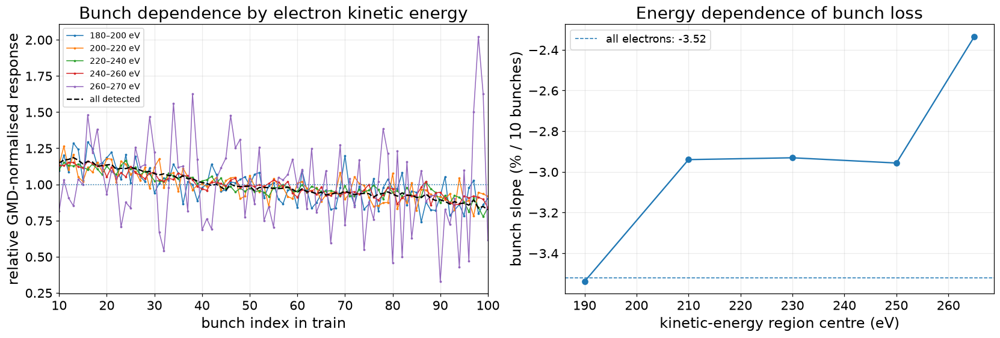

In [44]:
# --- Electron bunch dependence in separate kinetic-energy regions ---

KE_REGIONS = [(180,200),(200,220),(220,240),(240,260),(260,270)]

def load_electron_region_counts(path,regions,max_trains=None):
    counts = np.zeros((len(regions),n_trains,n_bunch),dtype=np.uint16)
    with h5py.File(path,"r") as handle:
        n_load = n_trains if max_trains is None else min(n_trains,int(max_trains))
        for start in range(0,n_load,INDEP_CHUNK_TRAINS):
            stop = min(start+INDEP_CHUNK_TRAINS,n_load)
            tof = handle["tofs_e"][start:stop]
            valid = tof > 0
            if not np.any(valid): continue
            ke = tof_to_ke(tof[valid])
            shot_index = np.flatnonzero(valid)//tof.shape[-1]
            for j,(lo,hi) in enumerate(regions):
                inside = (ke >= lo) & (ke < hi)
                counts[j,start:stop].flat[:] = np.bincount(shot_index[inside],minlength=(stop-start)*n_bunch)
    return counts

ke_region_counts = load_electron_region_counts(source_h5,KE_REGIONS,MAX_TRAINS)

def metrics_from_counts(counts):
    obs = band_sums(counts,gmd,current_mask)
    norm = band_sums(gmd,gmd,current_mask)
    shots = band_sums(np.ones_like(gmd),gmd,current_mask)
    return bunch_metrics(obs,norm,shots),shots

def combined_relative_profile(metrics,shots):
    r = metrics["relative"]
    valid = np.isfinite(r) & (shots > 0)
    num = np.sum(np.where(valid,r*shots,0),axis=0)
    den = np.sum(np.where(valid,shots,0),axis=0)
    return np.divide(num,den,out=np.full(n_bunch,np.nan),where=den > 0)

ke_rows = []
ke_profiles = {}

for j,(lo,hi) in enumerate(KE_REGIONS):
    m,shots = metrics_from_counts(ke_region_counts[j])
    ke_profiles[(lo,hi)] = combined_relative_profile(m,shots)
    ke_rows.append({"KE region":f"{lo:g}–{hi:g} eV","slope (% / 10 bunches)":m["slope"],"flatness":m["flatness"],
                    "total electrons":int(ke_region_counts[j].sum())})

m_total,shots_total = metrics_from_counts(data["total_electrons"])
total_profile = combined_relative_profile(m_total,shots_total)
ke_rows.append({"KE region":"all detected","slope (% / 10 bunches)":m_total["slope"],"flatness":m_total["flatness"],
                "total electrons":int(data["total_electrons"].sum())})

display(pd.DataFrame(ke_rows).set_index("KE region").round(5))

fig,axes = plt.subplots(1,2,figsize=(15,5),constrained_layout=True)

for (lo,hi),profile in ke_profiles.items(): axes[0].plot(bunch,profile,".-",ms=3,lw=1,label=f"{lo:g}–{hi:g} eV")
axes[0].plot(bunch,total_profile,"k--",lw=1.5,label="all detected")
axes[0].axhline(1,ls=":",lw=1)
axes[0].set_xlim(INDEP_BUNCH_START,n_bunch-1)
axes[0].set(xlabel="bunch index in train",ylabel="relative GMD-normalised response",title="Bunch dependence by electron kinetic energy")
axes[0].grid(alpha=0.25); axes[0].legend(fontsize=9)

centres = [(lo+hi)/2 for lo,hi in KE_REGIONS]
slopes = [ke_rows[j]["slope (% / 10 bunches)"] for j in range(len(KE_REGIONS))]
axes[1].plot(centres,slopes,"o-")
axes[1].axhline(m_total["slope"],ls="--",lw=1,label=f"all electrons: {m_total['slope']:+.2f}")
axes[1].set(xlabel="kinetic-energy region centre (eV)",ylabel="bunch slope (% / 10 bunches)",title="Energy dependence of bunch loss")
axes[1].grid(alpha=0.25); axes[1].legend()

plt.show()

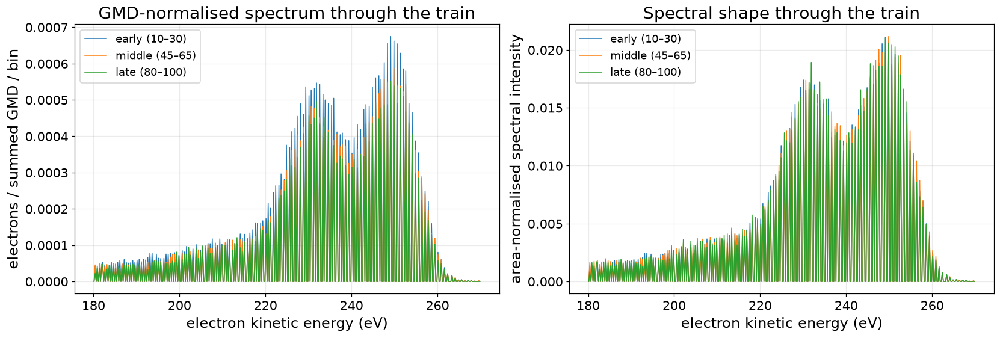

In [45]:
# --- Electron spectrum versus bunch position at fixed moderate GMD ---

SPECTRAL_GMD_RANGE = (3.0,6.0)
SPECTRAL_KE_EDGES = np.arange(180.0,270.25,0.25)
SPECTRAL_KE_CENTRES = 0.5*(SPECTRAL_KE_EDGES[:-1]+SPECTRAL_KE_EDGES[1:])
spectral_selected = current_mask & (gmd >= SPECTRAL_GMD_RANGE[0]) & (gmd < SPECTRAL_GMD_RANGE[1])

def load_ke_hist_by_bunch(path,selected):
    hist = np.zeros((n_bunch,len(SPECTRAL_KE_EDGES)-1),dtype=np.int64)
    with h5py.File(path,"r") as handle:
        for start in range(0,n_trains,INDEP_CHUNK_TRAINS):
            stop = min(start+INDEP_CHUNK_TRAINS,n_trains)
            tof = handle["tofs_e"][start:stop]
            valid = (tof > 0) & selected[start:stop,:,None]
            if not np.any(valid): continue
            flat = np.flatnonzero(valid)
            shot_index = flat//tof.shape[-1]
            bunch_index = shot_index % n_bunch
            ke = tof_to_ke(tof.reshape(-1)[flat])
            good = np.isfinite(ke)
            h,_,_ = np.histogram2d(bunch_index[good],ke[good],
                                   bins=[np.arange(-0.5,n_bunch+0.5,1),SPECTRAL_KE_EDGES])
            hist += h.astype(np.int64)
    return hist

ke_hist_bunch = load_ke_hist_by_bunch(source_h5,spectral_selected)
spectral_gmd_sum = np.sum(np.where(spectral_selected,gmd,0),axis=0)

BUNCH_GROUPS = {"early (10–30)":(10,30),"middle (45–65)":(45,65),"late (80–100)":(80,100)}

fig,axes = plt.subplots(1,2,figsize=(15,5),constrained_layout=True)

for label,(lo,hi) in BUNCH_GROUPS.items():
    idx = np.arange(lo,hi+1)
    spectrum = ke_hist_bunch[idx].sum(axis=0)/spectral_gmd_sum[idx].sum()
    axes[0].plot(SPECTRAL_KE_CENTRES,spectrum,lw=1,label=label)
    area = spectrum.sum()
    axes[1].plot(SPECTRAL_KE_CENTRES,spectrum/area if area > 0 else spectrum,lw=1,label=label)

axes[0].set(xlabel="electron kinetic energy (eV)",ylabel="electrons / summed GMD / bin",title="GMD-normalised spectrum through the train")
axes[1].set(xlabel="electron kinetic energy (eV)",ylabel="area-normalised spectral intensity",title="Spectral shape through the train")
for ax in axes: ax.grid(alpha=0.25); ax.legend()
plt.show()

## Current GMD response
Fit the global reference-electron GMD-only line on the original `common` population in training train folds.
At selected bunch positions compare binned reference counts with global and local lines; fit independent bunch slopes on training trains.
These plots test whether one global GMD response describes the whole train.


In [46]:
# Existing linear-model fitting logic, using training reference counts.
beta_cv = {name:[] for name in ["M0"]}
for off in INDEP_CV_OFFSETS:
    training = common & ((train_ids % INDEP_CV_MOD) != off)[:,None]
    y = data["ref_counts"][training].astype(float)
    for name in ["M0"]:
        x = designs[name][training]
        beta_cv[name].append(np.linalg.lstsq(x.T @ x, x.T @ y, rcond=None)[0])
beta_cv = {name:np.asarray(beta) for name,beta in beta_cv.items()}
print("Mean reference-region coefficients across training folds:")
for name in ["M0"]:
    print(name, beta_cv[name].mean(axis=0))

Mean reference-region coefficients across training folds:
M0 [-0.00253342  0.00529093]


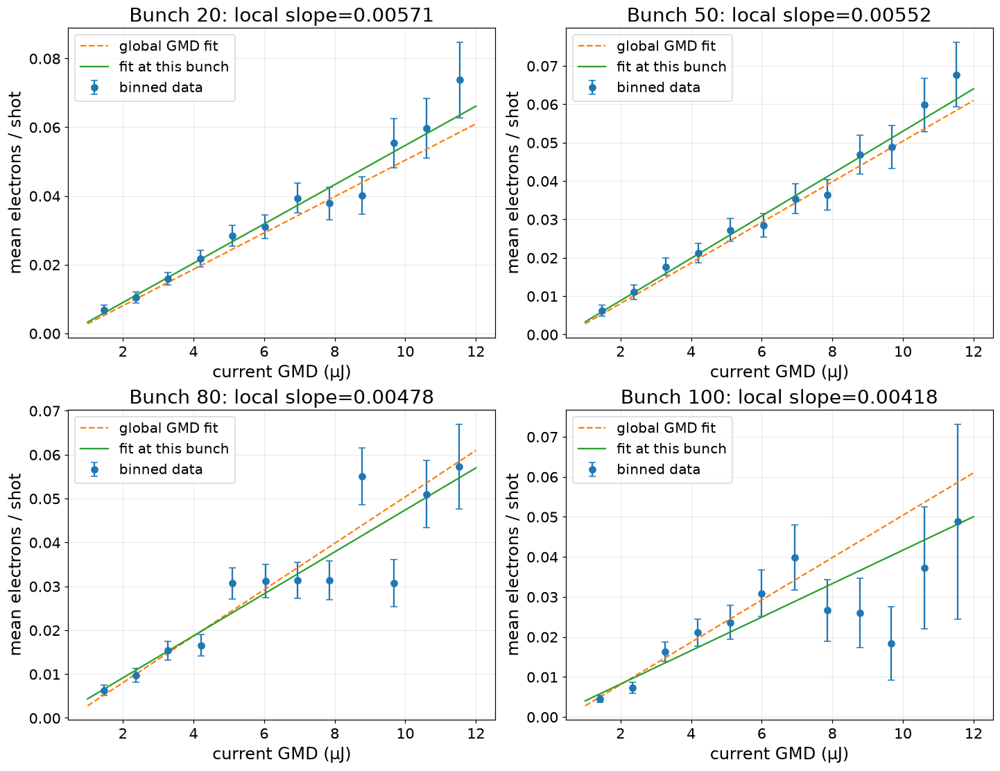

In [47]:
# --- Diagnostic: current reference-electron yield vs current GMD at different bunch positions ---

BUNCH_CHECKS = [20,50,80,100]
N_GMD_BINS = 12
g_grid = np.linspace(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1],200)
beta_mean = beta_cv["M0"].mean(axis=0)

fig,axes = plt.subplots(2,2,figsize=(13,10),constrained_layout=True)

for ax,bunch_pos in zip(axes.flat,BUNCH_CHECKS):
    valid = current_mask[:,bunch_pos]
    g = gmd[valid,bunch_pos]
    y = data["ref_counts"][valid,bunch_pos].astype(float)

    edges = np.linspace(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1],N_GMD_BINS+1)
    ibin = np.digitize(g,edges[1:-1])
    gx,ym,ye = [],[],[]
    for j in range(N_GMD_BINS):
        use = ibin == j
        if not np.any(use): continue
        gx.append(g[use].mean()); ym.append(y[use].mean()); ye.append(np.sqrt(y[use].sum())/use.sum())

    X = np.column_stack((np.ones_like(g),g))
    beta_local = np.linalg.lstsq(X,y,rcond=None)[0]

    ax.errorbar(gx,ym,yerr=ye,fmt="o",capsize=3,label="binned data")
    ax.plot(g_grid,beta_mean[0]+beta_mean[1]*g_grid,"--",lw=1.5,label="global GMD fit")
    ax.plot(g_grid,beta_local[0]+beta_local[1]*g_grid,"-",lw=1.5,label="fit at this bunch")
    ax.set(xlabel="current GMD (µJ)",ylabel="mean electrons / shot",title=f"Bunch {bunch_pos}: local slope={beta_local[1]:.5f}")
    ax.grid(alpha=0.25); ax.legend(fontsize=13)

plt.show()

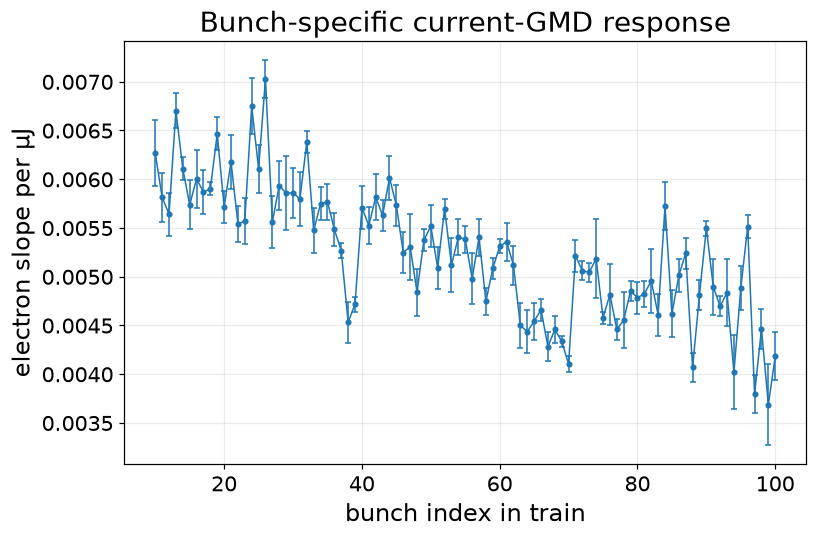

In [48]:
# --- Bunch-specific current-GMD baseline, fitted only on training trains ---

local_pred_cv = np.full_like(gmd,np.nan,dtype=float)
local_beta_cv = np.full((INDEP_CV_MOD,n_bunch,2),np.nan)

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off

    for b in range(INDEP_BUNCH_START,n_bunch):
        use_train = train_rows & current_mask[:,b]
        if np.count_nonzero(use_train) < 2: continue

        g_train = gmd[use_train,b]
        y_train = data["ref_counts"][use_train,b].astype(float)
        X = np.column_stack((np.ones_like(g_train),g_train))
        beta = np.linalg.lstsq(X,y_train,rcond=None)[0]
        local_beta_cv[off,b] = beta

        g_test = gmd[test_rows,b]
        local_pred_cv[test_rows,b] = beta[0]+beta[1]*g_test

# Diagnostic: mean fitted GMD slope at each bunch position.
mean_local_slope = np.full(n_bunch,np.nan); sd_local_slope = np.full(n_bunch,np.nan)
mean_local_slope[INDEP_BUNCH_START:] = np.nanmean(local_beta_cv[:,INDEP_BUNCH_START:,1],axis=0)
sd_local_slope[INDEP_BUNCH_START:] = np.nanstd(local_beta_cv[:,INDEP_BUNCH_START:,1],axis=0,ddof=1)
bunches_local = np.arange(INDEP_BUNCH_START,n_bunch)

fig,ax = plt.subplots(figsize=(8,5))
ax.errorbar(bunches_local,mean_local_slope[bunches_local],yerr=sd_local_slope[bunches_local],fmt="o-",ms=3,lw=1,capsize=2)
ax.set(xlabel="bunch index in train",ylabel="electron slope per µJ",title="Bunch-specific current-GMD response")
ax.grid(alpha=0.25)
plt.show()

## History and bunch position
Use DAQ-valid current shots and all earlier detected electrons within the same train, independent of earlier-shot GMD.
Compare the relative current reference/GMD profile with mean previous-five-shot total-electron load.
The figure tests whether history and bunch position have similar shapes and may be confounded.


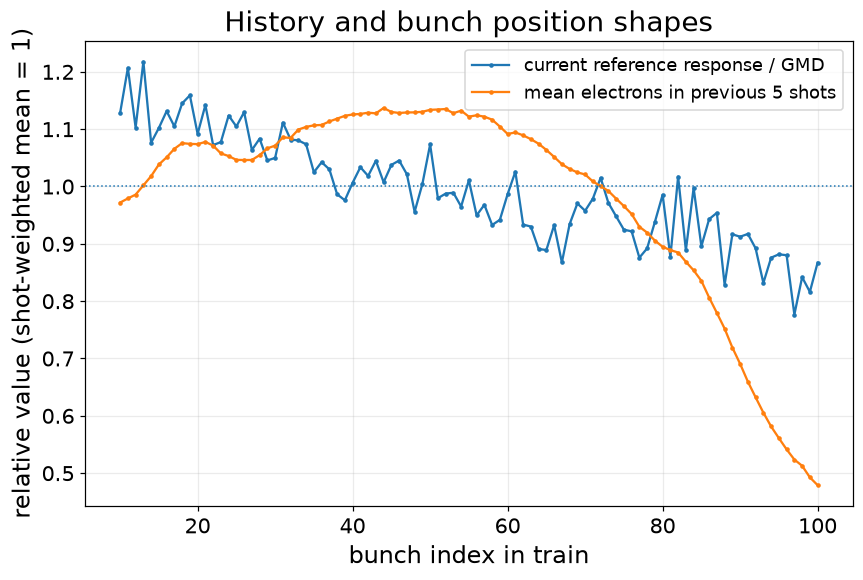

Correlation of the two bunch profiles: r=+0.6001


In [49]:
# --- Why history and bunch position are confounded ---

CONFOUND_HISTORY_SHOTS = 5

H_conf = np.full_like(gmd,np.nan,dtype=float)
for b in range(CONFOUND_HISTORY_SHOTS,n_bunch):
    H_conf[:,b] = data["total_electrons"][:,b-CONFOUND_HISTORY_SHOTS:b].sum(axis=1)

bunches_conf = np.arange(max(INDEP_BUNCH_START,CONFOUND_HISTORY_SHOTS),n_bunch)
response_conf = np.full(n_bunch,np.nan)
history_conf = np.full(n_bunch,np.nan)
shots_conf = np.zeros(n_bunch,dtype=int)

for b in bunches_conf:
    use = current_mask[:,b] & np.isfinite(H_conf[:,b])
    shots_conf[b] = np.count_nonzero(use)
    if shots_conf[b] == 0:
        continue
    response_conf[b] = data["ref_counts"][use,b].sum()/gmd[use,b].sum()
    history_conf[b] = np.mean(H_conf[use,b])

valid = np.isfinite(response_conf[bunches_conf]) & np.isfinite(history_conf[bunches_conf])
b = bunches_conf[valid]

response_rel = response_conf[b]/np.average(response_conf[b],weights=shots_conf[b])
history_rel = history_conf[b]/np.average(history_conf[b],weights=shots_conf[b])
r = np.corrcoef(response_rel,history_rel)[0,1]

fig,ax = plt.subplots(figsize=(9,5.5))
ax.plot(b,response_rel,".-",ms=4,lw=1.5,label="current reference response / GMD")
ax.plot(b,history_rel,".-",ms=4,lw=1.5,label=f"mean electrons in previous {CONFOUND_HISTORY_SHOTS} shots")
ax.axhline(1,ls=":",lw=1)
ax.set(xlabel="bunch index in train",ylabel="relative value (shot-weighted mean = 1)",title="History and bunch position shapes")
# ax.set(xlabel="bunch index in train",ylabel="relative value",title="History and bunch position shapes")
ax.grid(alpha=0.25); ax.legend()
plt.show()

print(f"Correlation of the two bunch profiles: r={r:+.4f}")

## Common-support zero-history test
Select current GMD 1–3 µJ and bunches from 20 onward, using identical support for windows of 1, 2, 3 and 5 shots.
Compare reference/GMD bunch slopes for all, zero-history and nonzero-history shots.
Uncertainty resamples whole train rows, preserving within-train dependence and the original bootstrap settings.


In [50]:
ref_counts = data["ref_counts"].astype(float)
total_electrons = data["total_electrons"].astype(float)
n_trains,n_bunch = gmd.shape

cum_e = np.concatenate((np.zeros((n_trains,1)),np.cumsum(total_electrons,axis=1)),axis=1)


,all slope,all SD,zero-history slope,zero SD,zero 95% low,zero 95% high,nonzero-history slope,nonzero SD
window,,,,,,,,
1,-2.0943,0.452,-2.1837,0.5513,-3.2971,-1.1991,-1.6111,0.8185
2,-2.0943,0.452,-2.1390,0.6593,-3.5045,-0.8187,-1.5704,0.7019
3,-2.0943,0.452,-1.4787,0.8311,-3.1287,0.3076,-2.0492,0.5329
5,-2.0943,0.452,-1.5094,1.0998,-3.8160,0.5497,-1.9939,0.4503


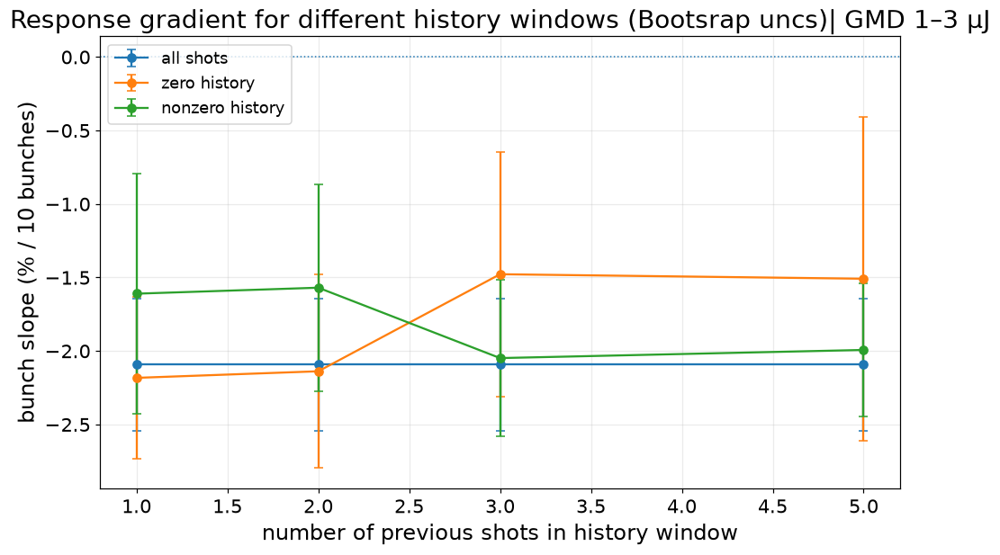

In [51]:
# --- Whole-train bootstrap uncertainties for the common-support zero-history scan ---

WINDOWS = [1,2,3,5]
COMMON_BUNCH_START = 10
GMD_TEST_RANGE = (1.0,3.0)
N_BOOT = 200
BOOT_SEED = 12345

rng = np.random.default_rng(BOOT_SEED)
bunches_boot = np.arange(COMMON_BUNCH_START,n_bunch)

def build_train_contributions(window,mode):
    num = np.zeros((n_trains,len(bunches_boot)),dtype=np.float32)
    den = np.zeros_like(num)

    for j,b in enumerate(bunches_boot):
        H = cum_e[:,b]-cum_e[:,b-window]
        sel = current_mask[:,b] & (gmd[:,b] >= GMD_TEST_RANGE[0]) & (gmd[:,b] < GMD_TEST_RANGE[1])

        if mode == "zero": sel &= H == 0
        elif mode == "nonzero": sel &= H > 0

        num[sel,j] = ref_counts[sel,b]
        den[sel,j] = gmd[sel,b]

    return num,den

def slope_from_sums(num_sum,den_sum):
    response = np.divide(num_sum,den_sum,out=np.full_like(num_sum,np.nan,dtype=float),where=den_sum > 0)
    valid = np.isfinite(response)
    if valid.sum() < 2: return np.nan
    y = response[valid]/np.nanmean(response[valid])
    x = bunches_boot[valid]
    return np.polyfit(x,y,1)[0]*1000

def bootstrap_slopes(num,den,n_boot=N_BOOT):
    slopes = np.full(n_boot,np.nan)

    for ib in range(n_boot):
        sampled = rng.integers(0,n_trains,n_trains)
        weights = np.bincount(sampled,minlength=n_trains).astype(np.float32)
        num_sum = weights @ num
        den_sum = weights @ den
        slopes[ib] = slope_from_sums(num_sum,den_sum)

    return slopes

boot_rows = []

# All-shot slope needs calculating only once because support is identical.
num_all,den_all = build_train_contributions(WINDOWS[0],"all")
all_nominal = slope_from_sums(num_all.sum(axis=0),den_all.sum(axis=0))
all_boot = bootstrap_slopes(num_all,den_all)

for window in WINDOWS:
    num_zero,den_zero = build_train_contributions(window,"zero")
    num_nonzero,den_nonzero = build_train_contributions(window,"nonzero")

    zero_nominal = slope_from_sums(num_zero.sum(axis=0),den_zero.sum(axis=0))
    nonzero_nominal = slope_from_sums(num_nonzero.sum(axis=0),den_nonzero.sum(axis=0))

    zero_boot = bootstrap_slopes(num_zero,den_zero)
    nonzero_boot = bootstrap_slopes(num_nonzero,den_nonzero)

    boot_rows.append({
        "window":window,
        "all slope":all_nominal,
        "all SD":np.nanstd(all_boot,ddof=1),
        "zero-history slope":zero_nominal,
        "zero SD":np.nanstd(zero_boot,ddof=1),
        "zero 95% low":np.nanpercentile(zero_boot,2.5),
        "zero 95% high":np.nanpercentile(zero_boot,97.5),
        "nonzero-history slope":nonzero_nominal,
        "nonzero SD":np.nanstd(nonzero_boot,ddof=1)
    })

bootstrap_table = pd.DataFrame(boot_rows).set_index("window")
display(bootstrap_table.round(4))

fig,ax = plt.subplots(figsize=(9,5.5),constrained_layout=True)

ax.errorbar(WINDOWS,bootstrap_table["all slope"],
            yerr=bootstrap_table["all SD"],fmt="o-",capsize=3,label="all shots")

ax.errorbar(WINDOWS,bootstrap_table["zero-history slope"],
            yerr=bootstrap_table["zero SD"],fmt="o-",capsize=3,label="zero history")

ax.errorbar(WINDOWS,bootstrap_table["nonzero-history slope"],
            yerr=bootstrap_table["nonzero SD"],fmt="o-",capsize=3,label="nonzero history")

ax.axhline(0,ls=":",lw=1)
ax.set_xlabel("number of previous shots in history window")
ax.set_ylabel("bunch slope (% / 10 bunches)")
ax.set_title(f"Response gradient for different history windows (Bootsrap uncs)| GMD {GMD_TEST_RANGE[0]:g}–{GMD_TEST_RANGE[1]:g} µJ")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

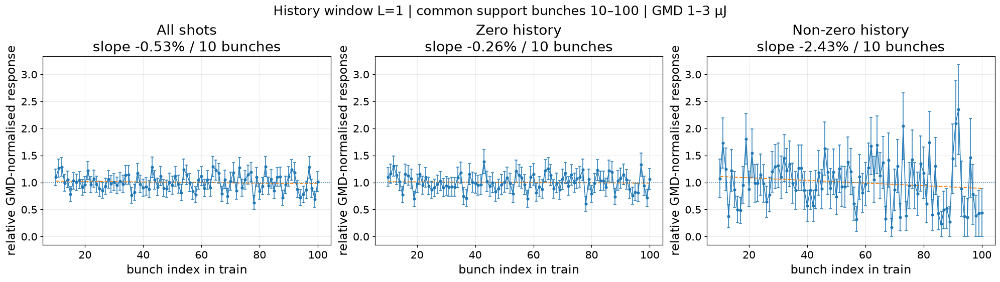


L = 1
all     : slope=-0.531% / 10 | shots=886,425 | median/bunch=9603 | min/bunch=8,614 | mean GMD early=1.962 µJ | late=1.830 µJ
zero    : slope=-0.264% / 10 | shots=742,709 | median/bunch=8249 | min/bunch=7,054 | mean GMD early=1.960 µJ | late=1.823 µJ
nonzero : slope=-2.430% / 10 | shots=143,716 | median/bunch=1638 | min/bunch=621 | mean GMD early=1.968 µJ | late=1.888 µJ


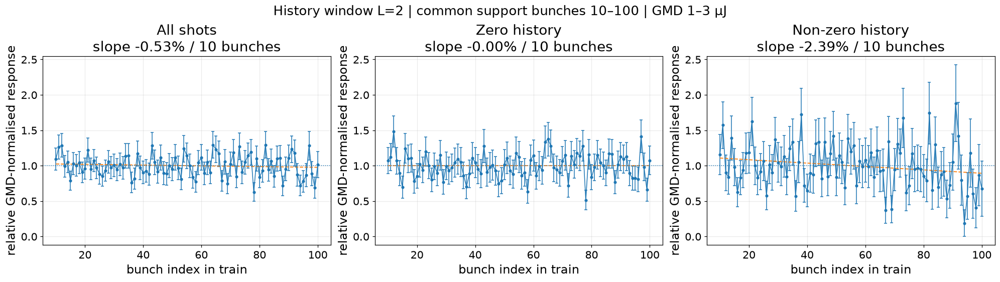


L = 2
all     : slope=-0.531% / 10 | shots=886,425 | median/bunch=9603 | min/bunch=8,614 | mean GMD early=1.962 µJ | late=1.830 µJ
zero    : slope=-0.000% / 10 | shots=626,306 | median/bunch=7061 | min/bunch=5,705 | mean GMD early=1.958 µJ | late=1.817 µJ
nonzero : slope=-2.388% / 10 | shots=260,119 | median/bunch=2932 | min/bunch=1,222 | mean GMD early=1.970 µJ | late=1.882 µJ


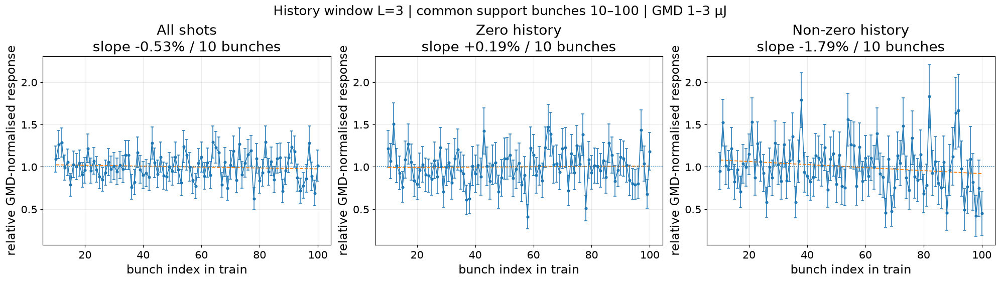


L = 3
all     : slope=-0.531% / 10 | shots=886,425 | median/bunch=9603 | min/bunch=8,614 | mean GMD early=1.962 µJ | late=1.830 µJ
zero    : slope=+0.194% / 10 | shots=530,690 | median/bunch=5900 | min/bunch=4,652 | mean GMD early=1.954 µJ | late=1.810 µJ
nonzero : slope=-1.787% / 10 | shots=355,735 | median/bunch=3995 | min/bunch=1,809 | mean GMD early=1.971 µJ | late=1.880 µJ


In [ ]:
# --- Inspect underlying bunch curves for the common-support history scan ---

INSPECT_WINDOWS = [1,2,3]  # change to [1,2] if only the first two are needed
INSPECT_MODES = ["all","zero","nonzero"]

titles = {
    "all":"All shots",
    "zero":"Zero history",
    "nonzero":"Non-zero history"
}

def inspect_history_curve(window,mode):
    # Use exactly the same train contributions / selections as the bootstrap analysis.
    num,den = build_train_contributions(window,mode)

    obs = num.sum(axis=0)
    gmd_sum = den.sum(axis=0)
    shots = np.count_nonzero(den > 0,axis=0)

    response = np.divide(obs,gmd_sum,out=np.full(len(bunches_boot),np.nan),where=gmd_sum > 0)
    error = np.divide(np.sqrt(obs),gmd_sum,out=np.full(len(bunches_boot),np.nan),where=gmd_sum > 0)

    valid = np.isfinite(response)
    mean_response = np.nanmean(response[valid])
    relative = response/mean_response
    relative_error = error/mean_response

    x = bunches_boot[valid]
    y = relative[valid]
    slope,intercept = np.polyfit(x,y,1)
    slope *= 1000  # % / 10 bunches

    mean_gmd = np.divide(gmd_sum,shots,out=np.full(len(bunches_boot),np.nan),where=shots > 0)

    return relative,relative_error,shots,mean_gmd,slope,intercept

for window in INSPECT_WINDOWS:
    results = {mode:inspect_history_curve(window,mode) for mode in INSPECT_MODES}

    fig,axes = plt.subplots(1,3,figsize=(18,5),constrained_layout=True)

    for ax,mode in zip(axes,INSPECT_MODES):
        response,error,shots,mean_gmd,slope,intercept = results[mode]
        valid = np.isfinite(response)

        ax.errorbar(bunches_boot[valid],response[valid],yerr=error[valid],
                    fmt="o-",ms=3,lw=1,capsize=2)

        xfit = np.array([bunches_boot[0],bunches_boot[-1]])
        ax.plot(xfit,intercept+(slope/1000)*xfit,"--",lw=1.2)

        ax.axhline(1,ls=":",lw=1)
        ax.set_xlabel("bunch index in train")
        ax.set_ylabel("relative GMD-normalised response")
        ax.set_title(f"{titles[mode]}\nslope {slope:+.2f}% / 10 bunches")
        ax.grid(alpha=0.25)

    # Same y-scale so the shapes can be compared directly.
    ymin = min(ax.get_ylim()[0] for ax in axes)
    ymax = max(ax.get_ylim()[1] for ax in axes)
    for ax in axes: ax.set_ylim(ymin,ymax)

    fig.suptitle(
        f"History window L={window} | common support bunches "
        f"{COMMON_BUNCH_START}–{n_bunch-1} | GMD "
        f"{GMD_TEST_RANGE[0]:g}–{GMD_TEST_RANGE[1]:g} µJ"
    )
    plt.show()

    print(f"\nL = {window}")
    for mode in INSPECT_MODES:
        response,error,shots,mean_gmd,slope,intercept = results[mode]
        n = len(shots)
        q = max(1,n//4)

        print(
            f"{mode:8s}: slope={slope:+.3f}% / 10 | "
            f"shots={shots.sum():,} | "
            f"median/bunch={np.median(shots):.0f} | "
            f"min/bunch={shots.min():,} | "
            f"mean GMD early={np.nanmean(mean_gmd[:q]):.3f} µJ | "
            f"late={np.nanmean(mean_gmd[-q:]):.3f} µJ"
        )

,slope (% / 10 bunches),shots
GMD range,,
1–2 µJ,0.6365,434629
2–3 µJ,-0.7166,338770
3–4 µJ,-1.0698,283273
4–6 µJ,-1.9103,418178
6–8 µJ,-2.7643,265881
8–12 µJ,-2.9694,260444


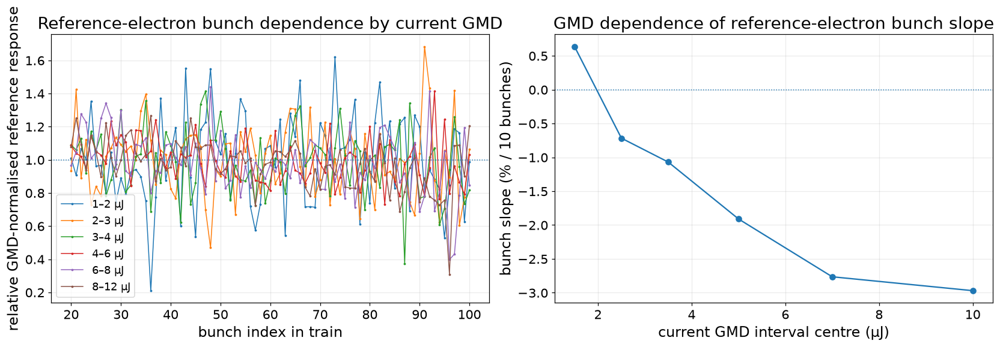

In [ ]:
# --- Reference-electron bunch dependence versus current GMD ---

GMD_SLOPE_BANDS = [(1,2),(2,3),(3,4),(4,6),(6,8),(8,12)]
GMD_SLOPE_BUNCH_START = 20

bunches_gmd = np.arange(GMD_SLOPE_BUNCH_START,n_bunch)
gmd_slope_rows = []
gmd_slope_curves = {}

# Deliberately construct the mask here rather than using current_mask so that
# the bunch range is controlled explicitly in this diagnostic.
base_valid = daq_valid_rows[:,None] & np.isfinite(gmd)

for lo,hi in GMD_SLOPE_BANDS:
    response = np.full(n_bunch,np.nan)
    error = np.full(n_bunch,np.nan)
    shots = np.zeros(n_bunch,dtype=int)

    for b in bunches_gmd:
        sel = (base_valid[:,b]
               & (gmd[:,b] >= lo)
               & (gmd[:,b] < hi))

        shots[b] = sel.sum()
        obs = ref_counts[sel,b].sum()
        norm = gmd[sel,b].sum()

        if norm > 0:
            response[b] = obs/norm
            error[b] = np.sqrt(obs)/norm

    # Normalise each GMD interval by its own summed response over the fit range.
    valid = np.isfinite(response[bunches_gmd]) & (shots[bunches_gmd] > 0)
    scale = (
        np.sum([
            ref_counts[
                base_valid[:,b]
                & (gmd[:,b] >= lo)
                & (gmd[:,b] < hi),
                b
            ].sum()
            for b in bunches_gmd
        ])
        /
        np.sum([
            gmd[
                base_valid[:,b]
                & (gmd[:,b] >= lo)
                & (gmd[:,b] < hi),
                b
            ].sum()
            for b in bunches_gmd
        ])
    )

    relative = response/scale
    relative_error = error/scale

    x = bunches_gmd[valid]
    y = relative[bunches_gmd][valid]
    w = shots[bunches_gmd][valid]

    x0 = np.average(x,weights=w)
    y0 = np.average(y,weights=w)
    slope_raw = np.sum(w*(x-x0)*(y-y0))/np.sum(w*(x-x0)**2)
    intercept = y0-slope_raw*x0
    slope = 1000*slope_raw

    gmd_slope_curves[(lo,hi)] = (relative,relative_error,shots,slope,intercept)
    gmd_slope_rows.append({
        "GMD range":f"{lo:g}–{hi:g} µJ",
        "slope (% / 10 bunches)":slope,
        "shots":int(shots[bunches_gmd].sum())
    })

gmd_slope_table = pd.DataFrame(gmd_slope_rows).set_index("GMD range")
display(gmd_slope_table.round(4))

fig,axes = plt.subplots(1,2,figsize=(15,5),constrained_layout=True)

for (lo,hi),(response,error,shots,slope,intercept) in gmd_slope_curves.items():
    valid = np.isfinite(response[bunches_gmd])

    axes[0].plot(
        bunches_gmd[valid],response[bunches_gmd][valid],
        ".-",ms=3,lw=1,label=f"{lo:g}–{hi:g} µJ"
    )

axes[0].axhline(1,ls=":",lw=1)
axes[0].set(
    xlabel="bunch index in train",
    ylabel="relative GMD-normalised reference response",
    title="Reference-electron bunch dependence by current GMD"
)
axes[0].grid(alpha=0.25)
axes[0].legend()

centres = [(lo+hi)/2 for lo,hi in GMD_SLOPE_BANDS]
slopes = [gmd_slope_curves[(lo,hi)][3] for lo,hi in GMD_SLOPE_BANDS]

axes[1].plot(centres,slopes,"o-")
axes[1].axhline(0,ls=":",lw=1)
axes[1].set(
    xlabel="current GMD interval centre (µJ)",
    ylabel="bunch slope (% / 10 bunches)",
    title="GMD dependence of reference-electron bunch slope"
)
axes[1].grid(alpha=0.25)

plt.show()

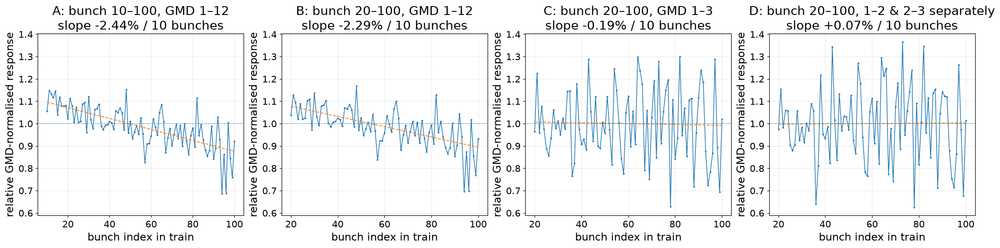

A: bunch 10–100, GMD 1–12: -2.444% / 10
B: bunch 20–100, GMD 1–12: -2.293% / 10
C: bunch 20–100, GMD 1–3 : -0.193% / 10
D: 1–2 and 2–3 separately : +0.067% / 10


In [ ]:
# --- Diagnose why the common-support history sample is much flatter ---

def pooled_reference_curve(bunch_start,gmd_range):
    bunches_test = np.arange(bunch_start,n_bunch)

    response = np.full(n_bunch,np.nan)
    error = np.full(n_bunch,np.nan)
    shots = np.zeros(n_bunch,dtype=int)

    for b in bunches_test:
        sel = (daq_valid_rows
               & np.isfinite(gmd[:,b])
               & (gmd[:,b] >= gmd_range[0])
               & (gmd[:,b] < gmd_range[1]))

        shots[b] = sel.sum()
        obs = ref_counts[sel,b].sum()
        norm = gmd[sel,b].sum()

        if norm > 0:
            response[b] = obs/norm
            error[b] = np.sqrt(obs)/norm

    # Same summed-count / summed-GMD normalisation over the chosen bunch range.
    valid = np.isfinite(response[bunches_test]) & (shots[bunches_test] > 0)

    total_obs = 0.0
    total_norm = 0.0
    for b in bunches_test:
        sel = (daq_valid_rows
               & np.isfinite(gmd[:,b])
               & (gmd[:,b] >= gmd_range[0])
               & (gmd[:,b] < gmd_range[1]))
        total_obs += ref_counts[sel,b].sum()
        total_norm += gmd[sel,b].sum()

    scale = total_obs/total_norm
    relative = response/scale
    relative_error = error/scale

    x = bunches_test[valid]
    y = relative[bunches_test][valid]
    w = shots[bunches_test][valid]

    x0 = np.average(x,weights=w)
    y0 = np.average(y,weights=w)
    slope_raw = np.sum(w*(x-x0)*(y-y0))/np.sum(w*(x-x0)**2)
    intercept = y0-slope_raw*x0

    return bunches_test,relative,relative_error,shots,1000*slope_raw,intercept


def split_low_gmd_curve(bunch_start=0):
    # Treat 1–2 and 2–3 µJ separately, exactly to test whether pooling them
    # produces an artificial change in bunch slope.
    bands = [(1,2),(2,3)]
    bunches_test = np.arange(bunch_start,n_bunch)

    band_relative = []
    band_shots = []

    for lo,hi in bands:
        b,response,error,shots,slope,intercept = pooled_reference_curve(
            bunch_start,(lo,hi)
        )
        band_relative.append(response)
        band_shots.append(shots)

    band_relative = np.array(band_relative)
    band_shots = np.array(band_shots)

    valid = np.isfinite(band_relative) & (band_shots > 0)
    num = np.sum(np.where(valid,band_relative*band_shots,0.0),axis=0)
    den = np.sum(np.where(valid,band_shots,0.0),axis=0)

    combined = np.divide(
        num,den,
        out=np.full(n_bunch,np.nan),
        where=den > 0
    )

    shots = den
    valid_fit = np.isfinite(combined[bunches_test]) & (shots[bunches_test] > 0)

    x = bunches_test[valid_fit]
    y = combined[bunches_test][valid_fit]
    w = shots[bunches_test][valid_fit]

    x0 = np.average(x,weights=w)
    y0 = np.average(y,weights=w)
    slope_raw = np.sum(w*(x-x0)*(y-y0))/np.sum(w*(x-x0)**2)
    intercept = y0-slope_raw*x0

    return bunches_test,combined,shots,1000*slope_raw,intercept


tests = {
    "A: bunch 10–100, GMD 1–12":pooled_reference_curve(10,(1,12)),
    "B: bunch 20–100, GMD 1–12":pooled_reference_curve(20,(1,12)),
    "C: bunch 20–100, GMD 1–3":pooled_reference_curve(20,(1,3))
}

b_split,r_split,s_split,m_split,c_split = split_low_gmd_curve(20)

fig,axes = plt.subplots(1,4,figsize=(20,5),constrained_layout=True)

for ax,(title,result) in zip(axes[:3],tests.items()):
    b,response,error,shots,slope,intercept = result
    valid = np.isfinite(response[b])

    ax.plot(b[valid],response[b][valid],".-",ms=3,lw=1)
    xfit = np.array([b[0],b[-1]])
    ax.plot(xfit,intercept+(slope/1000)*xfit,"--",lw=1.2)

    ax.axhline(1,ls=":",lw=1)
    ax.set(
        xlabel="bunch index in train",
        ylabel="relative GMD-normalised response",
        title=f"{title}\nslope {slope:+.2f}% / 10 bunches"
    )
    ax.grid(alpha=0.25)

valid = np.isfinite(r_split[b_split])
axes[3].plot(b_split[valid],r_split[b_split][valid],".-",ms=3,lw=1)
xfit = np.array([b_split[0],b_split[-1]])
axes[3].plot(xfit,c_split+(m_split/1000)*xfit,"--",lw=1.2)
axes[3].axhline(1,ls=":",lw=1)
axes[3].set(
    xlabel="bunch index in train",
    ylabel="relative GMD-normalised response",
    title=f"D: bunch 20–100, 1–2 & 2–3 separately\n"
          f"slope {m_split:+.2f}% / 10 bunches"
)
axes[3].grid(alpha=0.25)

# Same y scale for direct visual comparison.
ymin = min(ax.get_ylim()[0] for ax in axes)
ymax = max(ax.get_ylim()[1] for ax in axes)
for ax in axes:
    ax.set_ylim(ymin,ymax)

plt.show()

print("A: bunch 10–100, GMD 1–12:",f"{tests['A: bunch 10–100, GMD 1–12'][4]:+.3f}% / 10")
print("B: bunch 20–100, GMD 1–12:",f"{tests['B: bunch 20–100, GMD 1–12'][4]:+.3f}% / 10")
print("C: bunch 20–100, GMD 1–3 :",f"{tests['C: bunch 20–100, GMD 1–3'][4]:+.3f}% / 10")
print("D: 1–2 and 2–3 separately :",f"{m_split:+.3f}% / 10")

,shots,mean GMD (µJ),fit intercept (e/shot),fit slope (e/shot/µJ)
bunch group,,,,
early (10–30),602279,4.372730,-0.001713,0.002824
middle (45–65),578811,4.831528,-0.001389,0.002521
late (80–100),363574,3.456129,-0.000813,0.002310


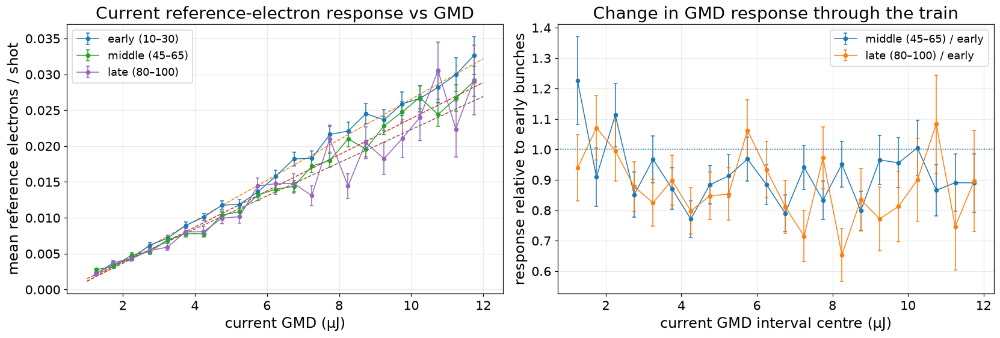

In [ ]:
# --- Current reference-electron response vs GMD through the bunch train ---

REF_GMD_RANGE = (1.0,12.0)
REF_GMD_BIN_STEP = 0.5

BUNCH_GROUPS = {
    "early (10–30)":(10,30),
    "middle (45–65)":(45,65),
    "late (80–100)":(80,100),
}

ref_counts = data["ref_counts"].astype(float)

gmd_edges = np.arange(
    REF_GMD_RANGE[0],
    REF_GMD_RANGE[1]+REF_GMD_BIN_STEP,
    REF_GMD_BIN_STEP
)
gmd_centres = 0.5*(gmd_edges[:-1]+gmd_edges[1:])

group_results = {}
summary_rows = []

for label,(b0,b1) in BUNCH_GROUPS.items():
    bunch_sel = (
        (np.arange(n_bunch)[None,:] >= b0)
        & (np.arange(n_bunch)[None,:] <= b1)
    )

    sel = (
        daq_valid_rows[:,None]
        & bunch_sel
        & np.isfinite(gmd)
        & (gmd >= REF_GMD_RANGE[0])
        & (gmd < REF_GMD_RANGE[1])
    )

    g = gmd[sel]
    y = ref_counts[sel]

    # Linear fit to the individual shots, not to the binned means.
    slope,intercept = np.polyfit(g,y,1)

    mean_response = np.full(len(gmd_centres),np.nan)
    response_error = np.full(len(gmd_centres),np.nan)
    mean_gmd = np.full(len(gmd_centres),np.nan)
    n_shots = np.zeros(len(gmd_centres),dtype=int)

    for j,(lo,hi) in enumerate(zip(gmd_edges[:-1],gmd_edges[1:])):
        m = (g >= lo) & (g < hi)
        n_shots[j] = m.sum()

        if n_shots[j] == 0:
            continue

        obs = y[m].sum()
        mean_response[j] = obs/n_shots[j]
        response_error[j] = np.sqrt(obs)/n_shots[j]
        mean_gmd[j] = g[m].mean()

    group_results[label] = {
        "g":g,
        "y":y,
        "mean_gmd":mean_gmd,
        "mean_response":mean_response,
        "response_error":response_error,
        "n_shots":n_shots,
        "slope":slope,
        "intercept":intercept,
    }

    summary_rows.append({
        "bunch group":label,
        "shots":g.size,
        "mean GMD (µJ)":g.mean(),
        "fit intercept (e/shot)":intercept,
        "fit slope (e/shot/µJ)":slope,
    })

display(pd.DataFrame(summary_rows).set_index("bunch group").round(6))


# --- Plot raw response and relative response to the early group ---

fig,axes = plt.subplots(1,2,figsize=(15,5),constrained_layout=True)

for label,result in group_results.items():
    valid = (
        np.isfinite(result["mean_gmd"])
        & np.isfinite(result["mean_response"])
    )

    axes[0].errorbar(
        result["mean_gmd"][valid],
        result["mean_response"][valid],
        yerr=result["response_error"][valid],
        fmt="o-",
        ms=4,
        lw=1,
        capsize=2,
        label=label
    )

    xfit = np.array(REF_GMD_RANGE)
    axes[0].plot(
        xfit,
        result["intercept"]+result["slope"]*xfit,
        "--",
        lw=1
    )

axes[0].set(
    xlabel="current GMD (µJ)",
    ylabel="mean reference electrons / shot",
    title="Current reference-electron response vs GMD"
)
axes[0].grid(alpha=0.25)
axes[0].legend()


# Compare each later bunch group directly with the early-group response
early = group_results["early (10–30)"]

for label in ["middle (45–65)","late (80–100)"]:
    result = group_results[label]

    valid = (
        np.isfinite(early["mean_response"])
        & np.isfinite(result["mean_response"])
        & (early["mean_response"] > 0)
        & (result["mean_response"] > 0)
    )

    ratio = result["mean_response"][valid]/early["mean_response"][valid]

    ratio_error = ratio*np.sqrt(
        (result["response_error"][valid]/result["mean_response"][valid])**2
        + (early["response_error"][valid]/early["mean_response"][valid])**2
    )

    axes[1].errorbar(
        gmd_centres[valid],
        ratio,
        yerr=ratio_error,
        fmt="o-",
        ms=4,
        lw=1,
        capsize=2,
        label=f"{label} / early"
    )

axes[1].axhline(1,ls=":",lw=1)
axes[1].set(
    xlabel="current GMD interval centre (µJ)",
    ylabel="response relative to early bunches",
    title="Change in GMD response through the train"
)
axes[1].grid(alpha=0.25)
axes[1].legend()

plt.show()

## Run slope comparison

In [14]:
# --- Multi-run comparison configuration ---

# Each key is (run group, photon energy).
# The group name is arbitrary but should distinguish physically different runs,
# e.g. temperature, long/short acquisition, repeat scan, etc.
#
# This structure deliberately allows the same photon energy to appear in
# multiple groups, so e.g. 150 C and 147 C runs can both be compared.

RUN_FILES = {
    ("150C_long",271.0): "glycine_delay_scan_150C_long_271.0eV_aggregates_tr_etof1.h5",
    ("150C_long",271.5): "glycine_delay_scan_150C_long_271.5eV_aggregates_tr_etof1.h5",
    ("150C_long",272.0): "glycine_delay_scan_150C_long_272.0eV_aggregates_tr_etof1.h5",

    ("150C",272.5): "glycine_delay_scan_150C_272.5eV_aggregates_tr_etof1.h5",
    ("150C",273.0): "glycine_delay_scan_150C_273.0eV_aggregates_tr_etof1.h5",
    ("150C",273.5): "glycine_delay_scan_150C_273.5eV_aggregates_tr_etof1.h5",
    ("150C",274.0): "glycine_delay_scan_150C_274.0eV_aggregates_tr_etof1.h5",
    ("150C",274.5): "glycine_delay_scan_150C_274.5eV_aggregates_tr_etof1.h5",
    ("150C",275.0): "glycine_delay_scan_150C_275.0eV_aggregates_tr_etof1.h5",

    # Add the 147 C runs here using their actual filenames, for example:
    ("147C",274.0): "glycine_delay_scan_7June_147C_274.0eV_aggregates_tr_etof1.h5",
    ("147C",274.5): "glycine_delay_scan_7June_147C_274.5eV_aggregates_tr_etof1.h5",
    ("147C",275.0): "glycine_delay_scan_7June_147C_275.0eV_aggregates_tr_etof1.h5",
    ("147C",275.5): "glycine_delay_scan_7June_147C_275.5eV_aggregates_tr_etof1.h5",
    ("147C",276.0): "glycine_delay_scan_7June_147C_276.0eV_aggregates_tr_etof1.h5",
}

# Choose exactly which runs to analyse.
# You can include both entries at the same photon energy.
SELECT_RUNS = [
    ("150C_long",271.0),
    ("150C_long",271.5),
    ("150C_long",272.0),
    ("150C",272.5),
    ("150C",273.0),
    ("150C",273.5),
    ("150C",274.0),
    ("150C",274.5),
    ("150C",275.0),

    ("147C",274.0),
    ("147C",274.5),
    ("147C",275.0),
    ("147C",275.5),
    ("147C",276.0),

    # Example when you want both temperatures:
    # ("147C",271.0),
]

MULTIRUN_MAX_TRAINS = None

# Reference-electron region is deliberately fixed across runs.
MULTIRUN_REF_KE_RANGE = (30.0,270.0)

# Use the same standard bunch range as the main bunch-dependence analysis.
MULTIRUN_BUNCH_START = 0

# Existing notebook-style bands used for the single overall bunch slope.
RUN_SLOPE_GMD_BANDS = [
    (1.0,2.0),
    (3.0,4.0),
    (5.0,6.0),
    (6.0,8.0),
    (8.0,12.0),
]

# Finer/contiguous bands for explicitly studying GMD dependence.
GMD_SLOPE_BANDS = [
    (1.0,2.0),
    (2.0,3.0),
    (3.0,4.0),
    (4.0,6.0),
    (6.0,8.0),
    (8.0,12.0),
]

missing = [key for key in SELECT_RUNS if key not in RUN_FILES]
if missing:
    raise KeyError(f"Selected runs missing from RUN_FILES: {missing}")

print("Selected runs:")
for key in SELECT_RUNS:
    print(f"  {key[0]:12s}  {key[1]:5.1f} eV  ->  {RUN_FILES[key]}")

Selected runs:
  150C_long     271.0 eV  ->  glycine_delay_scan_150C_long_271.0eV_aggregates_tr_etof1.h5
  150C_long     271.5 eV  ->  glycine_delay_scan_150C_long_271.5eV_aggregates_tr_etof1.h5
  150C_long     272.0 eV  ->  glycine_delay_scan_150C_long_272.0eV_aggregates_tr_etof1.h5
  150C          272.5 eV  ->  glycine_delay_scan_150C_272.5eV_aggregates_tr_etof1.h5
  150C          273.0 eV  ->  glycine_delay_scan_150C_273.0eV_aggregates_tr_etof1.h5
  150C          273.5 eV  ->  glycine_delay_scan_150C_273.5eV_aggregates_tr_etof1.h5
  150C          274.0 eV  ->  glycine_delay_scan_150C_274.0eV_aggregates_tr_etof1.h5
  150C          274.5 eV  ->  glycine_delay_scan_150C_274.5eV_aggregates_tr_etof1.h5
  150C          275.0 eV  ->  glycine_delay_scan_150C_275.0eV_aggregates_tr_etof1.h5
  147C          274.0 eV  ->  glycine_delay_scan_7June_147C_274.0eV_aggregates_tr_etof1.h5
  147C          274.5 eV  ->  glycine_delay_scan_7June_147C_274.5eV_aggregates_tr_etof1.h5
  147C          275.0 e

In [15]:
# --- Compact multi-run loader: GMD + electron and ion counts ---
ION_TOF_RANGE = (0,50000)
ION_TOF_MAIN_RANGE = (300,50000)

def load_reference_run(agg_filename,max_trains=None):
    agg_path = AGG_DIR / agg_filename
    if not agg_path.exists():
        raise FileNotFoundError(agg_path)

    agg_info = load_aggregate_info(agg_path)
    input_h5 = agg_info["metadata"].get("input_h5","")
    if not input_h5:
        raise ValueError(f"{agg_path.name} has no input_h5 metadata.")

    source_path = Path(input_h5)

    with h5py.File(source_path,"r") as handle:
        n_trains,n_bunch_run = handle["gmd"].shape
        if max_trains is not None:
            n_trains = min(n_trains,int(max_trains))

        if "tofs_i" not in handle:
            raise KeyError(f"{source_path.name}: tofs_i dataset is missing.")
        if handle["tofs_i"].ndim != 3 or handle["tofs_i"].shape[:2] != handle["gmd"].shape:
            raise ValueError(f"{source_path.name}: unexpected tofs_i shape {handle['tofs_i'].shape}.")

        gmd_run = np.empty((n_trains,n_bunch_run),dtype=float)
        ref_run = np.zeros((n_trains,n_bunch_run),dtype=np.uint16)
        total_e_run = np.zeros((n_trains,n_bunch_run),dtype=np.uint32)
        ion_run = np.zeros((n_trains,n_bunch_run),dtype=np.uint32)
        ion_main_run = np.zeros((n_trains,n_bunch_run),dtype=np.uint32)

        for start in range(0,n_trains,INDEP_CHUNK_TRAINS):
            stop = min(start+INDEP_CHUNK_TRAINS,n_trains)
            gmd_run[start:stop] = handle["gmd"][start:stop]

            # Electron counts: selected KE region and all detected hits.
            tof = handle["tofs_e"][start:stop]
            valid = tof > 0
            total_e_run[start:stop] = np.count_nonzero(valid,axis=-1)

            if np.any(valid):
                ke = tof_to_ke(tof[valid])
                flat_index = np.flatnonzero(valid)//tof.shape[-1]
                inside = (ke >= MULTIRUN_REF_KE_RANGE[0]) & (ke < MULTIRUN_REF_KE_RANGE[1])
                ref_run[start:stop].flat[:] = np.bincount(flat_index[inside],minlength=(stop-start)*n_bunch_run)

            del tof,valid

            # Ion counts: all positive TOF hits and the main spectral region.
            tof_i = handle["tofs_i"][start:stop]
            valid_ion = (tof_i > ION_TOF_RANGE[0]) & (tof_i < ION_TOF_RANGE[1])
            ion_run[start:stop] = np.count_nonzero(valid_ion,axis=-1)
            ion_main_run[start:stop] = np.count_nonzero(valid_ion & (tof_i >= ION_TOF_MAIN_RANGE[0]),axis=-1)
            del tof_i,valid_ion

        if "local_DAQ_running" not in handle or "between_tdc_files" not in handle:
            raise KeyError(f"{source_path.name}: DAQ-clean flags are missing.")

        local_daq_run = handle["local_DAQ_running"][:n_trains].astype(bool)
        between_tdc_run = handle["between_tdc_files"][:n_trains].astype(bool)

    daq_valid_run = local_daq_run & ~between_tdc_run

    return {
        "agg_path":agg_path,
        "source_h5":source_path,
        "gmd":gmd_run,
        "ref_counts":ref_run,
        "total_electrons":total_e_run,
        "ion_counts":ion_run,
        "ion_counts_main":ion_main_run,
        "daq_valid_rows":daq_valid_run,
        "n_trains":n_trains,
        "n_bunch":n_bunch_run,
    }


RUN_DATA = {}

for key in SELECT_RUNS:
    group,energy = key
    print(f"Loading {group}, {energy:.1f} eV ...")

    RUN_DATA[key] = load_reference_run(RUN_FILES[key],max_trains=MULTIRUN_MAX_TRAINS)

    d = RUN_DATA[key]
    print(
        f"  {d['n_trains']:,} trains × {d['n_bunch']} bunches; "
        f"DAQ-valid trains {d['daq_valid_rows'].mean():.2%}"
    )

Loading 150C_long, 271.0 eV ...
  34,625 trains × 101 bunches; DAQ-valid trains 97.47%
Loading 150C_long, 271.5 eV ...
  35,025 trains × 101 bunches; DAQ-valid trains 98.12%
Loading 150C_long, 272.0 eV ...
  34,285 trains × 101 bunches; DAQ-valid trains 98.42%
Loading 150C, 272.5 eV ...
  34,219 trains × 101 bunches; DAQ-valid trains 95.83%
Loading 150C, 273.0 eV ...
  36,010 trains × 101 bunches; DAQ-valid trains 90.82%
Loading 150C, 273.5 eV ...
  33,577 trains × 101 bunches; DAQ-valid trains 97.97%
Loading 150C, 274.0 eV ...
  33,711 trains × 101 bunches; DAQ-valid trains 97.27%
Loading 150C, 274.5 eV ...
  34,687 trains × 101 bunches; DAQ-valid trains 94.30%
Loading 150C, 275.0 eV ...
  35,439 trains × 101 bunches; DAQ-valid trains 92.55%
Loading 147C, 274.0 eV ...
  27,291 trains × 101 bunches; DAQ-valid trains 96.74%
Loading 147C, 274.5 eV ...
  34,147 trains × 101 bunches; DAQ-valid trains 96.65%
Loading 147C, 275.0 eV ...
  34,933 trains × 101 bunches; DAQ-valid trains 94.76%
L

In [16]:
# --- Check ion counts in the newly loaded RUN_DATA ---
ION_CHECK_RUN = ("150C",274.0)
run = RUN_DATA[ION_CHECK_RUN]

valid = run["daq_valid_rows"][:,None] & np.isfinite(run["gmd"]) & (run["gmd"] >= 4) & (run["gmd"] < 6)
n_shots = valid.sum()
n_e = run["ref_counts"][valid].sum()
n_i_all = run["ion_counts"][valid].sum()
n_i_main = run["ion_counts_main"][valid].sum()

print(f"Run: {ION_CHECK_RUN}")
print(f"Selected shots: {n_shots:,}")
print(f"Electrons / shot: {n_e/n_shots:.5f}")
print(f"Ions / shot, TOF 0–50000: {n_i_all/n_shots:.5f}")
print(f"Ions / shot, TOF 300–50000: {n_i_main/n_shots:.5f}")
print(f"Fraction of selected ion hits in main region: {100*n_i_main/n_i_all:.2f}%")

Run: ('150C', 274.0)
Selected shots: 682,589
Electrons / shot: 0.06169
Ions / shot, TOF 0–50000: 0.50331
Ions / shot, TOF 300–50000: 0.36016
Fraction of selected ion hits in main region: 71.56%


,group,photon energy (eV),slope (% / 10 bunches)
9,147C,274.0,-7.2188
10,147C,274.5,-6.7305
11,147C,275.0,-6.7677
12,147C,275.5,-6.7933
13,147C,276.0,-6.2059
3,150C,272.5,-3.9910
4,150C,273.0,-5.7527
5,150C,273.5,-7.2989
6,150C,274.0,-7.7734
7,150C,274.5,-7.6444


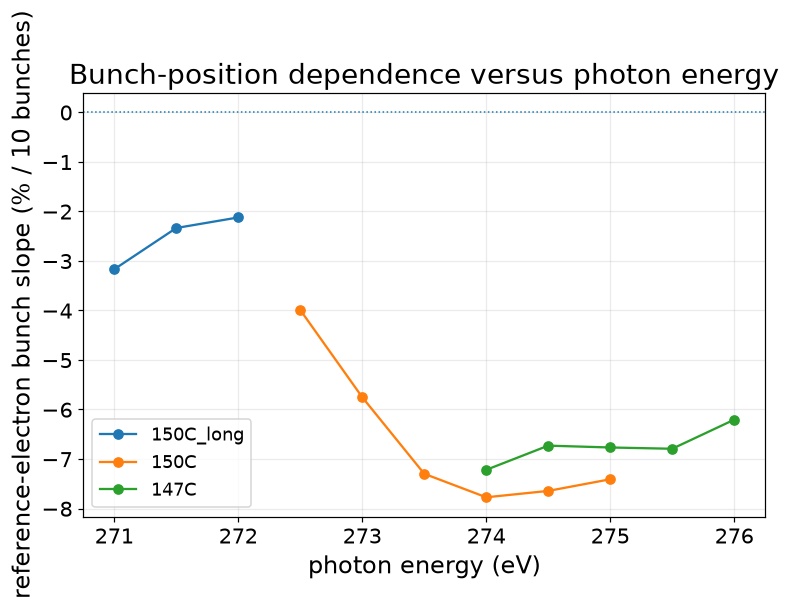

In [34]:
# --- Reference-electron bunch slope versus photon energy ---

def run_band_bunch_slope(run, gmd_range, bunch_start=MULTIRUN_BUNCH_START):
    gmd_run, ref_run, valid_rows, n_bunch_run = run["gmd"], run["ref_counts"], run["daq_valid_rows"], run["n_bunch"]
    lo, hi = gmd_range
    bunches_run = np.arange(bunch_start, n_bunch_run)
    obs, norm, shots = np.zeros(n_bunch_run, dtype=float), np.zeros(n_bunch_run, dtype=float), np.zeros(n_bunch_run, dtype=int)

    for b in bunches_run:
        sel = valid_rows & np.isfinite(gmd_run[:, b]) & (gmd_run[:, b] >= lo) & (gmd_run[:, b] < hi)
        shots[b], obs[b], norm[b] = sel.sum(), ref_run[sel, b].sum(), gmd_run[sel, b].sum()

    response = np.divide(obs, norm, out=np.full(n_bunch_run, np.nan), where=norm > 0)
    scale = obs[bunch_start:].sum() / norm[bunch_start:].sum()
    relative = response / scale
    slope_raw, intercept = weighted_bunch_line(relative, shots, start=bunch_start)

    return {"slope": 1000 * slope_raw, "intercept": intercept, "relative": relative, "shots": shots}

def run_combined_bunch_slope(run, bands=RUN_SLOPE_GMD_BANDS, bunch_start=MULTIRUN_BUNCH_START):
    band_results = [run_band_bunch_slope(run, band, bunch_start) for band in bands]
    weights = np.array([result["shots"][bunch_start:].sum() for result in band_results], dtype=float)
    slopes = np.array([result["slope"] for result in band_results], dtype=float)
    valid = np.isfinite(slopes) & (weights > 0)
    return np.average(slopes[valid], weights=weights[valid])


run_slope_rows = []
for group, energy in SELECT_RUNS:
    slope = run_combined_bunch_slope(RUN_DATA[(group, energy)])
    run_slope_rows.append({"group": group, "photon energy (eV)": energy, "slope (% / 10 bunches)": slope})

run_slope_table = pd.DataFrame(run_slope_rows)
display(run_slope_table.sort_values(["group", "photon energy (eV)"]).round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for group, df in run_slope_table.groupby("group", sort=False):
    df = df.sort_values("photon energy (eV)")
    ax.plot(df["photon energy (eV)"], df["slope (% / 10 bunches)"], "o-", label=group)

ax.axhline(0, ls=":", lw=1)
ax.set(xlabel="photon energy (eV)", ylabel="reference-electron bunch slope (% / 10 bunches)", title="Bunch-position dependence versus photon energy")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

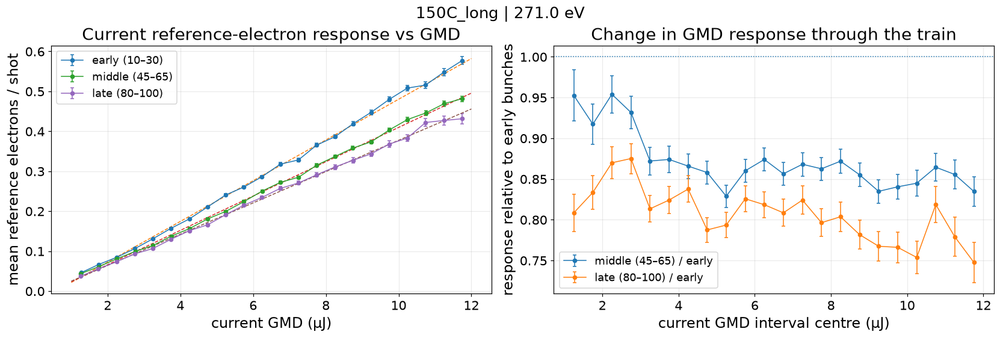

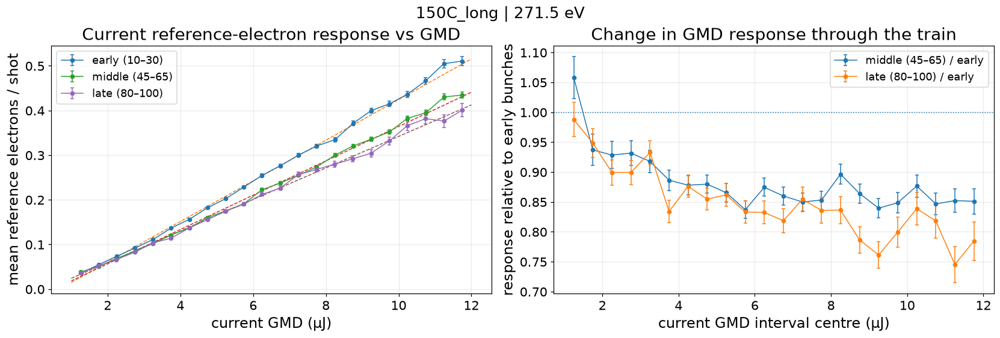

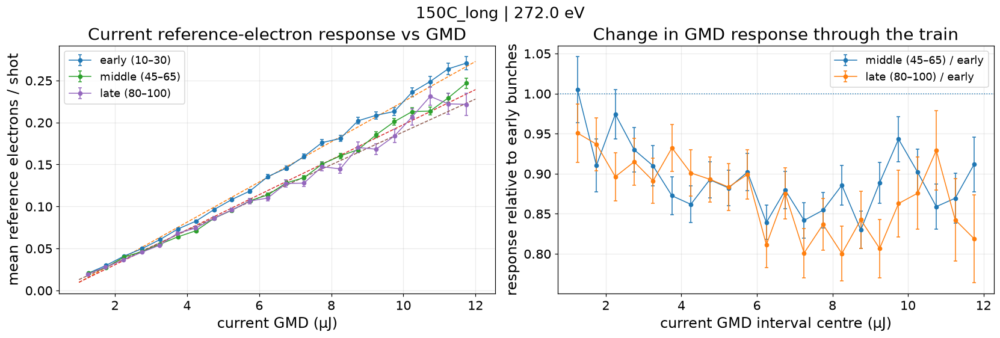

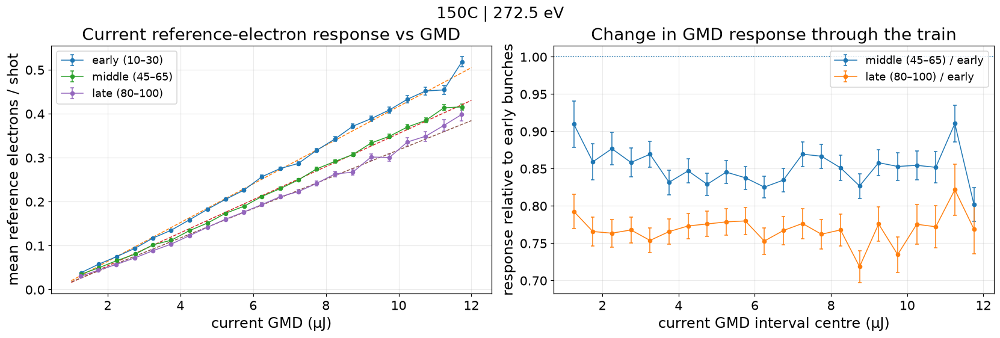

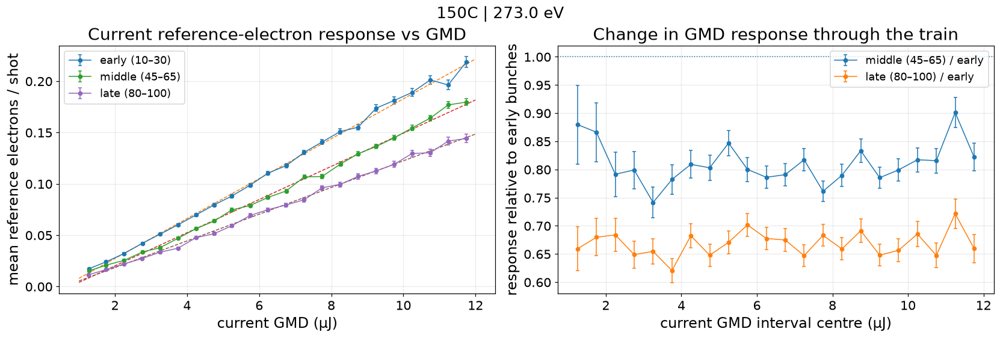

...

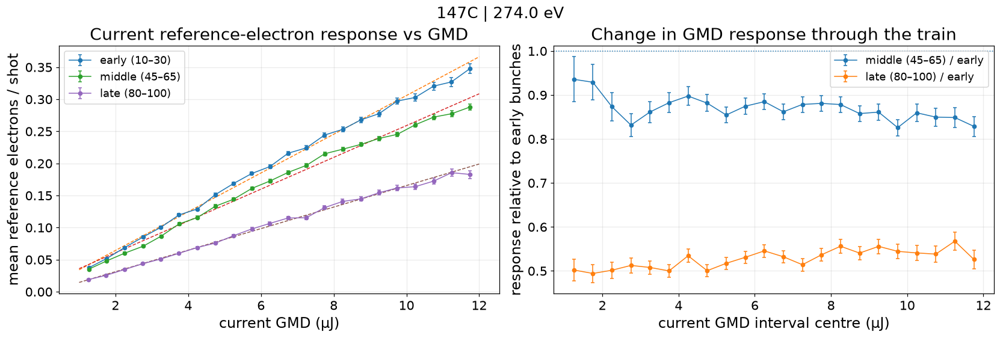

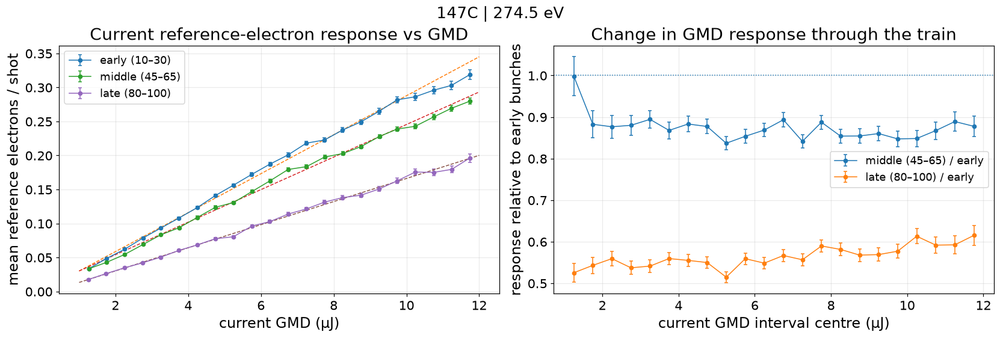

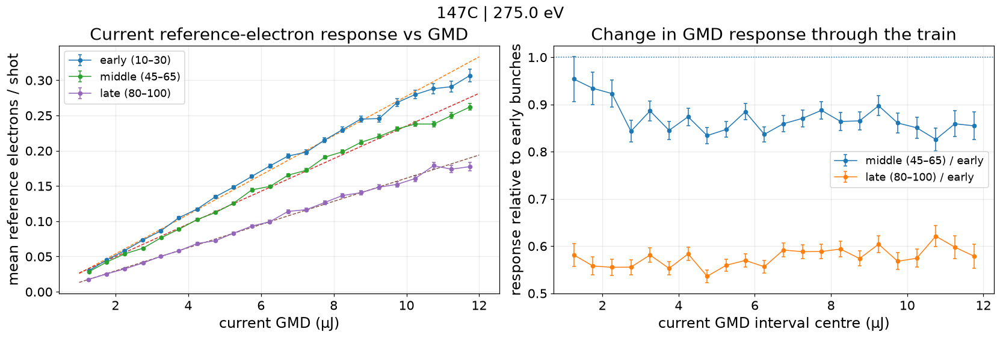

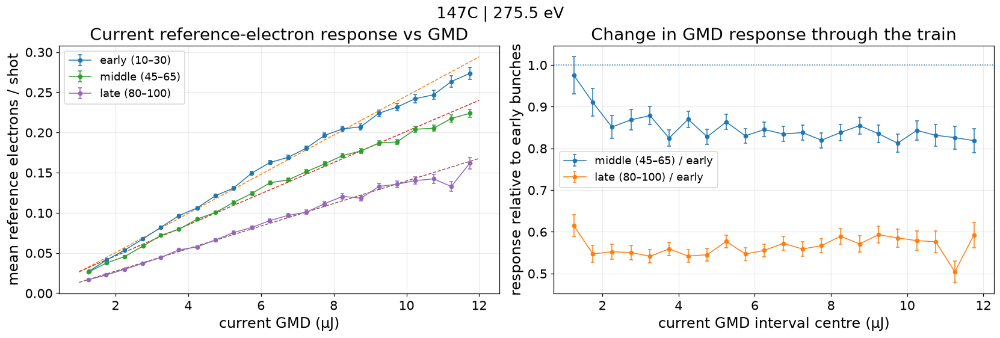

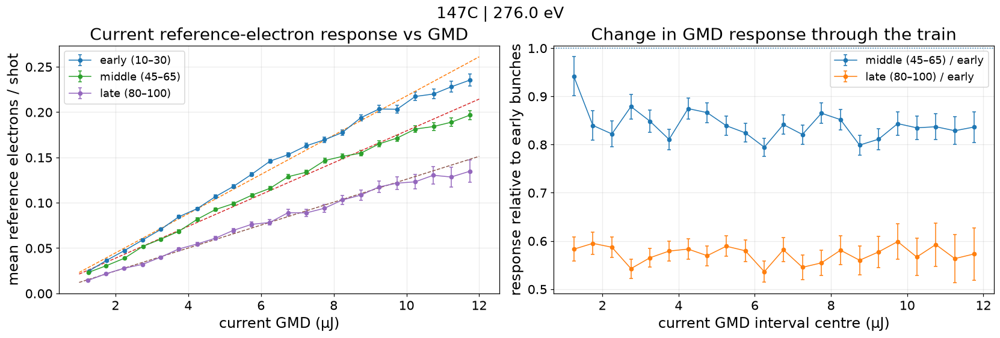

In [18]:
# --- Current reference-electron response vs GMD through the train, all selected runs ---

REF_GMD_RANGE = (1.0, 12.0)
REF_GMD_BIN_STEP = 0.5
BUNCH_GROUPS = {"early (10–30)": (10, 30), "middle (45–65)": (45, 65), "late (80–100)": (80, 100)}

gmd_edges_diag = np.arange(REF_GMD_RANGE[0], REF_GMD_RANGE[1] + REF_GMD_BIN_STEP, REF_GMD_BIN_STEP)
gmd_centres_diag = 0.5 * (gmd_edges_diag[:-1] + gmd_edges_diag[1:])

gmd_response_slope_rows = []

for key in SELECT_RUNS:
    group,energy = key
    run = RUN_DATA[key]
    gmd_run, ref_run, valid_rows, n_bunch_run = run["gmd"], run["ref_counts"], run["daq_valid_rows"], run["n_bunch"]
    group_results = {}

    for label, (b0, b1) in BUNCH_GROUPS.items():
        bunch_axis = np.arange(n_bunch_run)
        bunch_sel = (bunch_axis[None, :] >= b0) & (bunch_axis[None, :] <= b1)
        sel = valid_rows[:, None] & bunch_sel & np.isfinite(gmd_run) & (gmd_run >= REF_GMD_RANGE[0]) & (gmd_run < REF_GMD_RANGE[1])
        g, y = gmd_run[sel], ref_run[sel].astype(float)

        # Fit individual shots.
        slope, intercept = np.polyfit(g, y, 1)
        gmd_response_slope_rows.append({"group":group,"photon energy (eV)":energy,"bunch section":label,"slope (electrons / µJ)":slope})
        mean_response = np.full(len(gmd_centres_diag), np.nan)
        response_error = np.full(len(gmd_centres_diag), np.nan)
        mean_gmd = np.full(len(gmd_centres_diag), np.nan)

        for j, (lo, hi) in enumerate(zip(gmd_edges_diag[:-1], gmd_edges_diag[1:])):
            m = (g >= lo) & (g < hi)
            if not np.any(m): continue
            obs, n = y[m].sum(), m.sum()
            mean_response[j], response_error[j], mean_gmd[j] = obs / n, np.sqrt(obs) / n, g[m].mean()

        group_results[label] = {"mean_gmd": mean_gmd, "mean_response": mean_response, "response_error": response_error, "slope": slope, "intercept": intercept}

    fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

    for label, result in group_results.items():
        valid = np.isfinite(result["mean_gmd"]) & np.isfinite(result["mean_response"])
        axes[0].errorbar(result["mean_gmd"][valid], result["mean_response"][valid], yerr=result["response_error"][valid], fmt="o-", ms=4, lw=1, capsize=2, label=label)
        xfit = np.array(REF_GMD_RANGE)
        axes[0].plot(xfit, result["intercept"] + result["slope"] * xfit, "--", lw=1)

    axes[0].set(xlabel="current GMD (µJ)", ylabel="mean reference electrons / shot", title="Current reference-electron response vs GMD")
    axes[0].grid(alpha=0.25)
    axes[0].legend()

    early = group_results["early (10–30)"]
    for label in ["middle (45–65)", "late (80–100)"]:
        result = group_results[label]
        valid = np.isfinite(early["mean_response"]) & np.isfinite(result["mean_response"]) & (early["mean_response"] > 0) & (result["mean_response"] > 0)
        ratio = result["mean_response"][valid] / early["mean_response"][valid]
        ratio_error = ratio * np.sqrt((result["response_error"][valid] / result["mean_response"][valid])**2 + (early["response_error"][valid] / early["mean_response"][valid])**2)
        axes[1].errorbar(gmd_centres_diag[valid], ratio, yerr=ratio_error, fmt="o-", ms=4, lw=1, capsize=2, label=f"{label} / early")

    axes[1].axhline(1, ls=":", lw=1)
    axes[1].set(xlabel="current GMD interval centre (µJ)", ylabel="response relative to early bunches", title="Change in GMD response through the train")
    axes[1].grid(alpha=0.25)
    axes[1].legend()

    fig.suptitle(f"{group} | {energy:.1f} eV")
    plt.show()




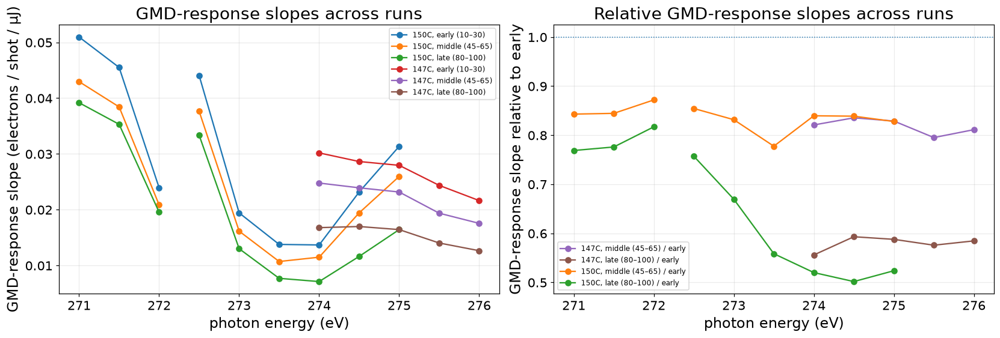

In [35]:
gmd_response_slope_table = pd.DataFrame(gmd_response_slope_rows)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

# Separate color mapping: Blue/Orange/Green for default groups, Red/Purple/Brown for 147C
default_colors = {"early (10–30)": "C0", "middle (45–65)": "C1", "late (80–100)": "C2"}  # Blue, Orange, Green
c147_colors = {"early (10–30)": "C3", "middle (45–65)": "C4", "late (80–100)": "C5"}    # Red, Purple, Brown

colors = {}

for (group, section), df in gmd_response_slope_table.groupby(["group", "bunch section"], sort=False):
    df = df.sort_values("photon energy (eV)")
    
    # Assign colors based on group identity
    if "147C" in str(group):
        c = c147_colors.get(section)
    else:
        c = default_colors.get(section)

    # Hide 150C long from the legend
    is_150c_long = "150C long" in str(group) or "150C_long" in str(group)
    lbl = "_nolegend_" if is_150c_long else f"{group}, {section}"

    (line,) = axes[0].plot(df["photon energy (eV)"], df["slope (electrons / µJ)"], "o-", color=c, label=lbl)
    colors[(group, section)] = line.get_color()

axes[0].set(xlabel="photon energy (eV)", ylabel="GMD-response slope (electrons / shot / µJ)", title="GMD-response slopes across runs")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=8)

slope_pivot = gmd_response_slope_table.pivot(index=["group", "photon energy (eV)"], columns="bunch section", values="slope (electrons / µJ)")

for group, df in slope_pivot.groupby(level="group", sort=False):
    df = df.sort_index(level="photon energy (eV)")
    early = df["early (10–30)"]
    
    is_150c_long = "150C long" in str(group) or "150C_long" in str(group)

    for section in ["middle (45–65)", "late (80–100)"]:
        ratio = df[section] / early
        c = colors.get((group, section))
        lbl = "_nolegend_" if is_150c_long else f"{group}, {section} / early"
        
        axes[1].plot(df.index.get_level_values("photon energy (eV)"), ratio, "o-", color=c, label=lbl)

axes[1].axhline(1, ls=":", lw=1)
axes[1].set(xlabel="photon energy (eV)", ylabel="GMD-response slope relative to early", title="Relative GMD-response slopes across runs")
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=8)

plt.show()


,group,photon energy (eV),GMD low (µJ),GMD high (µJ),GMD centre (µJ),slope (% / 10 bunches),shots
54,147C,274.0,1.0,2.0,1.5,-7.6731,193320
55,147C,274.0,2.0,3.0,2.5,-7.2899,203047
56,147C,274.0,3.0,4.0,3.5,-7.1723,212520
57,147C,274.0,4.0,6.0,5.0,-6.9328,409040
58,147C,274.0,6.0,8.0,7.0,-6.8367,345140
...,...,...,...,...,...,...,...
13,150C_long,272.0,2.0,3.0,2.5,-1.5598,338770
14,150C_long,272.0,3.0,4.0,3.5,-2.0495,283273
15,150C_long,272.0,4.0,6.0,5.0,-2.5190,418178
16,150C_long,272.0,6.0,8.0,7.0,-3.3439,265881


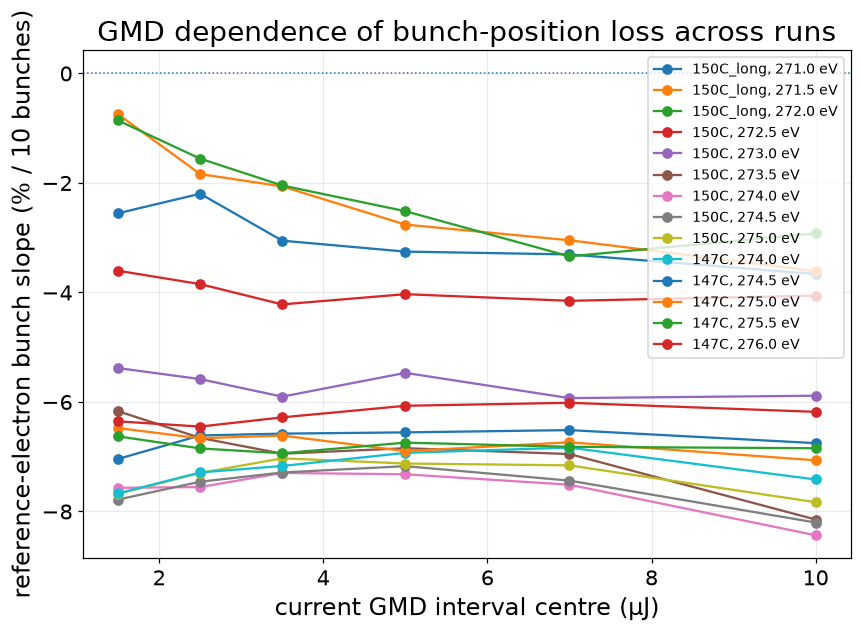

In [20]:
# --- GMD dependence of reference-electron bunch slope across runs ---

gmd_slope_rows = []

for key in SELECT_RUNS:
    group, energy = key
    run = RUN_DATA[key]

    for lo, hi in GMD_SLOPE_BANDS:
        result = run_band_bunch_slope(run, (lo, hi), bunch_start=0)
        gmd_slope_rows.append({
            "group": group, "photon energy (eV)": energy, "GMD low (µJ)": lo,
            "GMD high (µJ)": hi, "GMD centre (µJ)": 0.5 * (lo + hi),
            "slope (% / 10 bunches)": result["slope"],
            "shots": int(result["shots"][20:].sum()),
        })

gmd_slope_all = pd.DataFrame(gmd_slope_rows)
display(gmd_slope_all.sort_values(["group", "photon energy (eV)", "GMD low (µJ)"]).round(4))

fig, ax = plt.subplots(figsize=(9, 6))

for (group, energy), df in gmd_slope_all.groupby(["group", "photon energy (eV)"], sort=False):
    df = df.sort_values("GMD centre (µJ)")
    ax.plot(df["GMD centre (µJ)"], df["slope (% / 10 bunches)"], "o-", label=f"{group}, {energy:.1f} eV")

ax.axhline(0, ls=":", lw=1)
ax.set(xlabel="current GMD interval centre (µJ)", ylabel="reference-electron bunch slope (% / 10 bunches)", title="GMD dependence of bunch-position loss across runs")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
plt.show()

### Run slope vs gmd

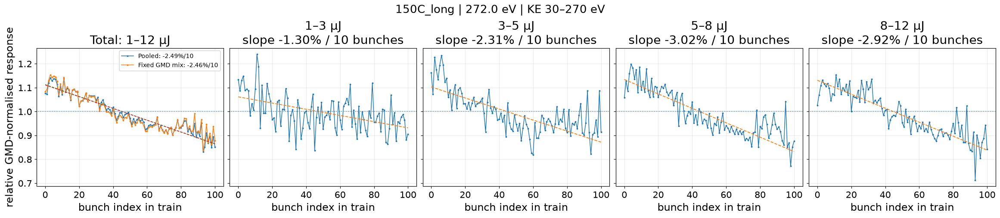

,GMD range,slope (% / 10 bunches),fixed weight,valid shots
0,Total pooled,-2.4878,NaN,2563623
1,Total fixed mix,-2.4586,NaN,2563623
2,1–3 µJ,-1.2989,0.1739,1012243
3,3–5 µJ,-2.3095,0.2350,669721
4,5–8 µJ,-3.0183,0.3193,565351
5,8–12 µJ,-2.9246,0.2718,316308


Difference (pooled − fixed mix): -0.029% / 10 bunches


In [21]:
# --- GMD dependence of bunch-position loss: pooled vs fixed-GMD-weight response ---
GMD_DIAG_RUN = ("150C_long",272.0)
GMD_DIAG_BUNCH_START = 0
GMD_DIAG_RANGES = [
    ("1–3 µJ",(1,3)),
    ("3–5 µJ",(3,5)),
    ("5–8 µJ",(5,8)),
    ("8–12 µJ",(8,12)),
]

run = RUN_DATA[GMD_DIAG_RUN]
gmd_run = run["gmd"]
ref_run = run["ref_counts"]
valid_rows = run["daq_valid_rows"]
n_bunch_run = run["n_bunch"]
bunches = np.arange(GMD_DIAG_BUNCH_START,n_bunch_run)
n_bands = len(GMD_DIAG_RANGES)

obs = np.zeros((n_bands,n_bunch_run))
norm = np.zeros_like(obs)
shots = np.zeros((n_bands,n_bunch_run),dtype=int)

# Calculate electron counts and GMD exposure separately in each band.
for k,(label,(lo,hi)) in enumerate(GMD_DIAG_RANGES):
    for b in bunches:
        sel = valid_rows & np.isfinite(gmd_run[:,b]) & (gmd_run[:,b] >= lo) & (gmd_run[:,b] < hi)
        shots[k,b] = sel.sum()
        obs[k,b] = ref_run[sel,b].sum()
        norm[k,b] = gmd_run[sel,b].sum()

band_response = np.divide(obs,norm,out=np.full_like(obs,np.nan),where=norm > 0)
total_obs = obs.sum(axis=0)
total_norm = norm.sum(axis=0)
total_shots = shots.sum(axis=0)
pooled_response = np.divide(total_obs,total_norm,out=np.full(n_bunch_run,np.nan),where=total_norm > 0)

# Use the same bunch positions for both total-response curves.
common = np.zeros(n_bunch_run,dtype=bool)
common[bunches] = np.all(norm[:,bunches] > 0,axis=0)
if common.sum() < 3:
    raise ValueError("Too few bunch positions have data in every GMD band.")
if common[bunches].sum() < len(bunches):
    print(f"Excluded {len(bunches)-common[bunches].sum()} bunch positions without data in all four GMD bands.")

# Fixed GMD-exposure weights, calculated once across the whole selected bunch range.
band_exposure = norm[:,common].sum(axis=1)
weights = band_exposure/band_exposure.sum()
standardized_response = np.sum(weights[:,None]*band_response,axis=0)

# Use one common normalization for the two total curves.
scale = total_obs[common].sum()/total_norm[common].sum()
pooled_relative = pooled_response/scale
standardized_relative = standardized_response/scale
pooled_relative[~common] = np.nan
standardized_relative[~common] = np.nan

pooled_slope,pooled_intercept = weighted_bunch_line(pooled_relative,total_shots,start=GMD_DIAG_BUNCH_START)
standardized_slope,standardized_intercept = weighted_bunch_line(standardized_relative,total_shots,start=GMD_DIAG_BUNCH_START)

fig,axes = plt.subplots(1,5,figsize=(21,4.5),sharey=True,constrained_layout=True)
gmd_diag_results = []

# First panel: original pooled curve and new fixed-weight curve.
ax = axes[0]
x = bunches[common[bunches]]

ax.plot(x,pooled_relative[x],".-",ms=3,lw=1,label=f"Pooled: {1000*pooled_slope:+.2f}%/10")
ax.plot(x,standardized_relative[x],".-",ms=3,lw=1,label=f"Fixed GMD mix: {1000*standardized_slope:+.2f}%/10")
ax.plot([x[0],x[-1]],pooled_intercept+pooled_slope*np.array([x[0],x[-1]]),"--",lw=1)
ax.plot([x[0],x[-1]],standardized_intercept+standardized_slope*np.array([x[0],x[-1]]),"--",lw=1)
ax.axhline(1,ls=":",lw=1)
ax.set(xlabel="bunch index in train",ylabel="relative GMD-normalised response",title="Total: 1–12 µJ")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)

gmd_diag_results.append({"GMD range":"Total pooled","slope (% / 10 bunches)":1000*pooled_slope,"fixed weight":np.nan,"valid shots":int(total_shots[common].sum())})
gmd_diag_results.append({"GMD range":"Total fixed mix","slope (% / 10 bunches)":1000*standardized_slope,"fixed weight":np.nan,"valid shots":int(total_shots[common].sum())})

# Remaining panels: separate GMD intervals.
for k,(label,(lo,hi)) in enumerate(GMD_DIAG_RANGES):
    ax = axes[k+1]
    band_scale = obs[k,common].sum()/norm[k,common].sum()
    relative = band_response[k]/band_scale
    relative[~common] = np.nan
    slope_raw,intercept = weighted_bunch_line(relative,shots[k],start=GMD_DIAG_BUNCH_START)

    ax.plot(x,relative[x],".-",ms=3,lw=1)
    ax.plot([x[0],x[-1]],intercept+slope_raw*np.array([x[0],x[-1]]),"--",lw=1.2)
    ax.axhline(1,ls=":",lw=1)
    ax.set(xlabel="bunch index in train",title=f"{label}\nslope {1000*slope_raw:+.2f}% / 10 bunches")
    ax.grid(alpha=0.25)

    gmd_diag_results.append({"GMD range":label,"slope (% / 10 bunches)":1000*slope_raw,"fixed weight":weights[k],"valid shots":int(shots[k,common].sum())})

fig.suptitle(f"{GMD_DIAG_RUN[0]} | {GMD_DIAG_RUN[1]:.1f} eV | KE {MULTIRUN_REF_KE_RANGE[0]:g}–{MULTIRUN_REF_KE_RANGE[1]:g} eV")
plt.show()

display(pd.DataFrame(gmd_diag_results).round(4))
print(f"Difference (pooled − fixed mix): {1000*(pooled_slope-standardized_slope):+.3f}% / 10 bunches")

### Previous history double check

,all slope,all SD,zero-history slope,zero SD,nonzero-history slope,nonzero SD,zero shots,nonzero shots,minimum zero shots/bunch,valid zero bootstrap
window,,,,,,,,,,
1,-5.8245,0.3096,-5.7448,0.3418,-6.1682,0.8504,476889,79174,2982,200
2,-5.8245,0.3096,-5.7739,0.3652,-5.7093,0.6039,411052,145011,2466,200
3,-5.8245,0.3096,-5.7723,0.3998,-5.7521,0.5318,355737,200326,2025,200
5,-5.8245,0.3096,-6.2225,0.4333,-5.3427,0.4505,268753,287310,1379,200


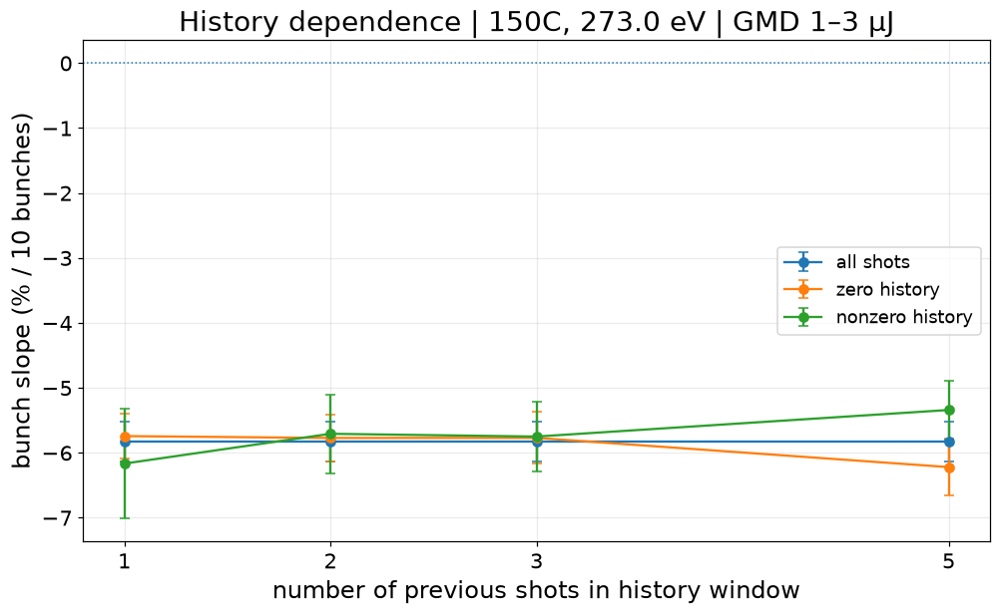

Electron KE: configured (30.0, 270.0) eV (verify loader was run with this selection)
Common bunch positions: 10–100


In [22]:
# --- Zero-electron-history bunch slopes versus history window: selected run ---
HISTORY_RUN = ("150C",273.0)
HISTORY_WINDOWS = [1,2,3,5]
HISTORY_BUNCH_START = 10
HISTORY_GMD_RANGE = (1.0,3.0)
HISTORY_N_BOOT = 200
HISTORY_BOOT_SEED = 12345

if HISTORY_RUN not in RUN_DATA:
    raise KeyError(f"{HISTORY_RUN} is not in RUN_DATA. Load this run in cell 25 first.")

run = RUN_DATA[HISTORY_RUN]
gmd_hist = run["gmd"]
ref_hist = run["ref_counts"]
n_trains,n_bunch = gmd_hist.shape

# Load all detected-electron counts once, retaining only a compact train x bunch array.
# History uses every detected electron hit, not just the selected KE region.
if "total_electrons" not in run:
    print(f"Loading electron history for {HISTORY_RUN} ...")
    with h5py.File(run["source_h5"],"r") as handle:
        d = handle["tofs_e"]
        if d.ndim != 3 or d.shape[0] < n_trains or d.shape[1] != n_bunch:
            raise ValueError(f"Unexpected tofs_e shape: {d.shape}")
        dtype = np.uint16 if d.shape[-1] <= 65535 else np.uint32
        total_electrons = np.empty((n_trains,n_bunch),dtype=dtype)
        for start in range(0,n_trains,INDEP_CHUNK_TRAINS):
            stop = min(start+INDEP_CHUNK_TRAINS,n_trains)
            tof = d[start:stop]
            total_electrons[start:stop] = np.count_nonzero(np.isfinite(tof) & (tof > 0),axis=-1)
    run["total_electrons"] = total_electrons

total_electrons = run["total_electrons"]
if total_electrons.shape != gmd_hist.shape or ref_hist.shape != gmd_hist.shape:
    raise ValueError("GMD, reference counts and electron-history array shapes do not match.")

# Common bunch range for every history window; previous shots never cross trains.
history_start = max(HISTORY_BUNCH_START,max(HISTORY_WINDOWS))
bunches_hist = np.arange(history_start,n_bunch)
if len(bunches_hist) < 3:
    raise ValueError("Too few bunch positions for a slope fit.")

cum_e_hist = np.concatenate((np.zeros((n_trains,1),dtype=np.int64),np.cumsum(total_electrons,axis=1,dtype=np.int64)),axis=1)
base_sel = (run["daq_valid_rows"][:,None] & np.isfinite(gmd_hist[:,bunches_hist])
            & (gmd_hist[:,bunches_hist] >= HISTORY_GMD_RANGE[0])
            & (gmd_hist[:,bunches_hist] < HISTORY_GMD_RANGE[1]))

ref_selected = ref_hist[:,bunches_hist]
gmd_selected = gmd_hist[:,bunches_hist]
num_all = np.where(base_sel,ref_selected,0).astype(np.float32)
den_all = np.where(base_sel,gmd_selected,0).astype(np.float32)

def history_slope_from_sums(obs,norm):
    response = np.divide(obs,norm,out=np.full(len(bunches_hist),np.nan),where=norm > 0)
    if not np.all(np.isfinite(response)) or np.mean(response) <= 0:
        return np.nan
    relative = response/np.mean(response)
    return np.polyfit(bunches_hist,relative,1)[0]*1000

# Reuse the same train-resampling draws for all curves.
history_seeds = np.random.default_rng(HISTORY_BOOT_SEED).integers(0,2**32,size=HISTORY_N_BOOT,dtype=np.uint64)

def history_bootstrap_slopes(num,den):
    slopes = np.full(HISTORY_N_BOOT,np.nan)
    for k,seed in enumerate(history_seeds):
        rng = np.random.default_rng(int(seed))
        sample = rng.integers(0,n_trains,size=n_trains)
        weights = np.bincount(sample,minlength=n_trains).astype(np.float32)
        slopes[k] = history_slope_from_sums(weights@num,weights@den)
    return slopes

all_slope = history_slope_from_sums(num_all.sum(axis=0,dtype=float),den_all.sum(axis=0,dtype=float))
all_boot = history_bootstrap_slopes(num_all,den_all)
history_results = []

for window in HISTORY_WINDOWS:
    H = cum_e_hist[:,bunches_hist]-cum_e_hist[:,bunches_hist-window]
    zero_sel = base_sel & (H == 0)
    nonzero_sel = base_sel & (H > 0)

    num_zero = np.where(zero_sel,ref_selected,0).astype(np.float32)
    den_zero = np.where(zero_sel,gmd_selected,0).astype(np.float32)
    num_nonzero = np.where(nonzero_sel,ref_selected,0).astype(np.float32)
    den_nonzero = np.where(nonzero_sel,gmd_selected,0).astype(np.float32)

    zero_slope = history_slope_from_sums(num_zero.sum(axis=0,dtype=float),den_zero.sum(axis=0,dtype=float))
    nonzero_slope = history_slope_from_sums(num_nonzero.sum(axis=0,dtype=float),den_nonzero.sum(axis=0,dtype=float))
    zero_boot = history_bootstrap_slopes(num_zero,den_zero)
    nonzero_boot = history_bootstrap_slopes(num_nonzero,den_nonzero)

    history_results.append({
        "window":window,
        "all slope":all_slope,
        "all SD":np.nanstd(all_boot,ddof=1),
        "zero-history slope":zero_slope,
        "zero SD":np.nanstd(zero_boot,ddof=1),
        "nonzero-history slope":nonzero_slope,
        "nonzero SD":np.nanstd(nonzero_boot,ddof=1),
        "zero shots":int(zero_sel.sum()),
        "nonzero shots":int(nonzero_sel.sum()),
        "minimum zero shots/bunch":int(zero_sel.sum(axis=0).min()),
        "valid zero bootstrap":int(np.isfinite(zero_boot).sum())
    })

history_table = pd.DataFrame(history_results).set_index("window")
display(history_table.round(4))

fig,ax = plt.subplots(figsize=(9,5.5),constrained_layout=True)
ax.errorbar(HISTORY_WINDOWS,history_table["all slope"],yerr=history_table["all SD"],fmt="o-",capsize=3,label="all shots")
ax.errorbar(HISTORY_WINDOWS,history_table["zero-history slope"],yerr=history_table["zero SD"],fmt="o-",capsize=3,label="zero history")
ax.errorbar(HISTORY_WINDOWS,history_table["nonzero-history slope"],yerr=history_table["nonzero SD"],fmt="o-",capsize=3,label="nonzero history")
ax.axhline(0,ls=":",lw=1)
ax.set(xlabel="number of previous shots in history window",ylabel="bunch slope (% / 10 bunches)",
       title=f"History dependence | {HISTORY_RUN[0]}, {HISTORY_RUN[1]:.1f} eV | GMD {HISTORY_GMD_RANGE[0]:g}–{HISTORY_GMD_RANGE[1]:g} µJ")
ax.set_xticks(HISTORY_WINDOWS)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

print(f"Electron KE: configured {MULTIRUN_REF_KE_RANGE} eV (verify loader was run with this selection)")
print(f"Common bunch positions: {history_start}–{n_bunch-1}")
if history_table["minimum zero shots/bunch"].min() == 0:
    print("WARNING: Some bunch positions have no zero-history shots. Slopes may be undefined.")
if history_table["valid zero bootstrap"].min() < 0.8*HISTORY_N_BOOT:
    print("WARNING: Insufficient valid zero-history bootstrap samples for at least one window.")

In [23]:
# --- Compare history and GMD-diagnostic slope definitions on identical shots ---
SLOPE_CHECK_RUN = ("150C_long",272.0)
SLOPE_CHECK_GMD = (1.0,3.0)
SLOPE_CHECK_START = 10

run = RUN_DATA[SLOPE_CHECK_RUN]
bunches_check = np.arange(SLOPE_CHECK_START,run["n_bunch"])
g = run["gmd"][:,bunches_check]
y = run["ref_counts"][:,bunches_check]
valid = run["daq_valid_rows"][:,None] & np.isfinite(g) & (g >= SLOPE_CHECK_GMD[0]) & (g < SLOPE_CHECK_GMD[1])

obs = np.where(valid,y,0).sum(axis=0,dtype=float)
norm = np.where(valid,g,0).sum(axis=0,dtype=float)
shots = valid.sum(axis=0)
good = (norm > 0) & (shots > 0)

response = np.divide(obs,norm,out=np.full(len(bunches_check),np.nan),where=good)
history_relative = response/np.nanmean(response)
pooled_relative = response/(obs.sum()/norm.sum())

history_slope = 1000*np.polyfit(bunches_check[good],history_relative[good],1)[0]
weighted_slope = 1000*np.polyfit(bunches_check[good],pooled_relative[good],1,w=np.sqrt(shots[good]))[0]

print(f"History convention (unweighted) : {history_slope:+.3f}% / 10 bunches")
print(f"GMD diagnostic (shot-weighted) : {weighted_slope:+.3f}% / 10 bunches")
print(f"Valid bunch positions          : {good.sum()}/{len(good)}")

History convention (unweighted) : -1.003% / 10 bunches
GMD diagnostic (shot-weighted) : -1.052% / 10 bunches
Valid bunch positions          : 91/91


## Inter-run transferability of the  bunch specific GMD response slope

In [24]:
# --- Cross-run transferability: fit a_b + b_b G independently for each run ---
TRANSFER_RUNS = list(SELECT_RUNS)
TRANSFER_GMD_RANGE = (1.0,12.0)
TRANSFER_BUNCH_START = 0
TRANSFER_MIN_SHOTS = 100

missing = [key for key in TRANSFER_RUNS if key not in RUN_DATA]
if missing:
    raise RuntimeError(f"Runs not loaded: {missing}. Run cell 25 first.")

def fit_transfer_response(run):
    gmd = run["gmd"]
    counts = run["ref_counts"].astype(float)
    valid = run["daq_valid_rows"][:,None] & np.isfinite(gmd) & (gmd >= TRANSFER_GMD_RANGE[0]) & (gmd < TRANSFER_GMD_RANGE[1])

    g = np.where(valid,gmd,0.0)
    y = np.where(valid,counts,0.0)
    n = valid.sum(axis=0).astype(float)
    sg,sy = g.sum(axis=0),y.sum(axis=0)
    sgg,sgy = (g*g).sum(axis=0),(g*y).sum(axis=0)
    den = n*sgg-sg**2
    good = (n >= TRANSFER_MIN_SHOTS) & (den > 0)

    a,b = np.full(run["n_bunch"],np.nan),np.full(run["n_bunch"],np.nan)
    b[good] = (n[good]*sgy[good]-sg[good]*sy[good])/den[good]
    a[good] = (sy[good]-b[good]*sg[good])/n[good]

    return {"a":a,"b":b,"shots":n}

TRANSFER_FITS = {key:fit_transfer_response(RUN_DATA[key]) for key in TRANSFER_RUNS}

print(f"Configured electron KE: {MULTIRUN_REF_KE_RANGE} eV; GMD: {TRANSFER_GMD_RANGE} µJ")
for key,fit in TRANSFER_FITS.items():
    valid = np.isfinite(fit["a"][TRANSFER_BUNCH_START:])
    print(f"{key[0]:12s} {key[1]:.1f} eV: {valid.sum()} fitted bunch positions")

Configured electron KE: (30.0, 270.0) eV; GMD: (1.0, 12.0) µJ
150C_long    271.0 eV: 101 fitted bunch positions
150C_long    271.5 eV: 101 fitted bunch positions
150C_long    272.0 eV: 101 fitted bunch positions
150C         272.5 eV: 101 fitted bunch positions
150C         273.0 eV: 101 fitted bunch positions
150C         273.5 eV: 101 fitted bunch positions
150C         274.0 eV: 101 fitted bunch positions
150C         274.5 eV: 101 fitted bunch positions
150C         275.0 eV: 101 fitted bunch positions
147C         274.0 eV: 101 fitted bunch positions
147C         274.5 eV: 101 fitted bunch positions
147C         275.0 eV: 101 fitted bunch positions
147C         275.5 eV: 101 fitted bunch positions
147C         276.0 eV: 101 fitted bunch positions


Cross-run prediction RMS (%):


,150C_long 271.0,150C_long 271.5,150C_long 272.0,150C 272.5,150C 273.0,150C 273.5,150C 274.0,150C 274.5,150C 275.0,147C 274.0,147C 274.5,147C 275.0,147C 275.5,147C 276.0
150C_long 271.0,NaN,2.56,3.29,3.24,7.59,14.06,18.59,19.17,17.47,15.46,13.37,13.27,13.09,11.33
150C_long 271.5,2.52,NaN,2.51,4.67,8.93,15.32,19.73,20.23,18.64,16.63,14.63,14.70,14.43,12.60
150C_long 272.0,3.24,2.52,NaN,5.42,9.83,15.93,20.12,20.68,19.09,17.16,15.08,15.17,14.96,12.94
150C 272.5,3.25,4.79,5.63,NaN,5.80,12.52,17.29,17.93,16.16,13.96,11.82,11.63,11.43,9.47
150C 273.0,8.38,10.49,11.26,6.11,NaN,8.32,14.01,14.82,12.87,10.48,8.41,7.94,7.70,6.55
150C 273.5,16.02,17.75,18.20,13.16,8.90,NaN,7.80,9.00,7.06,4.82,3.79,3.21,3.29,3.80
150C 274.0,24.42,25.91,26.42,21.55,17.54,8.91,NaN,3.18,3.05,4.65,7.37,8.65,8.10,7.45
150C 274.5,25.66,26.83,27.22,22.46,19.24,10.84,3.29,NaN,3.57,5.66,8.57,9.94,9.34,8.12
150C 275.0,22.69,23.85,24.30,19.59,16.39,8.35,3.03,3.45,NaN,3.73,6.02,7.45,7.02,6.11
147C 274.0,20.30,21.79,22.33,17.39,13.30,5.57,4.58,5.50,3.75,NaN,4.16,5.21,4.64,4.68


Residual bunch slopes (% / 10 bunches):


,150C_long 271.0,150C_long 271.5,150C_long 272.0,150C 272.5,150C 273.0,150C 273.5,150C 274.0,150C 274.5,150C 275.0,147C 274.0,147C 274.5,147C 275.0,147C 275.5,147C 276.0
150C_long 271.0,NaN,0.54,0.79,-0.86,-2.43,-4.27,-4.95,-4.92,-4.64,-4.34,-3.79,-3.96,-3.99,-3.31
150C_long 271.5,-0.51,NaN,0.22,-1.43,-2.87,-4.66,-5.31,-5.28,-5.01,-4.72,-4.20,-4.44,-4.43,-3.72
150C_long 272.0,-0.76,-0.24,NaN,-1.64,-3.15,-4.93,-5.55,-5.52,-5.26,-4.97,-4.43,-4.65,-4.65,-3.94
150C 272.5,0.80,1.43,1.70,NaN,-1.78,-3.71,-4.41,-4.37,-4.08,-3.74,-3.15,-3.29,-3.31,-2.53
150C 273.0,2.71,3.41,3.70,1.86,NaN,-2.07,-2.89,-2.87,-2.52,-2.15,-1.53,-1.69,-1.66,-0.79
150C 273.5,4.58,5.05,5.20,3.60,2.08,NaN,-1.05,-1.12,-0.81,-0.54,0.20,0.25,-0.09,-0.03
150C 274.0,6.06,6.45,6.55,5.08,3.53,1.29,NaN,-0.14,0.18,0.41,1.29,1.57,0.93,0.43
150C 274.5,6.11,6.40,6.44,5.09,3.72,1.53,0.18,NaN,0.30,0.47,1.38,1.73,0.96,0.18
150C 275.0,5.67,5.99,6.06,4.67,3.29,1.15,-0.13,-0.28,NaN,0.20,1.07,1.36,0.68,0.07
147C 274.0,5.44,5.88,6.02,4.51,2.90,0.73,-0.46,-0.57,-0.25,NaN,0.83,1.04,0.53,0.30


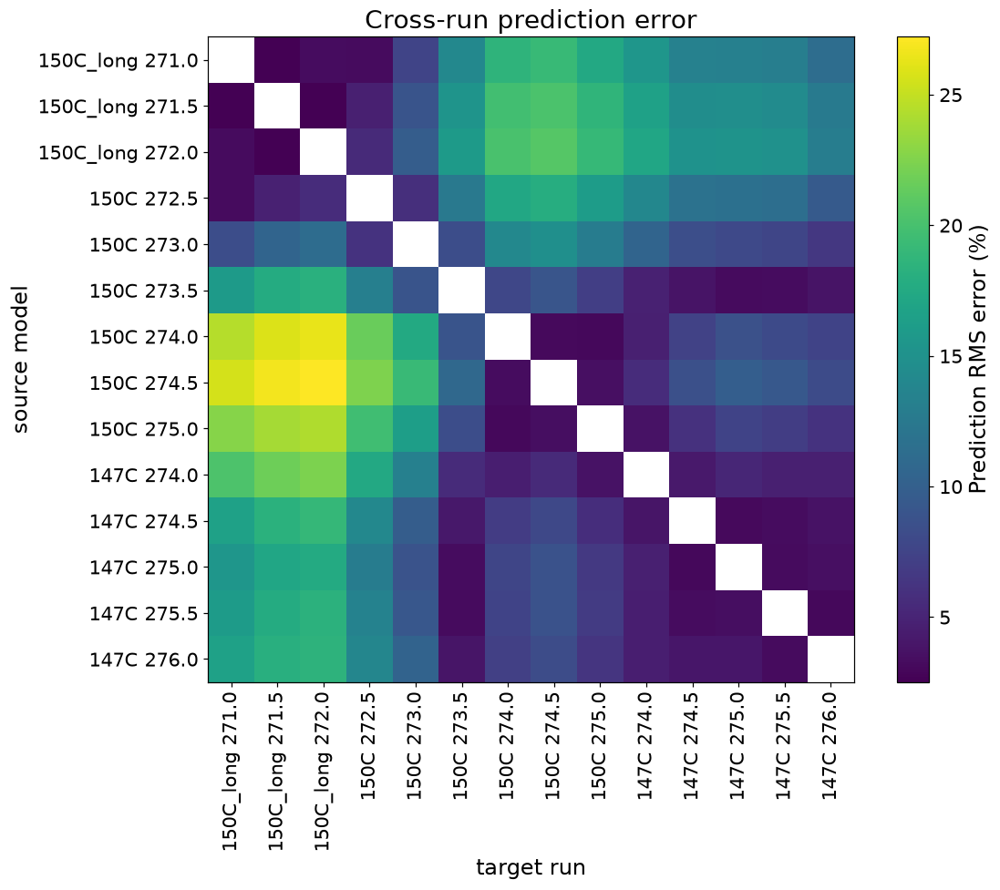

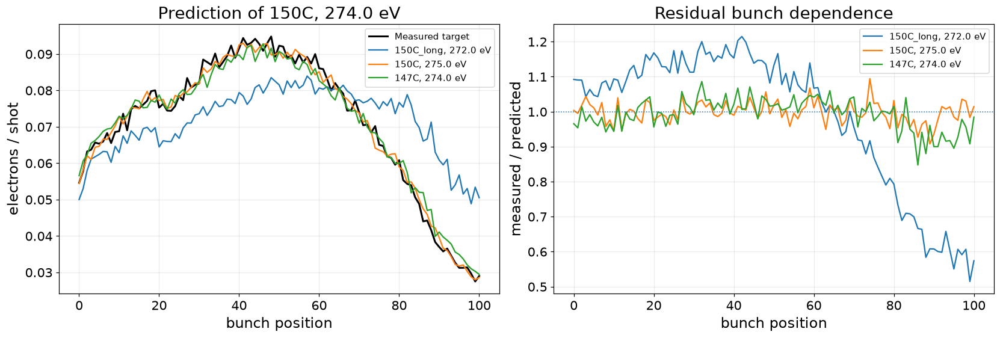

In [25]:
# --- Direct cross-run prediction: source fit vs measured target counts ---
N_TRANSFER_BUNCH = min(RUN_DATA[key]["n_bunch"] for key in TRANSFER_RUNS)
TRANSFER_BUNCHES = np.arange(TRANSFER_BUNCH_START,N_TRANSFER_BUNCH)

def target_bunch_sums(run):
    gmd = run["gmd"][:,:N_TRANSFER_BUNCH]
    valid = run["daq_valid_rows"][:,None] & np.isfinite(gmd) & (gmd >= TRANSFER_GMD_RANGE[0]) & (gmd < TRANSFER_GMD_RANGE[1])
    return {
        "shots":valid.sum(axis=0),
        "gmd":np.where(valid,gmd,0.0).sum(axis=0),
        "counts":np.where(valid,run["ref_counts"][:,:N_TRANSFER_BUNCH],0.0).sum(axis=0),
    }

TRANSFER_TARGET_SUMS = {key:target_bunch_sums(RUN_DATA[key]) for key in TRANSFER_RUNS}
n_runs = len(TRANSFER_RUNS)
transfer_rms = np.full((n_runs,n_runs),np.nan)
transfer_residual_slope = np.full((n_runs,n_runs),np.nan)
TRANSFER_PREDICTIONS = {}

for i,source in enumerate(TRANSFER_RUNS):
    a = TRANSFER_FITS[source]["a"][:N_TRANSFER_BUNCH]
    b = TRANSFER_FITS[source]["b"][:N_TRANSFER_BUNCH]

    for j,target in enumerate(TRANSFER_RUNS):
        if source == target: continue

        stats = TRANSFER_TARGET_SUMS[target]
        predicted = a*stats["shots"] + b*stats["gmd"]
        idx = TRANSFER_BUNCHES

        if np.any(~np.isfinite(predicted[idx]) | (predicted[idx] <= 0) | (stats["shots"][idx] == 0)):
            raise ValueError(f"Invalid prediction for {source} -> {target}; check GMD range and fit support.")

        # One global scale per source-target pair, not one scale per bunch.
        scale = stats["counts"][idx].sum()/predicted[idx].sum()
        predicted *= scale

        observed = stats["counts"][idx]
        fitted = predicted[idx]
        shots = stats["shots"][idx]
        relative = observed/fitted

        transfer_rms[i,j] = 100*np.sqrt(np.average((relative-1)**2,weights=shots))

        x = idx.astype(float)
        x0 = np.average(x,weights=shots)
        y0 = np.average(relative,weights=shots)
        transfer_residual_slope[i,j] = 1000*np.sum(shots*(x-x0)*(relative-y0))/np.sum(shots*(x-x0)**2)

        TRANSFER_PREDICTIONS[(source,target)] = predicted

labels = [f"{group} {energy:.1f}" for group,energy in TRANSFER_RUNS]
transfer_rms_table = pd.DataFrame(transfer_rms,index=labels,columns=labels)
transfer_slope_table = pd.DataFrame(transfer_residual_slope,index=labels,columns=labels)

print("Cross-run prediction RMS (%):")
display(transfer_rms_table.round(2))

print("Residual bunch slopes (% / 10 bunches):")
display(transfer_slope_table.round(2))

fig,ax = plt.subplots(figsize=(11,9))
im = ax.imshow(np.ma.masked_invalid(transfer_rms),origin="upper",aspect="equal",cmap="viridis")
ax.set_xticks(np.arange(n_runs),labels,rotation=90)
ax.set_yticks(np.arange(n_runs),labels)
ax.set(xlabel="target run",ylabel="source model",title="Cross-run prediction error")
fig.colorbar(im,ax=ax,label="Prediction RMS error (%)")
plt.tight_layout()
plt.show()

# --- Example: compare predictions directly against one target run ---
TRANSFER_EXAMPLE_TARGET = ("150C",274.0)
TRANSFER_EXAMPLE_SOURCES = [("150C_long",272.0),("150C",275.0),("147C",274.0)]

target = TRANSFER_EXAMPLE_TARGET
stats = TRANSFER_TARGET_SUMS[target]
idx = TRANSFER_BUNCHES
obs_mean = stats["counts"][idx]/stats["shots"][idx]

fig,axes = plt.subplots(1,2,figsize=(15,5),constrained_layout=True)
axes[0].plot(idx,obs_mean,"k-",lw=2,label="Measured target")

for source in TRANSFER_EXAMPLE_SOURCES:
    predicted = TRANSFER_PREDICTIONS[(source,target)][idx]
    pred_mean = predicted/stats["shots"][idx]
    label = f"{source[0]}, {source[1]:.1f} eV"
    axes[0].plot(idx,pred_mean,lw=1.5,label=label)
    axes[1].plot(idx,stats["counts"][idx]/predicted,lw=1.5,label=label)

axes[0].set(xlabel="bunch position",ylabel="electrons / shot",title=f"Prediction of {target[0]}, {target[1]:.1f} eV")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=10)

axes[1].axhline(1,ls=":",lw=1)
axes[1].set(xlabel="bunch position",ylabel="measured / predicted",title="Residual bunch dependence")
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=10)

plt.show()

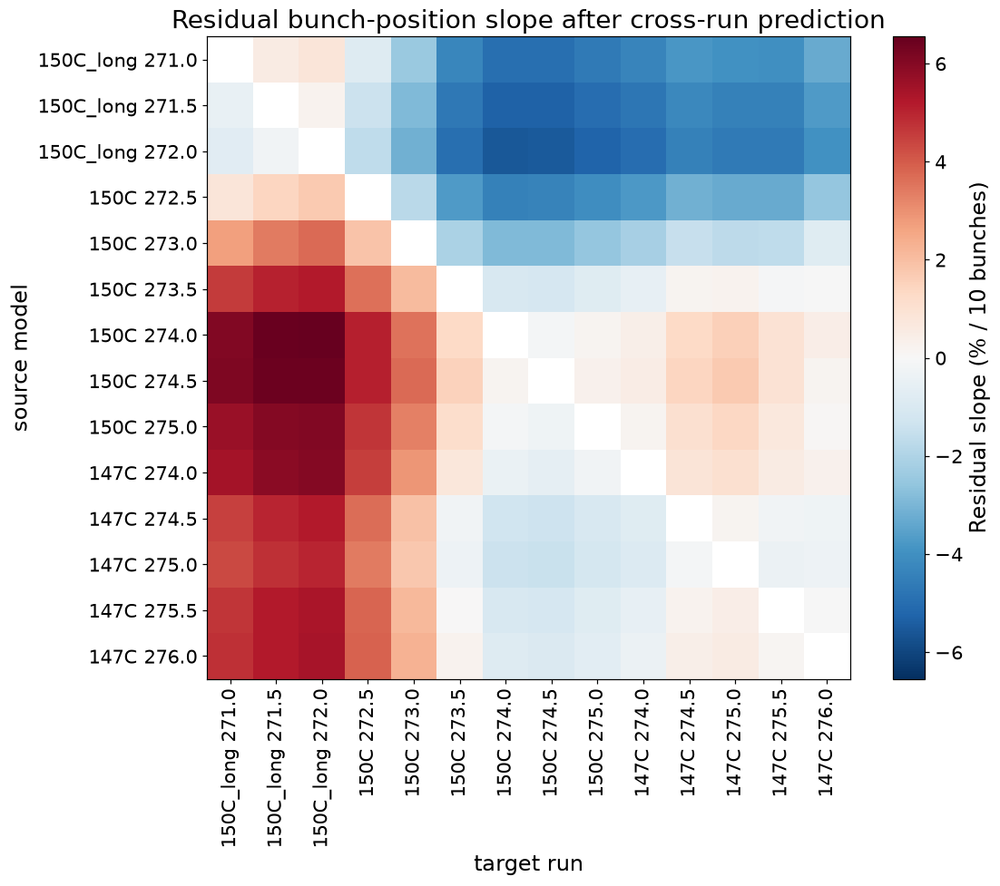

In [26]:
# --- Cross-run transferability: residual bunch-slope matrix ---
from matplotlib.colors import TwoSlopeNorm

vmax = np.nanmax(np.abs(transfer_residual_slope))
norm = TwoSlopeNorm(vmin=-vmax,vcenter=0,vmax=vmax)

fig,ax = plt.subplots(figsize=(11,9))
im = ax.imshow(np.ma.masked_invalid(transfer_residual_slope),cmap="RdBu_r",norm=norm,aspect="equal")

ax.set_xticks(np.arange(n_runs),labels,rotation=90)
ax.set_yticks(np.arange(n_runs),labels)
ax.set(xlabel="target run",ylabel="source model",title="Residual bunch-position slope after cross-run prediction")

fig.colorbar(im,ax=ax,label="Residual slope (% / 10 bunches)")
plt.tight_layout()
plt.show()

### Matrix uncertainties

150C_long 271.0 eV: 693 blocks, all 34625 trains included
150C_long 271.5 eV: 701 blocks, all 35025 trains included
150C_long 272.0 eV: 686 blocks, all 34285 trains included
150C 272.5 eV: 685 blocks, all 34219 trains included
150C 273.0 eV: 721 blocks, all 36010 trains included
150C 273.5 eV: 672 blocks, all 33577 trains included
150C 274.0 eV: 675 blocks, all 33711 trains included
150C 274.5 eV: 694 blocks, all 34687 trains included
150C 275.0 eV: 709 blocks, all 35439 trains included
147C 274.0 eV: 546 blocks, all 27291 trains included
147C 274.5 eV: 683 blocks, all 34147 trains included
147C 275.0 eV: 699 blocks, all 34933 trains included
147C 275.5 eV: 695 blocks, all 34742 trains included
147C 276.0 eV: 743 blocks, all 37148 trains included


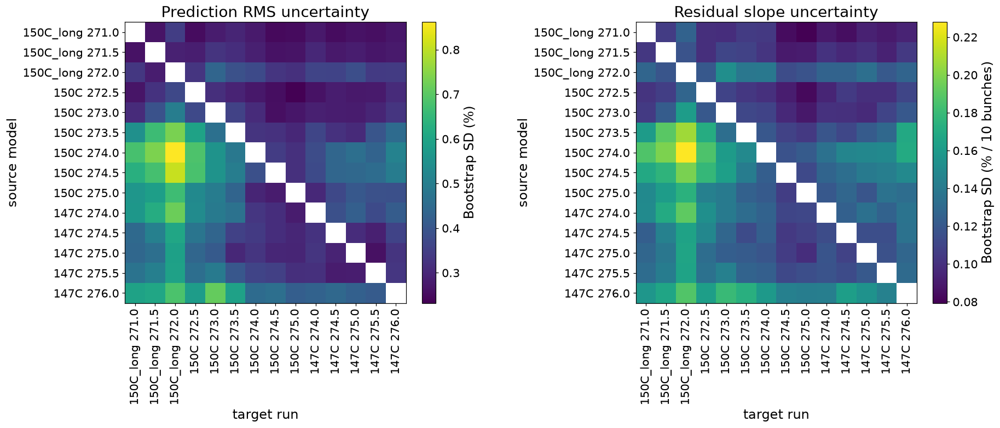

Uncertainty method: block bootstrap, first-order RMS propagation, approximate 95% intervals.
All trains included. Original prediction metrics unchanged.


In [27]:
# --- Block-bootstrap uncertainties for cross-run transferability matrices ---
TRANSFER_BOOTSTRAPS = 200
TRANSFER_BOOT_BLOCK_TRAINS = 50
TRANSFER_BOOT_SEED = 42

rng_transfer = np.random.default_rng(TRANSFER_BOOT_SEED)
n_common = min(RUN_DATA[key]["n_bunch"] for key in TRANSFER_RUNS)
boot_bunches = np.arange(TRANSFER_BUNCH_START,n_common)
n_runs = len(TRANSFER_RUNS)

def transfer_block_moments(run):
    """Sum shot-level OLS statistics in consecutive blocks of whole trains."""
    n_trains = run["n_trains"]
    n_blocks = int(np.ceil(n_trains/TRANSFER_BOOT_BLOCK_TRAINS))
    if n_blocks < 10:
        raise ValueError("Too few acquisition blocks for this bootstrap.")

    # Nearly equal block sizes; no trains are discarded.
    edges = np.linspace(0,n_trains,n_blocks+1,dtype=int)
    moments = np.zeros((n_blocks,5,n_common),dtype=float)

    for k,(start,stop) in enumerate(zip(edges[:-1],edges[1:])):
        gmd = run["gmd"][start:stop,:n_common]
        counts = run["ref_counts"][start:stop,:n_common]
        valid = run["daq_valid_rows"][start:stop,None] & np.isfinite(gmd) & (gmd >= TRANSFER_GMD_RANGE[0]) & (gmd < TRANSFER_GMD_RANGE[1])
        g = np.where(valid,gmd,0.0)
        y = np.where(valid,counts,0.0)

        moments[k,0] = valid.sum(axis=0)
        moments[k,1] = g.sum(axis=0)
        moments[k,2] = y.sum(axis=0)
        moments[k,3] = (g*g).sum(axis=0)
        moments[k,4] = (g*y).sum(axis=0)

    return moments

def transfer_fit_from_moments(m):
    n,sg,sy,sgg,sgy = m
    den = n*sgg-sg*sg
    good = (n >= TRANSFER_MIN_SHOTS) & (den > 0)
    a,b = np.full(n_common,np.nan),np.full(n_common,np.nan)
    b[good] = (n[good]*sgy[good]-sg[good]*sy[good])/den[good]
    a[good] = (sy[good]-b[good]*sg[good])/n[good]
    return a,b

def transfer_pair_metrics(a,b,m):
    """Evaluate one source model against target-run measurements."""
    n,sg,obs = m[:3]
    pred = a*n+b*sg
    sel = boot_bunches

    if np.any(~np.isfinite(pred[sel]) | (pred[sel] <= 0) | (n[sel] <= 0)):
        return None

    x = sel.astype(float)
    w = n[sel]
    observed = obs[sel]
    predicted = pred[sel]

    scale = observed.sum()/predicted.sum()
    if not np.isfinite(scale) or scale <= 0:
        return None

    ratio = observed/(scale*predicted)
    rms = 100*np.sqrt(np.average((ratio-1)**2,weights=w))

    x0,y0 = np.average(x,weights=w),np.average(ratio,weights=w)
    slope = 1000*np.sum(w*(x-x0)*(ratio-y0))/np.sum(w*(x-x0)**2)

    return rms,slope,ratio,w

# Store bootstrap summaries, not individual resampled shots.
TRANSFER_BOOT_DATA = {}
TRANSFER_FULL_MOMENTS = {}

for key in TRANSFER_RUNS:
    blocks = transfer_block_moments(RUN_DATA[key])
    n_blocks = len(blocks)
    TRANSFER_FULL_MOMENTS[key] = blocks.sum(axis=0)

    fits_a = np.full((TRANSFER_BOOTSTRAPS,n_common),np.nan)
    fits_b = np.full_like(fits_a,np.nan)
    target_stats = np.zeros((TRANSFER_BOOTSTRAPS,3,n_common))

    for k in range(TRANSFER_BOOTSTRAPS):
        sample = rng_transfer.integers(0,n_blocks,size=n_blocks)
        m = blocks[sample].sum(axis=0)
        fits_a[k],fits_b[k] = transfer_fit_from_moments(m)
        target_stats[k] = m[:3]

    TRANSFER_BOOT_DATA[key] = {"a":fits_a,"b":fits_b,"target":target_stats}
    print(f"{key[0]} {key[1]:.1f} eV: {n_blocks} blocks, all {RUN_DATA[key]['n_trains']} trains included")

# Recalculate the original statistics using the same full-data summaries.
baseline_rms = np.full((n_runs,n_runs),np.nan)
baseline_slope = np.full_like(baseline_rms,np.nan)
baseline_ratios = {}

for i,source in enumerate(TRANSFER_RUNS):
    a,b = transfer_fit_from_moments(TRANSFER_FULL_MOMENTS[source])

    for j,target in enumerate(TRANSFER_RUNS):
        if source == target: continue

        result = transfer_pair_metrics(a,b,TRANSFER_FULL_MOMENTS[target])
        if result is None:
            raise ValueError(f"Invalid full-data prediction: {source} -> {target}")

        baseline_rms[i,j],baseline_slope[i,j],ratio,w = result
        baseline_ratios[(i,j)] = (ratio,w)

# Confirm that the bootstrap uses exactly the same statistic as the existing matrices.
if not np.allclose(baseline_rms,transfer_rms,atol=1e-4,equal_nan=True):
    raise ValueError("RMS baseline differs from the original matrix. Rerun the direct transferability cell.")

if not np.allclose(baseline_slope,transfer_residual_slope,atol=1e-4,equal_nan=True):
    raise ValueError("Slope baseline differs from the original matrix. Rerun the direct transferability cell.")

# Bootstrap the residual slopes and linearized RMS errors.
boot_rms = np.full((TRANSFER_BOOTSTRAPS,n_runs,n_runs),np.nan)
boot_rms_delta = np.full_like(boot_rms,np.nan)
boot_slope = np.full_like(boot_rms,np.nan)

for k in range(TRANSFER_BOOTSTRAPS):
    for i,source in enumerate(TRANSFER_RUNS):
        a = TRANSFER_BOOT_DATA[source]["a"][k]
        b = TRANSFER_BOOT_DATA[source]["b"][k]

        for j,target in enumerate(TRANSFER_RUNS):
            if source == target: continue

            result = transfer_pair_metrics(a,b,TRANSFER_BOOT_DATA[target]["target"][k])
            if result is None: continue

            rms,slope,ratio,w = result
            boot_rms[k,i,j] = rms
            boot_slope[k,i,j] = slope

            # First-order change in the original RMS, avoiding the positive
            # bias caused by squaring additional bootstrap fluctuations.
            ratio0,w0 = baseline_ratios[(i,j)]
            residual0 = ratio0-1
            q0 = np.average(residual0**2,weights=w0)

            if q0 <= 0: continue

            dq = (
                2*np.sum(w0*residual0*(ratio-ratio0))
                + np.sum((w-w0)*(residual0**2-q0))
            )/w0.sum()

            boot_rms_delta[k,i,j] = 50*dq/np.sqrt(q0)

def bootstrap_matrix_uncertainty(values,centre,delta=False,nonnegative=False):
    """Bootstrap SD and approximate 95% intervals centred on full-data estimates."""
    se = np.full(centre.shape,np.nan)
    lower = np.full_like(se,np.nan)
    upper = np.full_like(se,np.nan)

    for i in range(centre.shape[0]):
        for j in range(centre.shape[1]):
            if not np.isfinite(centre[i,j]): continue

            sample = values[:,i,j]
            sample = sample[np.isfinite(sample)]
            if len(sample) < 0.8*TRANSFER_BOOTSTRAPS: continue

            se[i,j] = sample.std(ddof=1)
            lower[i,j] = centre[i,j]-1.96*se[i,j]
            upper[i,j] = centre[i,j]+1.96*se[i,j]

            if nonnegative:
                lower[i,j] = max(0.0,lower[i,j])

    return se,lower,upper

transfer_rms_se,transfer_rms_lo,transfer_rms_hi = bootstrap_matrix_uncertainty(
    boot_rms_delta,baseline_rms,delta=True,nonnegative=True
)

transfer_slope_se,transfer_slope_lo,transfer_slope_hi = bootstrap_matrix_uncertainty(
    boot_slope,baseline_slope
)

labels = [f"{group} {energy:.1f}" for group,energy in TRANSFER_RUNS]

fig,axes = plt.subplots(1,2,figsize=(17,7),constrained_layout=True)

for ax,values,title,label in [
    (axes[0],transfer_rms_se,"Prediction RMS uncertainty","Bootstrap SD (%)"),
    (axes[1],transfer_slope_se,"Residual slope uncertainty","Bootstrap SD (% / 10 bunches)")
]:
    im = ax.imshow(np.ma.masked_invalid(values),cmap="viridis",aspect="equal")
    ax.set_xticks(np.arange(n_runs),labels,rotation=90)
    ax.set_yticks(np.arange(n_runs),labels)
    ax.set(xlabel="target run",ylabel="source model",title=title)
    fig.colorbar(im,ax=ax,label=label)

plt.show()

print("Uncertainty method: block bootstrap, first-order RMS propagation, approximate 95% intervals.")
print("All trains included. Original prediction metrics unchanged.")

In [28]:
# --- Selected source-target comparisons with bootstrap confidence intervals ---
TRANSFER_CHECK_PAIRS = [
    (("150C_long",272.0),("150C",274.0)),
    (("150C",274.0),("150C",274.5)),
    (("150C",274.0),("147C",274.0)),
    (("150C",275.0),("147C",275.0)),
    (("147C",274.5),("147C",275.0)),
]

rows = []

for source,target in TRANSFER_CHECK_PAIRS:
    i,j = TRANSFER_RUNS.index(source),TRANSFER_RUNS.index(target)
    rows.append({
        "source":f"{source[0]} {source[1]:.1f}",
        "target":f"{target[0]} {target[1]:.1f}",
        "RMS (%)":f"{transfer_rms[i,j]:.2f} ± {transfer_rms_se[i,j]:.2f}",
        "RMS 95% CI":f"[{transfer_rms_lo[i,j]:.2f}, {transfer_rms_hi[i,j]:.2f}]",
        "slope (%/10)":f"{transfer_residual_slope[i,j]:+.2f} ± {transfer_slope_se[i,j]:.2f}",
        "slope 95% CI":f"[{transfer_slope_lo[i,j]:+.2f}, {transfer_slope_hi[i,j]:+.2f}]",
    })

display(pd.DataFrame(rows))

,source,target,RMS (%),RMS 95% CI,slope (%/10),slope 95% CI
0,150C_long 272.0,150C 274.0,20.12 ± 0.37,"[19.39, 20.85]",-5.55 ± 0.14,"[-5.83, -5.28]"
1,150C 274.0,150C 274.5,3.18 ± 0.34,"[2.51, 3.85]",-0.14 ± 0.12,"[-0.36, +0.09]"
2,150C 274.0,147C 274.0,4.65 ± 0.38,"[3.90, 5.39]",+0.41 ± 0.13,"[+0.14, +0.67]"
3,150C 275.0,147C 275.0,7.45 ± 0.40,"[6.66, 8.25]",+1.36 ± 0.12,"[+1.13, +1.59]"
4,147C 274.5,147C 275.0,3.13 ± 0.31,"[2.52, 3.74]",+0.18 ± 0.11,"[-0.05, +0.40]"


## Ion Electron investigations

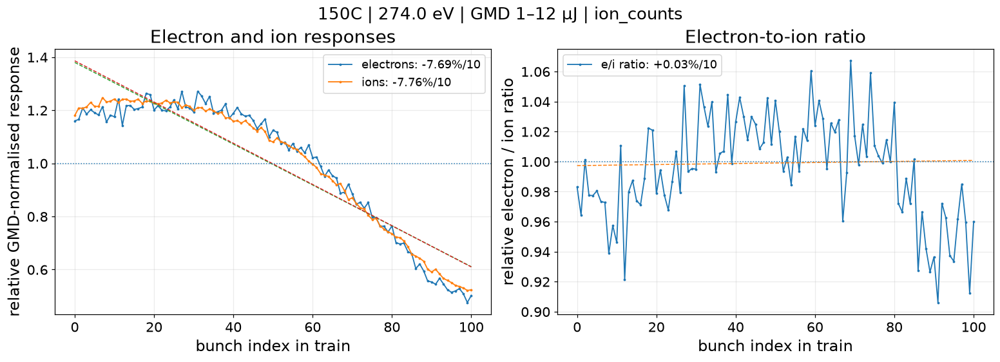

,shots,sum_gmd,sum_electrons,sum_ions,e_rel,i_rel,ratio_rel
bunch,,,,,,,
0,30310,121334.28077,1655.0,13631.0,1.15981,1.17988,0.98299
1,30836,130030.31849,1782.0,14960.0,1.16529,1.20832,0.96440
2,30921,137485.39174,1954.0,15804.0,1.20848,1.20727,1.00101
3,31026,141771.95010,1976.0,16367.0,1.18514,1.21247,0.97746
4,31036,144215.60612,2038.0,16882.0,1.20161,1.22943,0.97737
5,31057,144902.08203,2029.0,16754.0,1.19064,1.21433,0.98049
6,31139,147669.92065,2053.0,17075.0,1.18214,1.21440,0.97344
7,31086,148704.74527,2122.0,17661.0,1.21337,1.24734,0.97277
8,31137,150077.35968,2040.0,17592.0,1.15581,1.23110,0.93885


Electron slope      : -7.692% / 10 bunches
Ion slope           : -7.760% / 10 bunches
Electron/ion slope  : +0.034% / 10 bunches
Electron/ion mean   : 0.12352 electrons per ion


In [29]:
# --- Electron/ion comparison for one run ---
EI_COMPARE_RUN = ("150C",274.0)
EI_COMPARE_GMD_RANGE = (1.0,12.0)
EI_COMPARE_BUNCH_START = 0
EI_COMPARE_ION_KEY = "ion_counts"  # "ion_counts_main" or "ion_counts"

run = RUN_DATA[EI_COMPARE_RUN]
gmd_ei = run["gmd"]
e_counts = run["ref_counts"]
i_counts = run[EI_COMPARE_ION_KEY]
daq_valid_ei = run["daq_valid_rows"]
n_trains_ei,n_bunch_ei = gmd_ei.shape
bunches_ei = np.arange(EI_COMPARE_BUNCH_START,n_bunch_ei)

def weighted_line(x,y,w):
    good = np.isfinite(x) & np.isfinite(y) & np.isfinite(w) & (w > 0)
    if good.sum() < 2: return np.nan,np.nan
    xg,yg,wg = x[good],y[good],w[good]
    x0 = np.average(xg,weights=wg)
    y0 = np.average(yg,weights=wg)
    m = np.sum(wg*(xg-x0)*(yg-y0))/np.sum(wg*(xg-x0)**2)
    c = y0-m*x0
    return m,c

sum_g = np.zeros(n_bunch_ei)
sum_e = np.zeros(n_bunch_ei)
sum_i = np.zeros(n_bunch_ei)
shots_ei = np.zeros(n_bunch_ei,dtype=int)

for b in bunches_ei:
    sel = daq_valid_ei & np.isfinite(gmd_ei[:,b]) & (gmd_ei[:,b] >= EI_COMPARE_GMD_RANGE[0]) & (gmd_ei[:,b] < EI_COMPARE_GMD_RANGE[1])
    shots_ei[b] = sel.sum()
    sum_g[b] = gmd_ei[sel,b].sum()
    sum_e[b] = e_counts[sel,b].sum()
    sum_i[b] = i_counts[sel,b].sum()

e_yield = np.divide(sum_e,sum_g,out=np.full(n_bunch_ei,np.nan),where=sum_g > 0)
i_yield = np.divide(sum_i,sum_g,out=np.full(n_bunch_ei,np.nan),where=sum_g > 0)

valid_total = (sum_g[bunches_ei] > 0) & (sum_i[bunches_ei] > 0)
if valid_total.sum() < 3:
    raise ValueError("Too few valid bunch positions for electron/ion comparison.")

b_fit = bunches_ei[valid_total]
g_fit = sum_g[b_fit]
e_fit = sum_e[b_fit]
i_fit = sum_i[b_fit]
shots_fit = shots_ei[b_fit]

e_scale = e_fit.sum()/g_fit.sum()
i_scale = i_fit.sum()/g_fit.sum()
ratio_scale = e_fit.sum()/i_fit.sum()

e_rel = e_yield/e_scale
i_rel = i_yield/i_scale
ratio_rel = np.divide(sum_e,sum_i,out=np.full(n_bunch_ei,np.nan),where=sum_i > 0)/ratio_scale

e_err = np.divide(np.sqrt(sum_e),sum_g,out=np.full(n_bunch_ei,np.nan),where=sum_g > 0)/e_scale
i_err = np.divide(np.sqrt(sum_i),sum_g,out=np.full(n_bunch_ei,np.nan),where=sum_g > 0)/i_scale
ratio_err = np.full(n_bunch_ei,np.nan)
valid_ratio = (sum_e > 0) & (sum_i > 0)
ratio_err[valid_ratio] = ratio_rel[valid_ratio]*np.sqrt(1/sum_e[valid_ratio] + 1/sum_i[valid_ratio])

e_slope_raw,e_int = weighted_line(b_fit,e_rel[b_fit],shots_fit)
i_slope_raw,i_int = weighted_line(b_fit,i_rel[b_fit],shots_fit)
ratio_w = np.divide(1,ratio_err[b_fit]**2,out=np.zeros_like(ratio_err[b_fit]),where=np.isfinite(ratio_err[b_fit]) & (ratio_err[b_fit] > 0))
ratio_slope_raw,ratio_int = weighted_line(b_fit,ratio_rel[b_fit],ratio_w)

fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)

axes[0].plot(b_fit,e_rel[b_fit],".-",ms=3,lw=1.2,label=f"electrons: {1000*e_slope_raw:+.2f}%/10")
axes[0].plot(b_fit,i_rel[b_fit],".-",ms=3,lw=1.2,label=f"ions: {1000*i_slope_raw:+.2f}%/10")
axes[0].plot([b_fit[0],b_fit[-1]],e_int+e_slope_raw*np.array([b_fit[0],b_fit[-1]]),"--",lw=1)
axes[0].plot([b_fit[0],b_fit[-1]],i_int+i_slope_raw*np.array([b_fit[0],b_fit[-1]]),"--",lw=1)
axes[0].axhline(1,ls=":",lw=1)
axes[0].set(xlabel="bunch index in train",ylabel="relative GMD-normalised response",title="Electron and ion responses")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(b_fit,ratio_rel[b_fit],".-",ms=3,lw=1.2,label=f"e/i ratio: {1000*ratio_slope_raw:+.2f}%/10")
axes[1].plot([b_fit[0],b_fit[-1]],ratio_int+ratio_slope_raw*np.array([b_fit[0],b_fit[-1]]),"--",lw=1)
axes[1].axhline(1,ls=":",lw=1)
axes[1].set(xlabel="bunch index in train",ylabel="relative electron / ion ratio",title="Electron-to-ion ratio")
axes[1].grid(alpha=0.25)
axes[1].legend()

fig.suptitle(
    f"{EI_COMPARE_RUN[0]} | {EI_COMPARE_RUN[1]:.1f} eV | "
    f"GMD {EI_COMPARE_GMD_RANGE[0]:g}–{EI_COMPARE_GMD_RANGE[1]:g} µJ | "
    f"{EI_COMPARE_ION_KEY}"
)
plt.show()

display(pd.DataFrame({
    "bunch":b_fit,
    "shots":shots_fit,
    "sum_gmd":sum_g[b_fit],
    "sum_electrons":sum_e[b_fit],
    "sum_ions":sum_i[b_fit],
    "e_rel":e_rel[b_fit],
    "i_rel":i_rel[b_fit],
    "ratio_rel":ratio_rel[b_fit],
}).set_index("bunch").round(5).head(10))

print(f"Electron slope      : {1000*e_slope_raw:+.3f}% / 10 bunches")
print(f"Ion slope           : {1000*i_slope_raw:+.3f}% / 10 bunches")
print(f"Electron/ion slope  : {1000*ratio_slope_raw:+.3f}% / 10 bunches")
print(f"Electron/ion mean   : {ratio_scale:.5f} electrons per ion")

150C_long    271.0 eV | e -3.20 ± 0.06 | i -4.84 ± 0.05 | e/i slope ratio 0.660 ± 0.012
150C_long    271.5 eV | e -2.74 ± 0.07 | i -4.28 ± 0.05 | e/i slope ratio 0.641 ± 0.014
150C_long    272.0 eV | e -2.49 ± 0.10 | i -3.89 ± 0.05 | e/i slope ratio 0.640 ± 0.024
150C         272.5 eV | e -3.95 ± 0.08 | i -5.28 ± 0.05 | e/i slope ratio 0.747 ± 0.012
150C         273.0 eV | e -5.53 ± 0.08 | i -6.41 ± 0.04 | e/i slope ratio 0.864 ± 0.012
150C         273.5 eV | e -7.18 ± 0.08 | i -7.47 ± 0.04 | e/i slope ratio 0.961 ± 0.011
150C         274.0 eV | e -7.69 ± 0.09 | i -7.76 ± 0.03 | e/i slope ratio 0.991 ± 0.011
150C         274.5 eV | e -7.64 ± 0.07 | i -8.09 ± 0.03 | e/i slope ratio 0.944 ± 0.008
150C         275.0 eV | e -7.44 ± 0.06 | i -8.10 ± 0.04 | e/i slope ratio 0.919 ± 0.007
147C         274.0 eV | e -7.21 ± 0.07 | i -7.38 ± 0.04 | e/i slope ratio 0.976 ± 0.009
147C         274.5 eV | e -6.65 ± 0.06 | i -6.83 ± 0.03 | e/i slope ratio 0.974 ± 0.009
147C         275.0 eV | e -6.73 

,group,energy,electron slope,electron SD,ion slope,ion SD,slope ratio,slope ratio SD,valid bunches
0,150C_long,271.0,-3.1983,0.0639,-4.8443,0.0471,0.6602,0.0116,101
1,150C_long,271.5,-2.7405,0.0688,-4.2752,0.0490,0.6410,0.0144,101
2,150C_long,272.0,-2.4878,0.0954,-3.8858,0.0478,0.6402,0.0238,101
3,150C,272.5,-3.9468,0.0776,-5.2827,0.0514,0.7471,0.0121,101
4,150C,273.0,-5.5336,0.0766,-6.4071,0.0394,0.8637,0.0120,101
5,150C,273.5,-7.1783,0.0819,-7.4722,0.0369,0.9607,0.0109,101
6,150C,274.0,-7.6918,0.0876,-7.7598,0.0337,0.9912,0.0109,101
7,150C,274.5,-7.6401,0.0660,-8.0948,0.0332,0.9438,0.0078,101
8,150C,275.0,-7.4443,0.0604,-8.1001,0.0373,0.9190,0.0065,101
9,147C,274.0,-7.2052,0.0708,-7.3815,0.0353,0.9761,0.0089,101


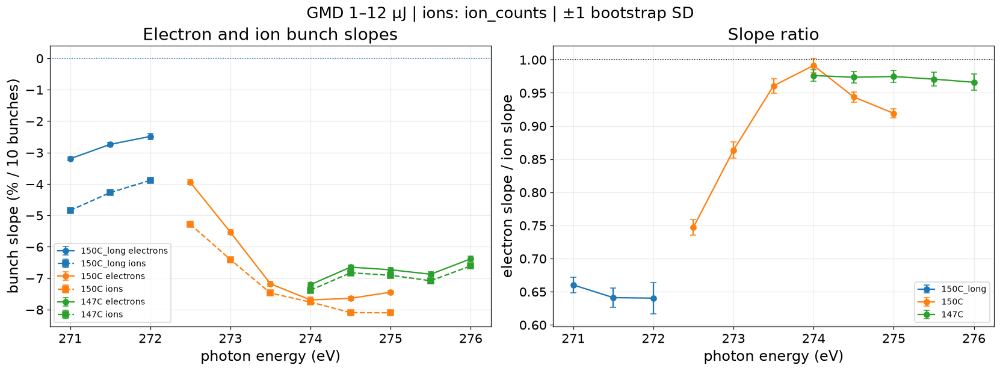

In [30]:
# --- Electron and ion slope summary across all runs: actual slopes + slope ratio ---
EI_SUMMARY_RUNS = list(SELECT_RUNS)
EI_SUMMARY_ION_KEY = "ion_counts"   # safer default for now
EI_SUMMARY_GMD_RANGE = (1.0,12.0)
EI_SUMMARY_BUNCH_START = 0
EI_SUMMARY_N_BOOT = 300
EI_SUMMARY_BLOCK_TRAINS = 50
EI_SUMMARY_SEED = 42

rng_ei = np.random.default_rng(EI_SUMMARY_SEED)

def ei_weighted_line(x,y,w):
    x0 = np.average(x,weights=w)
    y0 = np.average(y,weights=w)
    slope = np.sum(w*(x-x0)*(y-y0))/np.sum(w*(x-x0)**2)
    intercept = y0-slope*x0
    return slope,intercept

def ei_run_moments(run):
    n_trains,n_bunch = run["gmd"].shape
    n_blocks = int(np.ceil(n_trains/EI_SUMMARY_BLOCK_TRAINS))
    if n_blocks < 10:
        raise ValueError("Too few acquisition blocks for bootstrap.")
    edges = np.linspace(0,n_trains,n_blocks+1,dtype=int)
    blocks = np.zeros((n_blocks,4,n_bunch),dtype=float)

    for k,(start,stop) in enumerate(zip(edges[:-1],edges[1:])):
        g = run["gmd"][start:stop]
        valid = run["daq_valid_rows"][start:stop,None] & np.isfinite(g) & (g >= EI_SUMMARY_GMD_RANGE[0]) & (g < EI_SUMMARY_GMD_RANGE[1])
        blocks[k,0] = valid.sum(axis=0)
        blocks[k,1] = np.where(valid,g,0).sum(axis=0)
        blocks[k,2] = np.where(valid,run["ref_counts"][start:stop],0).sum(axis=0)
        blocks[k,3] = np.where(valid,run[EI_SUMMARY_ION_KEY][start:stop],0).sum(axis=0)

    return blocks

def ei_summary_metrics(m):
    shots,gmd,electrons,ions = m
    bunches = np.arange(EI_SUMMARY_BUNCH_START,len(shots))
    good = (shots[bunches] > 0) & (gmd[bunches] > 0) & (electrons[bunches] > 0) & (ions[bunches] > 0)
    if good.sum() < 20:
        return None

    b = bunches[good].astype(float)
    n = shots[bunches][good]
    g = gmd[bunches][good]
    e = electrons[bunches][good]
    i = ions[bunches][good]

    e_rel = (e/g)/(e.sum()/g.sum())
    i_rel = (i/g)/(i.sum()/g.sum())

    e_slope,_ = ei_weighted_line(b,e_rel,n)
    i_slope,_ = ei_weighted_line(b,i_rel,n)

    if not np.isfinite(i_slope) or np.isclose(i_slope,0.0):
        slope_ratio = np.nan
    else:
        slope_ratio = e_slope/i_slope

    return {
        "electron slope":1000*e_slope,
        "ion slope":1000*i_slope,
        "slope ratio":slope_ratio,
        "valid bunches":int(good.sum())
    }

EI_SUMMARY_RESULTS = []

for key in EI_SUMMARY_RUNS:
    if key not in RUN_DATA:
        raise KeyError(f"Run {key} is not loaded.")
    if EI_SUMMARY_ION_KEY not in RUN_DATA[key]:
        raise KeyError(f"{key}: missing {EI_SUMMARY_ION_KEY}. Rerun the multi-run loader.")

    group,energy = key
    blocks = ei_run_moments(RUN_DATA[key])
    result = ei_summary_metrics(blocks.sum(axis=0))
    if result is None:
        raise ValueError(f"Insufficient valid data for {key}.")

    n_blocks = len(blocks)
    weights = rng_ei.multinomial(n_blocks,np.full(n_blocks,1/n_blocks),size=EI_SUMMARY_N_BOOT)
    boot_metrics = np.full((EI_SUMMARY_N_BOOT,3),np.nan)

    for k,w in enumerate(weights):
        m = np.einsum("b,bcj->cj",w,blocks,optimize=True)
        boot_result = ei_summary_metrics(m)
        if boot_result is None:
            continue
        boot_metrics[k,0] = boot_result["electron slope"]
        boot_metrics[k,1] = boot_result["ion slope"]
        boot_metrics[k,2] = boot_result["slope ratio"]

    if np.any(np.isfinite(boot_metrics[:,:2]).sum(axis=0) < 0.8*EI_SUMMARY_N_BOOT):
        raise ValueError(f"Too many invalid bootstrap samples for {key}.")

    electron_sd = np.nanstd(boot_metrics[:,0],ddof=1)
    ion_sd = np.nanstd(boot_metrics[:,1],ddof=1)
    ratio_sd = np.nanstd(boot_metrics[:,2],ddof=1)

    EI_SUMMARY_RESULTS.append({
        "group":group,
        "energy":energy,
        "electron slope":result["electron slope"],
        "electron SD":electron_sd,
        "ion slope":result["ion slope"],
        "ion SD":ion_sd,
        "slope ratio":result["slope ratio"],
        "slope ratio SD":ratio_sd,
        "valid bunches":result["valid bunches"]
    })

    print(
        f"{group:12s} {energy:.1f} eV | "
        f"e {result['electron slope']:+.2f} ± {electron_sd:.2f} | "
        f"i {result['ion slope']:+.2f} ± {ion_sd:.2f} | "
        f"e/i slope ratio {result['slope ratio']:.3f} ± {ratio_sd:.3f}"
    )

ei_summary_table = pd.DataFrame(EI_SUMMARY_RESULTS)
display(ei_summary_table.round(4))

fig,axes = plt.subplots(1,2,figsize=(15,5.5),constrained_layout=True)
group_colors = {"150C_long":"C0","150C":"C1","147C":"C2"}

for group,df in ei_summary_table.groupby("group",sort=False):
    df = df.sort_values("energy")
    color = group_colors.get(group,None)
    x = df["energy"].to_numpy()

    axes[0].errorbar(x,df["electron slope"],yerr=df["electron SD"],fmt="o-",color=color,capsize=3,lw=1.5,label=f"{group} electrons")
    axes[0].errorbar(x,df["ion slope"],yerr=df["ion SD"],fmt="s--",color=color,capsize=3,lw=1.5,label=f"{group} ions")

    axes[1].errorbar(x,df["slope ratio"],yerr=df["slope ratio SD"],fmt="o-",color=color,capsize=3,lw=1.5,label=group)

axes[0].axhline(0,ls=":",lw=1)
axes[0].set(xlabel="photon energy (eV)",ylabel="bunch slope (% / 10 bunches)",title="Electron and ion bunch slopes")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=9)

axes[1].axhline(1,ls=":",lw=1,color="k")
axes[1].set(xlabel="photon energy (eV)",ylabel="electron slope / ion slope",title="Slope ratio")
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=9)

fig.suptitle(f"GMD {EI_SUMMARY_GMD_RANGE[0]:g}–{EI_SUMMARY_GMD_RANGE[1]:g} µJ | ions: {EI_SUMMARY_ION_KEY} | ±1 bootstrap SD")
plt.show()

Processed 150C_long, 271.0 eV
Processed 150C_long, 271.5 eV
Processed 150C_long, 272.0 eV
Processed 150C, 272.5 eV
Processed 150C, 273.0 eV
Processed 150C, 273.5 eV
Processed 150C, 274.0 eV
Processed 150C, 274.5 eV
Processed 150C, 275.0 eV
Processed 147C, 274.0 eV
Processed 147C, 274.5 eV
Processed 147C, 275.0 eV
Processed 147C, 275.5 eV
Processed 147C, 276.0 eV

Curvature across photon energies (GMD 1–12 µJ):


,group,energy,GMD band,arch (%),arch SD,CI lower,CI upper,constant RMS (%),linear RMS (%),quadratic RMS (%),valid bunches
0,150C_long,271.0,All 1–12 µJ,2.001,0.562,0.977,3.022,4.769,1.511,1.407,101
5,150C_long,271.5,All 1–12 µJ,0.606,0.582,-0.546,1.699,4.348,1.513,1.504,101
10,150C_long,272.0,All 1–12 µJ,-1.847,0.880,-3.327,0.052,4.158,2.069,2.011,101
15,150C,272.5,All 1–12 µJ,-0.360,0.684,-1.651,0.975,3.926,1.738,1.735,101
20,150C,273.0,All 1–12 µJ,-5.573,0.791,-7.057,-4.128,3.538,2.580,2.058,101
25,150C,273.5,All 1–12 µJ,-3.451,0.900,-5.114,-1.702,2.614,2.468,2.272,101
30,150C,274.0,All 1–12 µJ,7.794,0.804,6.341,9.316,3.225,3.224,2.373,101
35,150C,274.5,All 1–12 µJ,9.995,0.615,8.775,11.186,3.751,3.523,2.167,101
40,150C,275.0,All 1–12 µJ,8.255,0.616,7.096,9.463,3.392,2.771,1.572,101
45,147C,274.0,All 1–12 µJ,9.138,0.714,7.873,10.495,3.202,3.160,1.901,101



GMD-resolved curvature: ('150C', 274.0)


,group,energy,GMD band,arch (%),arch SD,CI lower,CI upper,constant RMS (%),linear RMS (%),quadratic RMS (%),valid bunches
30,150C,274.0,All 1–12 µJ,7.794,0.804,6.341,9.316,3.225,3.224,2.373,101
31,150C,274.0,1–3 µJ,8.060,3.173,1.066,12.953,10.247,10.111,9.799,101
32,150C,274.0,3–5 µJ,9.695,1.985,5.965,13.651,6.806,6.775,6.130,101
33,150C,274.0,5–8 µJ,8.121,1.320,5.569,10.971,4.347,4.331,3.692,101
34,150C,274.0,8–12 µJ,6.987,1.461,4.503,10.334,4.458,4.456,4.093,101


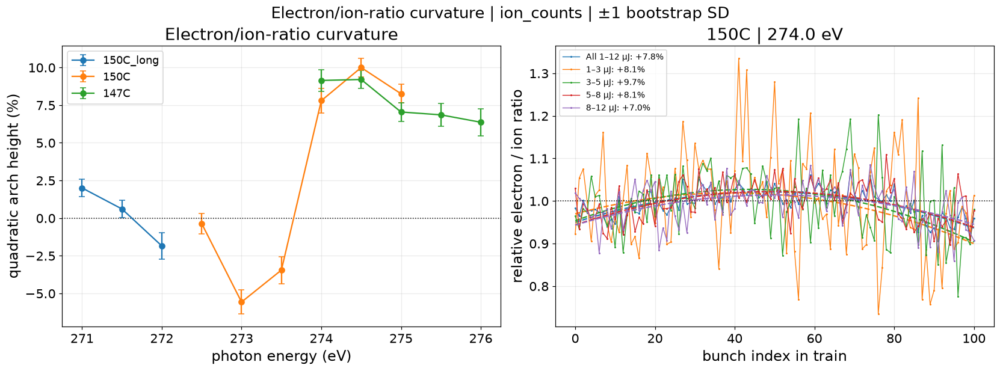

In [31]:
# --- Electron/ion-ratio curvature versus photon energy and GMD ---
EI_CURV_RUNS = list(SELECT_RUNS)
EI_CURV_VIEW_RUN = ("150C",274.0)
EI_CURV_ION_KEY = "ion_counts"
EI_CURV_BUNCH_START = 0
EI_CURV_N_BOOT = 300
EI_CURV_BLOCK_TRAINS = 50
EI_CURV_SEED = 42
EI_CURV_MIN_BUNCHES = 50

EI_CURV_BANDS = [
    ("All 1–12 µJ",(1,12)),
    ("1–3 µJ",(1,3)),
    ("3–5 µJ",(3,5)),
    ("5–8 µJ",(5,8)),
    ("8–12 µJ",(8,12)),
]

if EI_CURV_VIEW_RUN not in EI_CURV_RUNS:
    raise ValueError("EI_CURV_VIEW_RUN must be included in EI_CURV_RUNS.")

rng_curv = np.random.default_rng(EI_CURV_SEED)

def ei_curv_block_moments(run):
    """Aggregate paired electron/ion counts in blocks of whole trains."""
    n_trains,n_bunch = run["gmd"].shape
    n_blocks = int(np.ceil(n_trains/EI_CURV_BLOCK_TRAINS))
    if n_blocks < 10: raise ValueError("Too few acquisition blocks for bootstrap.")
    edges = np.linspace(0,n_trains,n_blocks+1,dtype=int)
    blocks = np.zeros((n_blocks,len(EI_CURV_BANDS),4,n_bunch),dtype=float)

    for k,(start,stop) in enumerate(zip(edges[:-1],edges[1:])):
        g = run["gmd"][start:stop]
        valid_daq = run["daq_valid_rows"][start:stop,None] & np.isfinite(g)
        e = run["ref_counts"][start:stop]
        i = run[EI_CURV_ION_KEY][start:stop]

        for j,(label,(lo,hi)) in enumerate(EI_CURV_BANDS):
            valid = valid_daq & (g >= lo) & (g < hi)
            blocks[k,j,0] = valid.sum(axis=0)
            blocks[k,j,1] = np.where(valid,g,0).sum(axis=0)
            blocks[k,j,2] = np.where(valid,e,0).sum(axis=0)
            blocks[k,j,3] = np.where(valid,i,0).sum(axis=0)

    return blocks

def ei_curv_metrics(m):
    """Fit constant, linear and quadratic models to the normalized electron/ion ratio."""
    shots,gmd,electrons,ions = m
    bunches = np.arange(EI_CURV_BUNCH_START,len(shots))
    valid = (shots[bunches] > 0) & (gmd[bunches] > 0) & (electrons[bunches] > 0) & (ions[bunches] > 0)
    if valid.sum() < EI_CURV_MIN_BUNCHES: return None

    b = bunches[valid].astype(float)
    e,i = electrons[bunches][valid],ions[bunches][valid]
    ratio = (e/i)/(e.sum()/i.sum())

    # Scale bunch positions to approximately -1 to +1.
    centre = (EI_CURV_BUNCH_START+len(shots)-1)/2
    halfwidth = (len(shots)-1-EI_CURV_BUNCH_START)/2
    if halfwidth <= 0: return None
    x = (b-centre)/halfwidth

    # Approximate inverse-variance weights; bootstrap retains electron-ion correlations.
    variance = ratio**2*(1/e+1/i)
    w = 1/variance
    sqrt_w = np.sqrt(w)

    X_linear = np.column_stack((np.ones_like(x),x))
    X_quad = np.column_stack((np.ones_like(x),x,x*x))
    beta_linear = np.linalg.lstsq(X_linear*sqrt_w[:,None],ratio*sqrt_w,rcond=None)[0]
    beta_quad = np.linalg.lstsq(X_quad*sqrt_w[:,None],ratio*sqrt_w,rcond=None)[0]

    constant_fit = np.full_like(ratio,np.average(ratio,weights=w))
    linear_fit = X_linear@beta_linear
    quad_fit = X_quad@beta_quad

    def residual_rms(fit):
        return 100*np.sqrt(np.average((ratio-fit)**2,weights=w))

    return {
        "arch (%)":-100*beta_quad[2],
        "constant RMS (%)":residual_rms(constant_fit),
        "linear RMS (%)":residual_rms(linear_fit),
        "quadratic RMS (%)":residual_rms(quad_fit),
        "valid bunches":len(b),
        "bunch":b,
        "ratio":ratio,
        "quadratic fit":quad_fit
    }

EI_CURV_RESULTS = []
EI_CURV_PROFILES = {}

for key in EI_CURV_RUNS:
    if key not in RUN_DATA: raise KeyError(f"Run not loaded: {key}")
    if EI_CURV_ION_KEY not in RUN_DATA[key]: raise KeyError(f"Missing {EI_CURV_ION_KEY} in {key}")

    group,energy = key
    blocks = ei_curv_block_moments(RUN_DATA[key])
    full_moments = blocks.sum(axis=0)

    # Resample the same blocks for electrons and ions.
    n_blocks = len(blocks)
    draws = rng_curv.multinomial(n_blocks,np.full(n_blocks,1/n_blocks),size=EI_CURV_N_BOOT)
    boot_moments = np.einsum("kb,brsj->krsj",draws,blocks,optimize=True)
    boot_arch = np.full((EI_CURV_N_BOOT,len(EI_CURV_BANDS)),np.nan)

    for j,(label,gmd_range) in enumerate(EI_CURV_BANDS):
        result = ei_curv_metrics(full_moments[j])
        if result is None:
            print(f"Insufficient data: {group} {energy:.1f} eV, {label}")
            continue

        for k in range(EI_CURV_N_BOOT):
            boot_result = ei_curv_metrics(boot_moments[k,j])
            if boot_result is not None: boot_arch[k,j] = boot_result["arch (%)"]

        valid_boot = boot_arch[:,j][np.isfinite(boot_arch[:,j])]
        arch_sd = np.std(valid_boot,ddof=1) if len(valid_boot) >= 0.8*EI_CURV_N_BOOT else np.nan
        ci_lo,ci_hi = np.percentile(valid_boot,[2.5,97.5]) if len(valid_boot) >= 0.8*EI_CURV_N_BOOT else (np.nan,np.nan)

        EI_CURV_RESULTS.append({
            "group":group,"energy":energy,"GMD band":label,
            "arch (%)":result["arch (%)"],"arch SD":arch_sd,
            "CI lower":ci_lo,"CI upper":ci_hi,
            "constant RMS (%)":result["constant RMS (%)"],
            "linear RMS (%)":result["linear RMS (%)"],
            "quadratic RMS (%)":result["quadratic RMS (%)"],
            "valid bunches":result["valid bunches"]
        })

        if key == EI_CURV_VIEW_RUN: EI_CURV_PROFILES[label] = result

    print(f"Processed {group}, {energy:.1f} eV")

ei_curv_table = pd.DataFrame(EI_CURV_RESULTS)

# --- Summary table: full GMD range ---
print("\nCurvature across photon energies (GMD 1–12 µJ):")
display(ei_curv_table[ei_curv_table["GMD band"] == "All 1–12 µJ"].round(3))

# --- Detailed table: selected run, separated GMD bands ---
print(f"\nGMD-resolved curvature: {EI_CURV_VIEW_RUN}")
view_table = ei_curv_table[(ei_curv_table["group"] == EI_CURV_VIEW_RUN[0]) & (ei_curv_table["energy"] == EI_CURV_VIEW_RUN[1])]
display(view_table.round(3))

# --- Plots ---
fig,axes = plt.subplots(1,2,figsize=(15,5.5),constrained_layout=True)
group_colors = {"150C_long":"C0","150C":"C1","147C":"C2"}

full_table = ei_curv_table[ei_curv_table["GMD band"] == "All 1–12 µJ"]

for group,df in full_table.groupby("group",sort=False):
    df = df.sort_values("energy")
    axes[0].errorbar(df["energy"],df["arch (%)"],yerr=df["arch SD"],fmt="o-",color=group_colors.get(group),capsize=3,lw=1.5,label=group)

axes[0].axhline(0,ls=":",lw=1,color="k")
axes[0].set(xlabel="photon energy (eV)",ylabel="quadratic arch height (%)",title="Electron/ion-ratio curvature")
axes[0].grid(alpha=0.25)
axes[0].legend()

for label,result in EI_CURV_PROFILES.items():
    b = result["bunch"]
    line, = axes[1].plot(b,result["ratio"],".-",ms=2,lw=0.9,label=f"{label}: {result['arch (%)']:+.1f}%")
    axes[1].plot(b,result["quadratic fit"],"--",color=line.get_color(),lw=1.5)

axes[1].axhline(1,ls=":",lw=1,color="k")
axes[1].set(xlabel="bunch index in train",ylabel="relative electron / ion ratio",title=f"{EI_CURV_VIEW_RUN[0]} | {EI_CURV_VIEW_RUN[1]:.1f} eV")
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=9)

fig.suptitle(f"Electron/ion-ratio curvature | {EI_CURV_ION_KEY} | ±1 bootstrap SD")
plt.show()

### Stability between first and second halves

,half,trains,selected shots,mean GMD,absolute e/i,arch (%),arch SD,CI lower,CI upper
0,First half,17466,1449556,5.0832,0.1452,6.9526,0.9180,5.1764,8.8369
1,Second half,17467,1536320,5.1337,0.1442,7.3649,0.9462,5.6008,9.3633


Arch difference (second - first): +0.412 percentage points
95% bootstrap CI for difference: [-2.127, +2.895]


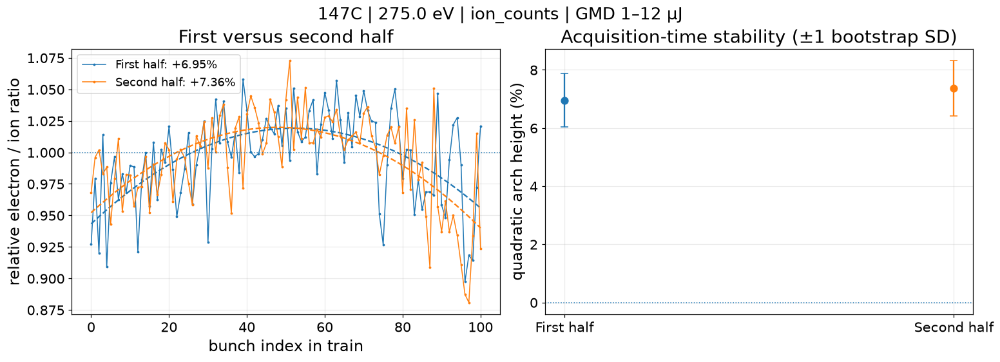

In [32]:
# --- Stability of electron/ion-ratio curvature across acquisition time ---
EI_STAB_RUN = ("147C",275.0)
EI_STAB_ION_KEY = "ion_counts"
EI_STAB_GMD_RANGE = (1.0,12.0)
EI_STAB_BUNCH_START = 0
EI_STAB_N_BOOT = 300
EI_STAB_BLOCK_TRAINS = 50
EI_STAB_SEED = 42

def ei_check_block_moments(run,first,last,gmd_range,block_trains):
    """Columns: shots, summed GMD, electrons, all ions, main ions."""
    n_blocks = int(np.ceil((last-first)/block_trains))
    if n_blocks < 10: raise ValueError("Too few train blocks for bootstrap.")
    edges = np.linspace(first,last,n_blocks+1,dtype=int)
    moments = np.zeros((n_blocks,5,run["n_bunch"]),dtype=float)

    for k,(start,stop) in enumerate(zip(edges[:-1],edges[1:])):
        g = run["gmd"][start:stop]
        valid = run["daq_valid_rows"][start:stop,None] & np.isfinite(g) & (g >= gmd_range[0]) & (g < gmd_range[1])
        moments[k,0] = valid.sum(axis=0)
        moments[k,1] = np.where(valid,g,0).sum(axis=0)
        moments[k,2] = np.where(valid,run["ref_counts"][start:stop],0).sum(axis=0)
        moments[k,3] = np.where(valid,run["ion_counts"][start:stop],0).sum(axis=0)
        moments[k,4] = np.where(valid,run["ion_counts_main"][start:stop],0).sum(axis=0)

    return moments

def ei_check_ratio_fit(m,num_col,den_col,bunch_start=0):
    """Same inverse-variance weighted quadratic fit as the earlier curvature cell."""
    bunches = np.arange(bunch_start,m.shape[1])
    valid = (m[0,bunches] > 0) & (m[1,bunches] > 0) & (m[num_col,bunches] > 0) & (m[den_col,bunches] > 0)
    if valid.sum() < 50: return None

    b = bunches[valid].astype(float)
    num,den = m[num_col,bunches][valid],m[den_col,bunches][valid]
    ratio = (num/den)/(num.sum()/den.sum())
    centre = (bunch_start+m.shape[1]-1)/2
    halfwidth = (m.shape[1]-1-bunch_start)/2
    if halfwidth <= 0: return None
    x = (b-centre)/halfwidth

    w = 1/(ratio**2*(1/num+1/den))
    X = np.column_stack((np.ones_like(x),x,x*x))
    beta = np.linalg.lstsq(X*np.sqrt(w)[:,None],ratio*np.sqrt(w),rcond=None)[0]
    return {"bunch":b,"ratio":ratio,"fit":X@beta,"arch":-100*beta[2]}

run = RUN_DATA[EI_STAB_RUN]
n_trains = run["n_trains"]
half = n_trains//2
ion_col = {"ion_counts":3,"ion_counts_main":4}[EI_STAB_ION_KEY]
rng = np.random.default_rng(EI_STAB_SEED)

EI_STAB_RESULTS = {}
EI_STAB_BOOT = {}
stab_rows = []

for label,first,last in [("First half",0,half),("Second half",half,n_trains)]:
    blocks = ei_check_block_moments(run,first,last,EI_STAB_GMD_RANGE,EI_STAB_BLOCK_TRAINS)
    moments = blocks.sum(axis=0)
    fit = ei_check_ratio_fit(moments,2,ion_col,EI_STAB_BUNCH_START)
    if fit is None: raise ValueError(f"Insufficient data in {label}.")

    n_blocks = len(blocks)
    draws = rng.multinomial(n_blocks,np.full(n_blocks,1/n_blocks),size=EI_STAB_N_BOOT)
    boot_moments = np.einsum("kb,bcj->kcj",draws,blocks,optimize=True)
    arch_boot = np.full(EI_STAB_N_BOOT,np.nan)

    for k,m in enumerate(boot_moments):
        result = ei_check_ratio_fit(m,2,ion_col,EI_STAB_BUNCH_START)
        if result is not None: arch_boot[k] = result["arch"]

    valid_boot = arch_boot[np.isfinite(arch_boot)]
    if len(valid_boot) < 0.8*EI_STAB_N_BOOT: raise ValueError(f"Too few valid bootstrap results for {label}.")

    arch_sd = valid_boot.std(ddof=1)
    ci_lo,ci_hi = np.percentile(valid_boot,[2.5,97.5])
    EI_STAB_RESULTS[label] = fit
    EI_STAB_BOOT[label] = arch_boot

    stab_rows.append({
        "half":label,"trains":last-first,"selected shots":int(moments[0].sum()),
        "mean GMD":moments[1].sum()/moments[0].sum(),
        "absolute e/i":moments[2].sum()/moments[ion_col].sum(),
        "arch (%)":fit["arch"],"arch SD":arch_sd,"CI lower":ci_lo,"CI upper":ci_hi
    })

ei_stab_table = pd.DataFrame(stab_rows)
display(ei_stab_table.round(4))

arch_difference = EI_STAB_RESULTS["Second half"]["arch"]-EI_STAB_RESULTS["First half"]["arch"]
difference_boot = EI_STAB_BOOT["Second half"]-EI_STAB_BOOT["First half"]
difference_boot = difference_boot[np.isfinite(difference_boot)]
difference_ci = np.percentile(difference_boot,[2.5,97.5])

print(f"Arch difference (second - first): {arch_difference:+.3f} percentage points")
print(f"95% bootstrap CI for difference: [{difference_ci[0]:+.3f}, {difference_ci[1]:+.3f}]")

fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)

for label,result in EI_STAB_RESULTS.items():
    line, = axes[0].plot(result["bunch"],result["ratio"],".-",ms=3,lw=1,label=f"{label}: {result['arch']:+.2f}%")
    axes[0].plot(result["bunch"],result["fit"],"--",lw=1.5,color=line.get_color())

axes[0].axhline(1,ls=":",lw=1)
axes[0].set(xlabel="bunch index in train",ylabel="relative electron / ion ratio",title="First versus second half")
axes[0].grid(alpha=0.25)
axes[0].legend()

for j,row in ei_stab_table.iterrows():
    axes[1].errorbar(j,row["arch (%)"],yerr=row["arch SD"],fmt="o",capsize=4,ms=7,label=row["half"])

axes[1].axhline(0,ls=":",lw=1)
axes[1].set_xticks([0,1],["First half","Second half"])
axes[1].set(ylabel="quadratic arch height (%)",title="Acquisition-time stability (±1 bootstrap SD)")
axes[1].grid(alpha=0.25)

fig.suptitle(f"{EI_STAB_RUN[0]} | {EI_STAB_RUN[1]:.1f} eV | {EI_STAB_ION_KEY} | GMD {EI_STAB_GMD_RANGE[0]:g}–{EI_STAB_GMD_RANGE[1]:g} µJ")
plt.show()

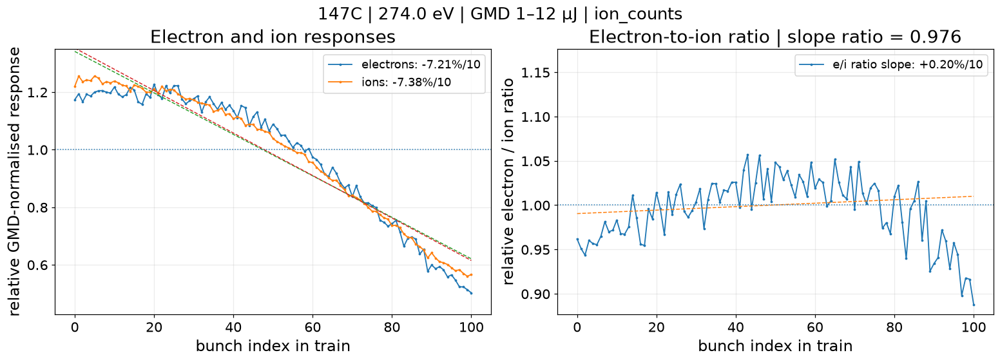

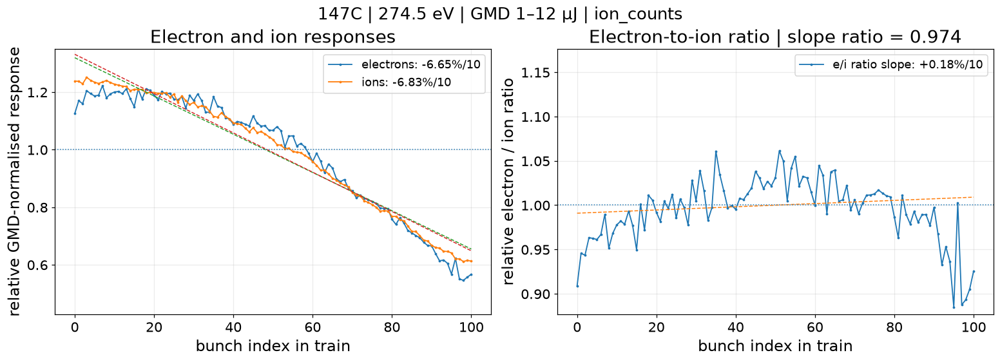

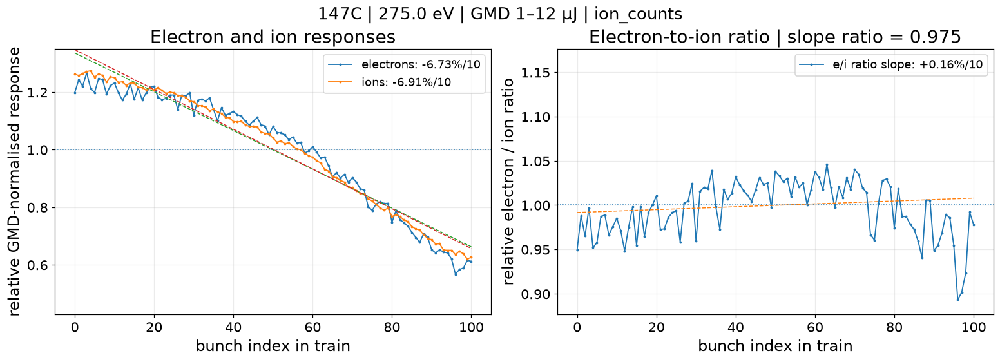

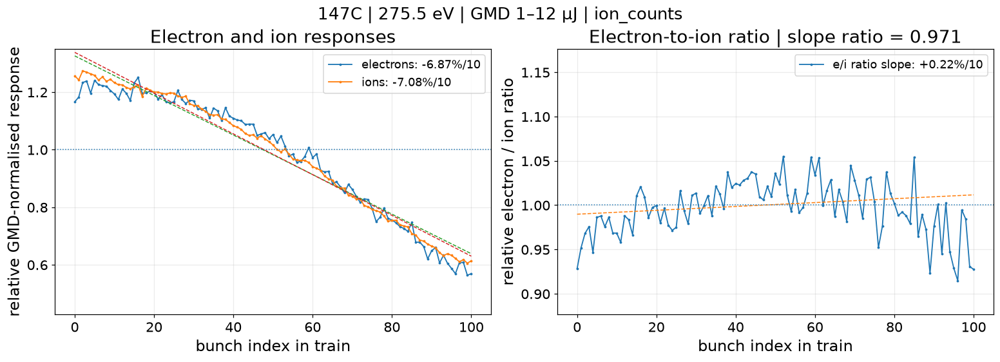

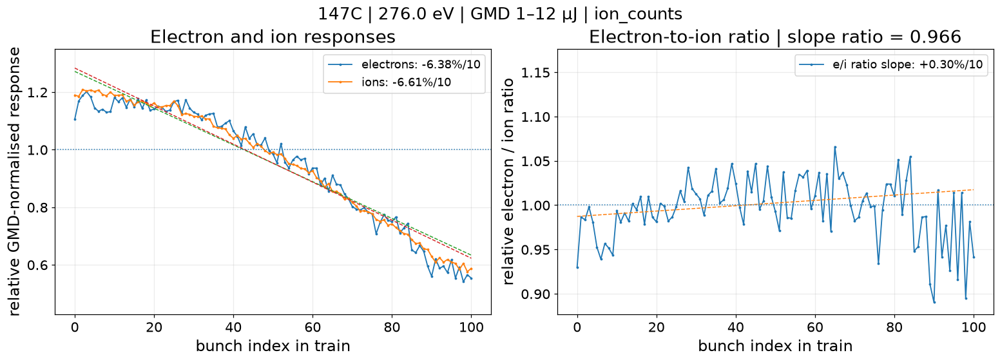

...

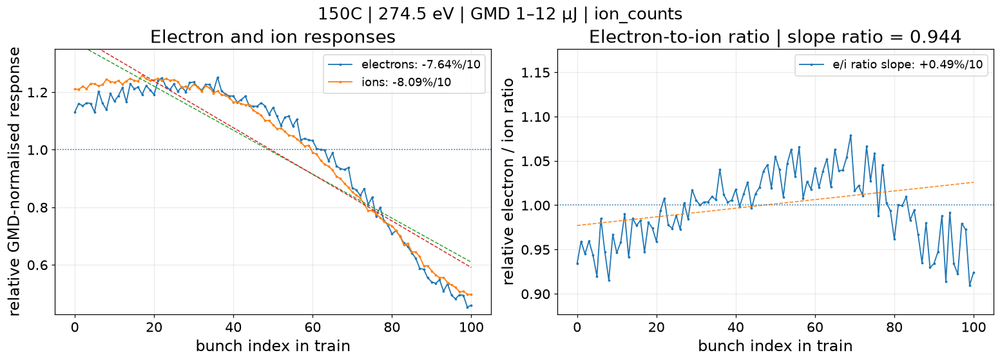

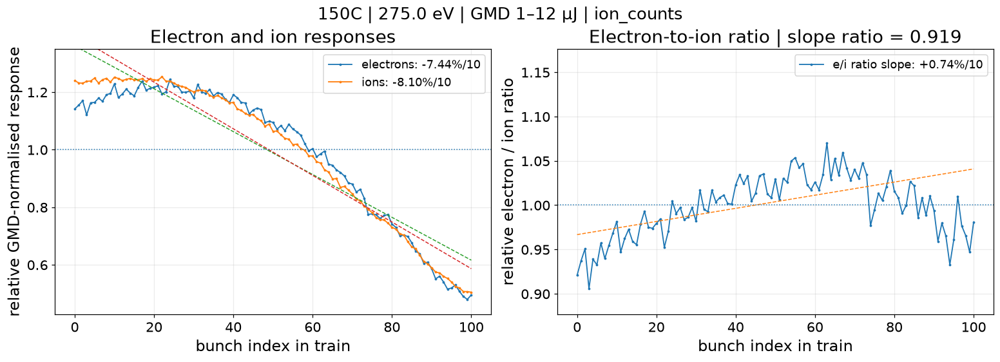

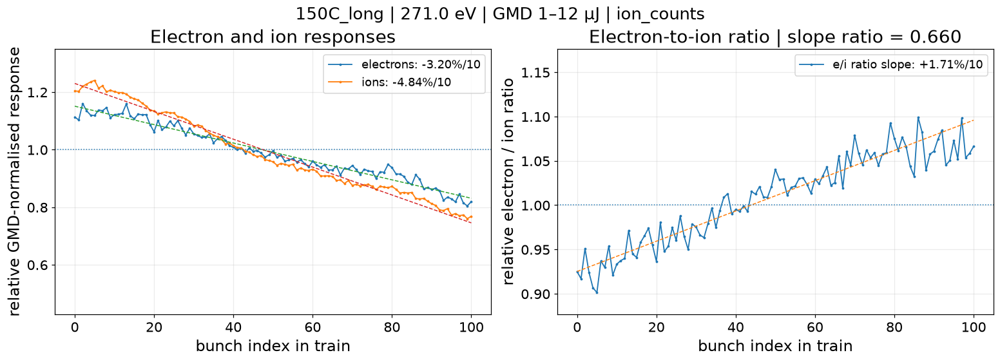

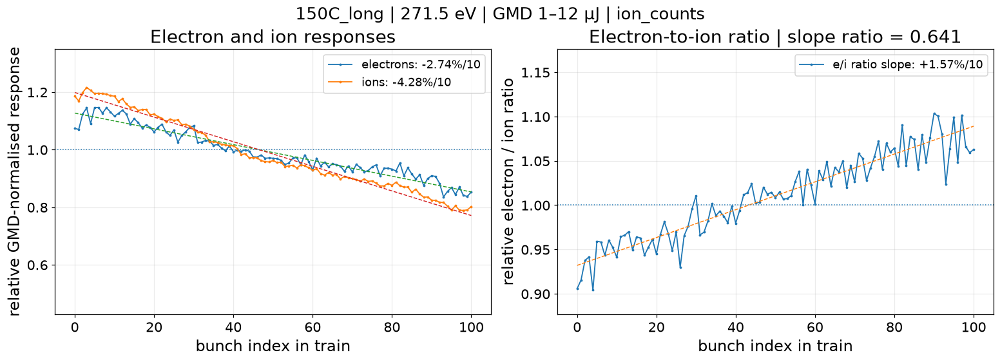

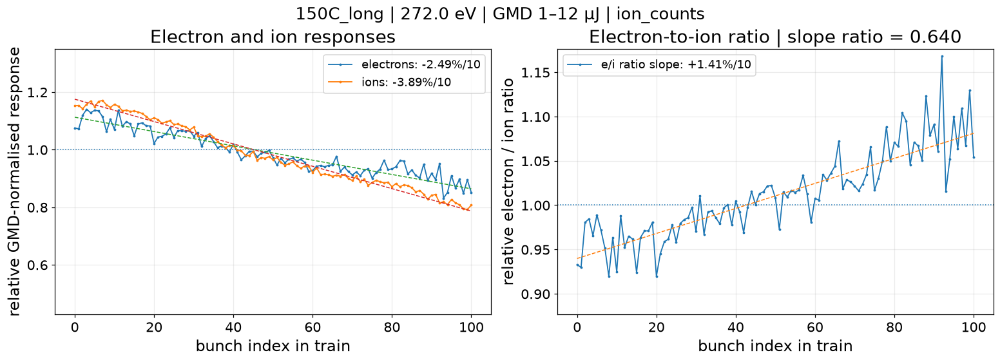

In [33]:
# --- Per-run electron/ion inspection plots for all incident energies ---
EI_INSPECT_RUNS = list(SELECT_RUNS)
EI_INSPECT_ION_KEY = "ion_counts"   # keep the inclusive ion selection
EI_INSPECT_GMD_RANGE = (1.0,12.0)
EI_INSPECT_BUNCH_START = 0
EI_INSPECT_MATCH_YLIMS = True

def ei_weighted_line(x,y,w):
    x0 = np.average(x,weights=w)
    y0 = np.average(y,weights=w)
    slope = np.sum(w*(x-x0)*(y-y0))/np.sum(w*(x-x0)**2)
    intercept = y0-slope*x0
    return slope,intercept

EI_INSPECT_RESULTS = []

for key in EI_INSPECT_RUNS:
    group,energy = key
    run = RUN_DATA[key]
    gmd_ei = run["gmd"]
    e_counts = run["ref_counts"]
    i_counts = run[EI_INSPECT_ION_KEY]
    daq_valid_ei = run["daq_valid_rows"]
    n_trains_ei,n_bunch_ei = gmd_ei.shape
    bunches_ei = np.arange(EI_INSPECT_BUNCH_START,n_bunch_ei)

    sum_g = np.zeros(n_bunch_ei)
    sum_e = np.zeros(n_bunch_ei)
    sum_i = np.zeros(n_bunch_ei)
    shots_ei = np.zeros(n_bunch_ei,dtype=int)

    for b in bunches_ei:
        sel = daq_valid_ei & np.isfinite(gmd_ei[:,b]) & (gmd_ei[:,b] >= EI_INSPECT_GMD_RANGE[0]) & (gmd_ei[:,b] < EI_INSPECT_GMD_RANGE[1])
        shots_ei[b] = sel.sum()
        sum_g[b] = gmd_ei[sel,b].sum()
        sum_e[b] = e_counts[sel,b].sum()
        sum_i[b] = i_counts[sel,b].sum()

    valid = (shots_ei[bunches_ei] > 0) & (sum_g[bunches_ei] > 0) & (sum_e[bunches_ei] > 0) & (sum_i[bunches_ei] > 0)
    if valid.sum() < 20:
        print(f"Skipping {group} {energy:.1f} eV: too few valid bunches.")
        continue

    b_fit = bunches_ei[valid].astype(float)
    n_fit = shots_ei[bunches_ei][valid]
    g_fit = sum_g[bunches_ei][valid]
    e_fit = sum_e[bunches_ei][valid]
    i_fit = sum_i[bunches_ei][valid]

    e_scale = e_fit.sum()/g_fit.sum()
    i_scale = i_fit.sum()/g_fit.sum()
    ratio_scale = e_fit.sum()/i_fit.sum()

    e_rel = np.full(n_bunch_ei,np.nan)
    i_rel = np.full(n_bunch_ei,np.nan)
    ratio_rel = np.full(n_bunch_ei,np.nan)
    e_err = np.full(n_bunch_ei,np.nan)
    i_err = np.full(n_bunch_ei,np.nan)
    ratio_err = np.full(n_bunch_ei,np.nan)

    good_g = sum_g > 0
    good_i = sum_i > 0
    good_ei = (sum_e > 0) & (sum_i > 0)

    e_rel[good_g] = (sum_e[good_g]/sum_g[good_g])/e_scale
    i_rel[good_g] = (sum_i[good_g]/sum_g[good_g])/i_scale
    ratio_rel[good_i] = np.divide(sum_e[good_i],sum_i[good_i],out=np.full(good_i.sum(),np.nan),where=sum_i[good_i] > 0)/ratio_scale

    e_err[good_g] = np.divide(np.sqrt(sum_e[good_g]),sum_g[good_g],out=np.full(good_g.sum(),np.nan),where=sum_g[good_g] > 0)/e_scale
    i_err[good_g] = np.divide(np.sqrt(sum_i[good_g]),sum_g[good_g],out=np.full(good_g.sum(),np.nan),where=sum_g[good_g] > 0)/i_scale
    ratio_err[good_ei] = ratio_rel[good_ei]*np.sqrt(1/sum_e[good_ei] + 1/sum_i[good_ei])

    e_slope_raw,e_int = ei_weighted_line(b_fit,e_rel[b_fit.astype(int)],n_fit)
    i_slope_raw,i_int = ei_weighted_line(b_fit,i_rel[b_fit.astype(int)],n_fit)

    ratio_w = np.divide(1,ratio_err[b_fit.astype(int)]**2,out=np.zeros_like(b_fit),where=np.isfinite(ratio_err[b_fit.astype(int)]) & (ratio_err[b_fit.astype(int)] > 0))
    ratio_slope_raw,ratio_int = ei_weighted_line(b_fit,ratio_rel[b_fit.astype(int)],ratio_w)

    slope_ratio = e_slope_raw/i_slope_raw if np.isfinite(i_slope_raw) and not np.isclose(i_slope_raw,0) else np.nan

    EI_INSPECT_RESULTS.append({
        "group":group,
        "energy":energy,
        "bunch":bunches_ei,
        "valid_bunches":b_fit.astype(int),
        "shots":shots_ei,
        "sum_g":sum_g,
        "sum_e":sum_e,
        "sum_i":sum_i,
        "e_rel":e_rel,
        "i_rel":i_rel,
        "ratio_rel":ratio_rel,
        "e_err":e_err,
        "i_err":i_err,
        "ratio_err":ratio_err,
        "e_slope":1000*e_slope_raw,
        "i_slope":1000*i_slope_raw,
        "ratio_slope":1000*ratio_slope_raw,
        "slope_ratio":slope_ratio,
        "e_int":e_int,
        "i_int":i_int,
        "ratio_int":ratio_int
    })

if len(EI_INSPECT_RESULTS) == 0:
    raise ValueError("No valid runs to plot.")

if EI_INSPECT_MATCH_YLIMS:
    all_resp = np.concatenate([
        np.r_[r["e_rel"][r["valid_bunches"]],r["i_rel"][r["valid_bunches"]]]
        for r in EI_INSPECT_RESULTS
    ])
    all_ratio = np.concatenate([
        r["ratio_rel"][r["valid_bunches"]]
        for r in EI_INSPECT_RESULTS
    ])
    resp_pad = 0.03*(np.nanmax(all_resp)-np.nanmin(all_resp))
    ratio_pad = 0.03*(np.nanmax(all_ratio)-np.nanmin(all_ratio))
    resp_ylim = (np.nanmin(all_resp)-resp_pad,np.nanmax(all_resp)+resp_pad)
    ratio_ylim = (np.nanmin(all_ratio)-ratio_pad,np.nanmax(all_ratio)+ratio_pad)
else:
    resp_ylim = None
    ratio_ylim = None

for r in sorted(EI_INSPECT_RESULTS,key=lambda d: (d["group"],d["energy"])):
    b = r["bunch"]
    vb = r["valid_bunches"]

    fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)

    axes[0].plot(vb,r["e_rel"][vb],".-",ms=3,lw=1.2,label=f"electrons: {r['e_slope']:+.2f}%/10")
    axes[0].plot(vb,r["i_rel"][vb],".-",ms=3,lw=1.2,label=f"ions: {r['i_slope']:+.2f}%/10")
    axes[0].plot([vb[0],vb[-1]],r["e_int"]+(r["e_slope"]/1000)*np.array([vb[0],vb[-1]]),"--",lw=1)
    axes[0].plot([vb[0],vb[-1]],r["i_int"]+(r["i_slope"]/1000)*np.array([vb[0],vb[-1]]),"--",lw=1)
    axes[0].axhline(1,ls=":",lw=1)
    axes[0].set(xlabel="bunch index in train",ylabel="relative GMD-normalised response",title="Electron and ion responses")
    axes[0].grid(alpha=0.25)
    axes[0].legend()

    axes[1].plot(vb,r["ratio_rel"][vb],".-",ms=3,lw=1.2,label=f"e/i ratio slope: {r['ratio_slope']:+.2f}%/10")
    axes[1].plot([vb[0],vb[-1]],r["ratio_int"]+(r["ratio_slope"]/1000)*np.array([vb[0],vb[-1]]),"--",lw=1)
    axes[1].axhline(1,ls=":",lw=1)
    axes[1].set(xlabel="bunch index in train",ylabel="relative electron / ion ratio",title=f"Electron-to-ion ratio | slope ratio = {r['slope_ratio']:.3f}")
    axes[1].grid(alpha=0.25)
    axes[1].legend()

    if resp_ylim is not None: axes[0].set_ylim(resp_ylim)
    if ratio_ylim is not None: axes[1].set_ylim(ratio_ylim)

    fig.suptitle(
        f"{r['group']} | {r['energy']:.1f} eV | "
        f"GMD {EI_INSPECT_GMD_RANGE[0]:g}–{EI_INSPECT_GMD_RANGE[1]:g} µJ | "
        f"{EI_INSPECT_ION_KEY}"
    )
    plt.show()

## DAQ-clean history response and matching
Use valid DAQ trains and previous-five-shot total-electron load; normalise reference counts by held-out bunch-specific GMD predictions.
Match zero versus nonzero history at fixed bunch, acquisition-row block and current GMD bin.
The dose-response, matched separation and block panel test history association and its acquisition stability.


In [8]:
# --- DAQ-clean bunch-specific GMD baseline and raw history dose-response ---

HISTORY_SHOTS = 5
H_total_clean = np.full_like(gmd,np.nan,dtype=float)
for b in range(HISTORY_SHOTS,n_bunch): H_total_clean[:,b] = data["total_electrons"][:,b-HISTORY_SHOTS:b].sum(axis=1)

ref_base_clean_cv = np.full_like(gmd,np.nan,dtype=float)
target_base_clean_cv = np.full_like(gmd,np.nan,dtype=float)

for off in INDEP_CV_OFFSETS:
    train_rows = daq_valid_rows & (train_ids % INDEP_CV_MOD != off)
    test_rows = daq_valid_rows & (train_ids % INDEP_CV_MOD == off)
    _,ref_beta = fit_bunch_baseline(gmd[train_rows],data["ref_counts"][train_rows],current_mask[train_rows])
    _,target_beta = fit_bunch_baseline(gmd[train_rows],data["target_counts"][train_rows],current_mask[train_rows])
    ref_base_clean_cv[test_rows] = apply_bunch_baseline(gmd[test_rows],ref_beta)
    target_base_clean_cv[test_rows] = apply_bunch_baseline(gmd[test_rows],target_beta)

HISTORY_BINS = [(0,0),(1,1),(2,2),(3,3),(4,4),(5,6),(7,9),(10,np.inf)]
HISTORY_LABELS = ["0","1","2","3","4","5–6","7–9","10+"]
response_clean,response_err_clean,n_shots_clean = [],[],[]
valid_clean = daq_valid_rows[:,None] & current_mask & np.isfinite(H_total_clean) & np.isfinite(ref_base_clean_cv) & (ref_base_clean_cv > 0)

for lo,hi in HISTORY_BINS:
    use = valid_clean & (H_total_clean >= lo) & (H_total_clean <= hi)
    obs = data["ref_counts"][use].sum()
    pred = ref_base_clean_cv[use].sum()
    response_clean.append(obs/pred if pred > 0 else np.nan)
    response_err_clean.append(np.sqrt(obs)/pred if obs > 0 and pred > 0 else np.nan)
    n_shots_clean.append(np.count_nonzero(use))

fig,ax = plt.subplots(figsize=(8,5))
x = np.arange(len(HISTORY_LABELS))
ax.errorbar(x,response_clean,yerr=response_err_clean,fmt="o-",capsize=3)
ax.axhline(1,ls=":",lw=1)
ax.set_xticks(x,HISTORY_LABELS)
ax.set(xlabel=f"total detected electrons in previous {HISTORY_SHOTS} shots",ylabel="current reference response / bunch-specific GMD prediction",title="DAQ-clean current response vs previous total electron load")
ax.grid(alpha=0.25)
plt.show()

for label,r,e,n in zip(HISTORY_LABELS,response_clean,response_err_clean,n_shots_clean): print(f"history {label:>3s}: response={r:.4f} ± {e:.4f}, shots={n:,}")

NameError: name 'np' is not defined

In [9]:
# --- DAQ-clean matched total-electron history ---

N_CLEAN_BLOCKS = 5
MATCH_GMD_STEP = 1.0
MIN_PER_GROUP = 5
clean_block_id = np.empty(n_trains,dtype=int)
for k,idx in enumerate(np.array_split(np.arange(n_trains),N_CLEAN_BLOCKS)): clean_block_id[idx] = k

gmd_edges_clean = np.arange(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1]+MATCH_GMD_STEP,MATCH_GMD_STEP)
bunches_clean_hist = np.arange(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch)

def matched_total_history_clean(blocks=None):
    if blocks is None: blocks = np.arange(N_CLEAN_BLOCKS)
    obs0 = np.zeros(n_bunch); pred0 = np.zeros(n_bunch); var0 = np.zeros(n_bunch)
    obs1 = np.zeros(n_bunch); pred1 = np.zeros(n_bunch); var1 = np.zeros(n_bunch); effective = np.zeros(n_bunch)
    for b in bunches_clean_hist:
        base_valid = daq_valid_rows & current_mask[:,b] & np.isfinite(H_total_clean[:,b]) & np.isfinite(ref_base_clean_cv[:,b]) & (ref_base_clean_cv[:,b] > 0)
        for block in blocks:
            for lo,hi in zip(gmd_edges_clean[:-1],gmd_edges_clean[1:]):
                use = base_valid & (clean_block_id == block) & (gmd[:,b] >= lo) & (gmd[:,b] < hi)
                idx0 = np.flatnonzero(use & (H_total_clean[:,b] == 0))
                idx1 = np.flatnonzero(use & (H_total_clean[:,b] >= 1))
                m = min(idx0.size,idx1.size)
                if m < MIN_PER_GROUP: continue
                w0,w1 = m/idx0.size,m/idx1.size
                y0 = data["ref_counts"][idx0,b].astype(float); y1 = data["ref_counts"][idx1,b].astype(float)
                obs0[b] += w0*y0.sum(); pred0[b] += w0*ref_base_clean_cv[idx0,b].sum(); var0[b] += w0**2*y0.sum()
                obs1[b] += w1*y1.sum(); pred1[b] += w1*ref_base_clean_cv[idx1,b].sum(); var1[b] += w1**2*y1.sum(); effective[b] += m
    R0 = np.divide(obs0,pred0,out=np.full(n_bunch,np.nan),where=pred0 > 0); R1 = np.divide(obs1,pred1,out=np.full(n_bunch,np.nan),where=pred1 > 0)
    E0 = np.divide(np.sqrt(var0),pred0,out=np.full(n_bunch,np.nan),where=pred0 > 0); E1 = np.divide(np.sqrt(var1),pred1,out=np.full(n_bunch,np.nan),where=pred1 > 0)
    pooled0 = obs0.sum()/pred0.sum(); pooled1 = obs1.sum()/pred1.sum()
    pooled_e0 = np.sqrt(var0.sum())/pred0.sum(); pooled_e1 = np.sqrt(var1.sum())/pred1.sum()
    return {"R0":R0,"R1":R1,"E0":E0,"E1":E1,"delta":R1-R0,"delta_err":np.sqrt(E0**2+E1**2),"effective":effective,"pooled0":pooled0,"pooled1":pooled1,"pooled_delta":pooled1-pooled0,"pooled_delta_err":np.sqrt(pooled_e0**2+pooled_e1**2)}

matched_clean = matched_total_history_clean()
block_delta_clean = [matched_total_history_clean([block])["pooled_delta"] for block in range(N_CLEAN_BLOCKS)]

fig,axes = plt.subplots(1,3,figsize=(19,5),constrained_layout=True)
axes[0].errorbar(bunches_clean_hist,matched_clean["R0"][bunches_clean_hist],yerr=matched_clean["E0"][bunches_clean_hist],fmt="o-",ms=3,lw=1,capsize=2,label=f"previous {HISTORY_SHOTS} shots: 0 electrons")
axes[0].errorbar(bunches_clean_hist,matched_clean["R1"][bunches_clean_hist],yerr=matched_clean["E1"][bunches_clean_hist],fmt="o-",ms=3,lw=1,capsize=2,label=f"previous {HISTORY_SHOTS} shots: ≥1 electron")
axes[0].axhline(1,ls=":",lw=1); axes[0].set(xlabel="current bunch index",ylabel="current reference response / bunch-specific GMD prediction",title="DAQ-clean matched total-electron history"); axes[0].grid(alpha=0.25); axes[0].legend(fontsize=9)
axes[1].errorbar(bunches_clean_hist,matched_clean["delta"][bunches_clean_hist],yerr=matched_clean["delta_err"][bunches_clean_hist],fmt="o-",ms=3,lw=1,capsize=2)
axes[1].axhline(0,ls=":",lw=1); axes[1].set(xlabel="current bunch index",ylabel=r"$\Delta R=R_{H\geq1}-R_{H=0}$",title="DAQ-clean history separation after matching"); axes[1].grid(alpha=0.25)
axes[2].plot(np.arange(1,N_CLEAN_BLOCKS+1),block_delta_clean,"o-")
axes[2].axhline(0,ls=":",lw=1); axes[2].set_xticks(np.arange(1,N_CLEAN_BLOCKS+1)); axes[2].set(xlabel="acquisition-row block",ylabel=r"pooled $\Delta R$",title="DAQ-clean history effect by acquisition block"); axes[2].grid(alpha=0.25)
plt.show()

print(f"Overall matched H=0 response:  {matched_clean['pooled0']:.4f}")
print(f"Overall matched H>=1 response: {matched_clean['pooled1']:.4f}")
print(f"Overall matched ΔR:            {matched_clean['pooled_delta']:+.4f} ± {matched_clean['pooled_delta_err']:.4f}")
print(f"Effective matched shots/group: {matched_clean['effective'].sum():,.0f}")
print("Block ΔR:",np.round(block_delta_clean,4))

NameError: name 'np' is not defined

## Nested CV and history-window selection
Use DAQ-valid shots on common bunch support, with acquisition blocks kept intact in outer and inner CV.
Select history parameters internally and compare held-out Poisson deviance for flat, exponential and active-shot histories.
The flat-window scan tests the preferred scale around L=5 using the original linear response and fold-to-fold SD.


In [ ]:
# --- Systematic DAQ-clean history definition and response-model comparison ---

from scipy.optimize import minimize_scalar

EXPLORE_MAX_LAG = 10
EXPLORE_N_BLOCKS = 5
explore_block_id = np.empty(n_trains,dtype=int)
for k,idx in enumerate(np.array_split(np.arange(n_trains),EXPLORE_N_BLOCKS)): explore_block_id[idx] = k

def flat_history(total,L):
    H = np.full(total.shape,np.nan,dtype=np.float32)
    for b in range(L,n_bunch): H[:,b] = total[:,b-L:b].sum(axis=1)
    return H

def exp_history(total,tau,max_lag=EXPLORE_MAX_LAG):
    H = np.full(total.shape,np.nan,dtype=np.float32)
    w = np.exp(-np.arange(max_lag,dtype=float)/tau)
    for b in range(max_lag,n_bunch): H[:,b] = (total[:,b-max_lag:b][:,::-1]*w[None,:]).sum(axis=1)
    return H

common_bunch_mask = np.zeros_like(current_mask,dtype=bool)
common_bunch_mask[:,max(INDEP_BUNCH_START,EXPLORE_MAX_LAG):] = True
explore_mask = current_mask & common_bunch_mask

ref_base_explore = np.full_like(gmd,np.nan,dtype=float)


In [ ]:
# --- Helpers for nested history-model comparison ---

def make_history(family,param):
    if family == "flat":
        return flat_history(TOTAL_E,int(param))
    if family == "exponential":
        return exp_history(TOTAL_E,float(param),max_lag=H_MAX_LAG)
    if family == "active":
        L = int(param)
        active = (TOTAL_E > 0).astype(np.float32)
        H = np.full(TOTAL_E.shape,np.nan,dtype=np.float32)
        cs = np.concatenate((np.zeros((n_trains,1),dtype=np.float32),np.cumsum(active,axis=1,dtype=np.float32)),axis=1)
        H[:,L:] = cs[:,L:n_bunch]-cs[:,:n_bunch-L]
        return H
    raise ValueError(f"Unknown history family: {family}")

def history_factor(H,beta,model):
    if model in ("linear","linear multiplier"):
        return 1+beta*H
    if model in ("exponential","exponential multiplier"):
        return np.exp(np.clip(beta*H,-50,50))
    if model in ("power","power multiplier"):
        return np.exp(np.clip(beta*np.log1p(H),-50,50))
    raise ValueError(model)

def fit_history_factor_fast(y,mu,H,model):
    y = np.asarray(y,dtype=float)
    mu = np.asarray(mu,dtype=float)
    H = np.asarray(H,dtype=float)
    ysum = y.sum()

    if model in ("linear","linear multiplier"):
        hmax = np.nanmax(H)
        bounds = (-0.999/hmax if hmax > 0 else -1,1)
    else:
        bounds = (-1,1)

    def objective(beta):
        f = history_factor(H,beta,model)
        if np.any(~np.isfinite(f)) or np.any(f <= 0):
            return np.inf
        den = np.sum(mu*f)
        if den <= 0:
            return np.inf
        A = ysum/den
        return A*den-ysum*np.log(A)-np.sum(y*np.log(f))

    result = minimize_scalar(objective,bounds=bounds,method="bounded",options={"xatol":1e-6})
    beta = result.x
    f = history_factor(H,beta,model)
    A = ysum/np.sum(mu*f)
    return A,beta

In [ ]:
# --- Nested CV: select H timescale internally, then compare all 9 H x S(H) models ---

NESTED_H_FAMILIES = {"flat":[1,2,3,5,10],"exponential":[1,2,3,5],"active":[1,2,3,5,10]}
# NESTED_H_FAMILIES = {
#     "flat":[1,2,3,4,5,6,7,8,10],
#     "exponential":[1,2,3,4,5,6,7],
#     "active":[1,2,3,4,5,6,7,8,10]
# }
NESTED_S_MODELS = ["linear","exponential","power"]
NESTED_SELECT_MODEL = "linear"
H_MAX_LAG = 10
TOTAL_E = data["total_electrons"].astype(np.float32)

nested_selection_rows = []
nested_fold_rows = []
nested_totals = {(family,model):{"ref_d0":0.0,"ref_d1":0.0,"target_d0":0.0,"target_d1":0.0} for family in NESTED_H_FAMILIES for model in NESTED_S_MODELS}

for outer_block in range(EXPLORE_N_BLOCKS):
    outer_train_rows = daq_valid_rows & (explore_block_id != outer_block)
    outer_test_rows = daq_valid_rows & (explore_block_id == outer_block)

    inner_cache = []
    for inner_block in range(EXPLORE_N_BLOCKS):
        if inner_block == outer_block: continue
        inner_train_rows = daq_valid_rows & (explore_block_id != outer_block) & (explore_block_id != inner_block)
        inner_val_rows = daq_valid_rows & (explore_block_id == inner_block)
        ref_base_inner_train,ref_beta_inner = fit_bunch_baseline(gmd[inner_train_rows],data["ref_counts"][inner_train_rows],explore_mask[inner_train_rows])
        ref_base_inner_val = apply_bunch_baseline(gmd[inner_val_rows],ref_beta_inner)
        inner_cache.append((inner_block,inner_train_rows,inner_val_rows,ref_base_inner_train.astype(np.float32),ref_base_inner_val.astype(np.float32)))

    selected_params = {}
    for family,params in NESTED_H_FAMILIES.items():
        family_scores = []
        for param in params:
            H = make_history(family,param)
            d0_total = d1_total = 0.0
            for inner_block,inner_train_rows,inner_val_rows,mu_train,mu_val in inner_cache:
                H_train = H[inner_train_rows]; H_val = H[inner_val_rows]
                train_mask = explore_mask[inner_train_rows] & np.isfinite(H_train) & np.isfinite(mu_train) & (mu_train > 0)
                val_mask = explore_mask[inner_val_rows] & np.isfinite(H_val) & np.isfinite(mu_val) & (mu_val > 0)
                y_train = data["ref_counts"][inner_train_rows][train_mask].astype(float)
                mu_train_use = mu_train[train_mask].astype(float)
                h_train = H_train[train_mask].astype(float)
                A0 = y_train.sum()/mu_train_use.sum()
                A,beta = fit_history_factor_fast(y_train,mu_train_use,h_train,NESTED_SELECT_MODEL)
                y_val = data["ref_counts"][inner_val_rows][val_mask].astype(float)
                mu0 = mu_val[val_mask].astype(float)*A0
                mu1 = mu_val[val_mask].astype(float)*A*history_factor(H_val[val_mask],beta,NESTED_SELECT_MODEL)
                d0_total += poisson_deviance(y_val,mu0)
                d1_total += poisson_deviance(y_val,mu1)
            improvement = 100*(1-d1_total/d0_total)
            family_scores.append((param,improvement))
            del H
        best_param,best_score = max(family_scores,key=lambda x:x[1])
        selected_params[family] = best_param
        nested_selection_rows.append({"outer block":outer_block+1,"H family":family,"selected parameter":best_param,"inner-CV improvement (%)":best_score})

    ref_base_outer_train,ref_beta_outer = fit_bunch_baseline(gmd[outer_train_rows],data["ref_counts"][outer_train_rows],explore_mask[outer_train_rows])
    ref_base_outer_test = apply_bunch_baseline(gmd[outer_test_rows],ref_beta_outer)
    target_base_outer_train,target_beta_outer = fit_bunch_baseline(gmd[outer_train_rows],data["target_counts"][outer_train_rows],explore_mask[outer_train_rows])
    target_base_outer_test = apply_bunch_baseline(gmd[outer_test_rows],target_beta_outer)

    for family,param in selected_params.items():
        H = make_history(family,param)
        H_train = H[outer_train_rows]; H_test = H[outer_test_rows]
        train_mask = explore_mask[outer_train_rows] & np.isfinite(H_train) & np.isfinite(ref_base_outer_train) & (ref_base_outer_train > 0)
        ref_test_mask = explore_mask[outer_test_rows] & np.isfinite(H_test) & np.isfinite(ref_base_outer_test) & (ref_base_outer_test > 0)
        target_test_mask = explore_mask[outer_test_rows] & np.isfinite(H_test) & np.isfinite(target_base_outer_test) & (target_base_outer_test > 0)
        y_train = data["ref_counts"][outer_train_rows][train_mask].astype(float)
        mu_train = ref_base_outer_train[train_mask].astype(float)
        h_train = H_train[train_mask].astype(float)
        A0 = y_train.sum()/mu_train.sum()

        for model in NESTED_S_MODELS:
            A,beta = fit_history_factor_fast(y_train,mu_train,h_train,model)
            y_ref = data["ref_counts"][outer_test_rows][ref_test_mask].astype(float)
            ref_mu0 = ref_base_outer_test[ref_test_mask].astype(float)*A0
            ref_mu1 = ref_base_outer_test[ref_test_mask].astype(float)*A*history_factor(H_test[ref_test_mask],beta,model)
            y_target = data["target_counts"][outer_test_rows][target_test_mask].astype(float)
            target_mu0 = target_base_outer_test[target_test_mask].astype(float)*A0
            target_mu1 = target_base_outer_test[target_test_mask].astype(float)*A*history_factor(H_test[target_test_mask],beta,model)
            ref_d0 = poisson_deviance(y_ref,ref_mu0); ref_d1 = poisson_deviance(y_ref,ref_mu1)
            target_d0 = poisson_deviance(y_target,target_mu0); target_d1 = poisson_deviance(y_target,target_mu1)
            nested_totals[(family,model)]["ref_d0"] += ref_d0
            nested_totals[(family,model)]["ref_d1"] += ref_d1
            nested_totals[(family,model)]["target_d0"] += target_d0
            nested_totals[(family,model)]["target_d1"] += target_d1
            nested_fold_rows.append({"outer block":outer_block+1,"H family":family,"selected parameter":param,"S(H)":model,"beta":beta,"reference improvement (%)":100*(1-ref_d1/ref_d0),"target improvement (%)":100*(1-target_d1/target_d0)})
        del H

    del inner_cache,ref_base_outer_train,ref_base_outer_test,target_base_outer_train,target_base_outer_test

nested_selection_table = pd.DataFrame(nested_selection_rows)
nested_fold_table = pd.DataFrame(nested_fold_rows)

summary_rows = []
for family in NESTED_H_FAMILIES:
    params = nested_selection_table[nested_selection_table["H family"] == family]["selected parameter"].tolist()
    for model in NESTED_S_MODELS:
        t = nested_totals[(family,model)]
        sub = nested_fold_table[(nested_fold_table["H family"] == family) & (nested_fold_table["S(H)"] == model)]
        summary_rows.append({"H family":family,"S(H)":model,"selected parameters":", ".join(f"{p:g}" for p in params),"reference improvement (%)":100*(1-t["ref_d1"]/t["ref_d0"]),"target improvement (%)":100*(1-t["target_d1"]/t["target_d0"]),"beta mean":sub["beta"].mean(),"beta std":sub["beta"].std(ddof=1)})

nested_summary_table = pd.DataFrame(summary_rows)
print("H parameter selected independently inside each outer fold:")
display(nested_selection_table.pivot(index="outer block",columns="H family",values="selected parameter"))
print("Final outer-held-out performance:")
display(nested_summary_table.sort_values("reference improvement (%)",ascending=False).round(6))



H parameter selected independently inside each outer fold:


H family,active,exponential,flat
outer block,,,
1,10,5,10
2,10,5,10
3,10,5,10
4,10,5,10
5,10,5,10


Final outer-held-out performance:


,H family,S(H),selected parameters,reference improvement (%),target improvement (%),beta mean,beta std
0,flat,linear,"10, 10, 10, 10, 10",0.067224,0.099260,0.018423,0.001677
1,flat,exponential,"10, 10, 10, 10, 10",0.065585,0.098265,0.015796,0.001270
2,flat,power,"10, 10, 10, 10, 10",0.062715,0.090525,0.097671,0.008156
5,exponential,power,"5, 5, 5, 5, 5",0.053136,0.079720,0.103296,0.008426
3,exponential,linear,"5, 5, 5, 5, 5",0.052635,0.080621,0.030457,0.002781
6,active,linear,"10, 10, 10, 10, 10",0.051225,0.078069,0.033981,0.003654
4,exponential,exponential,"5, 5, 5, 5, 5",0.051024,0.079321,0.026462,0.002179
7,active,exponential,"10, 10, 10, 10, 10",0.050911,0.078191,0.029884,0.002830
8,active,power,"10, 10, 10, 10, 10",0.048167,0.072090,0.116352,0.011859


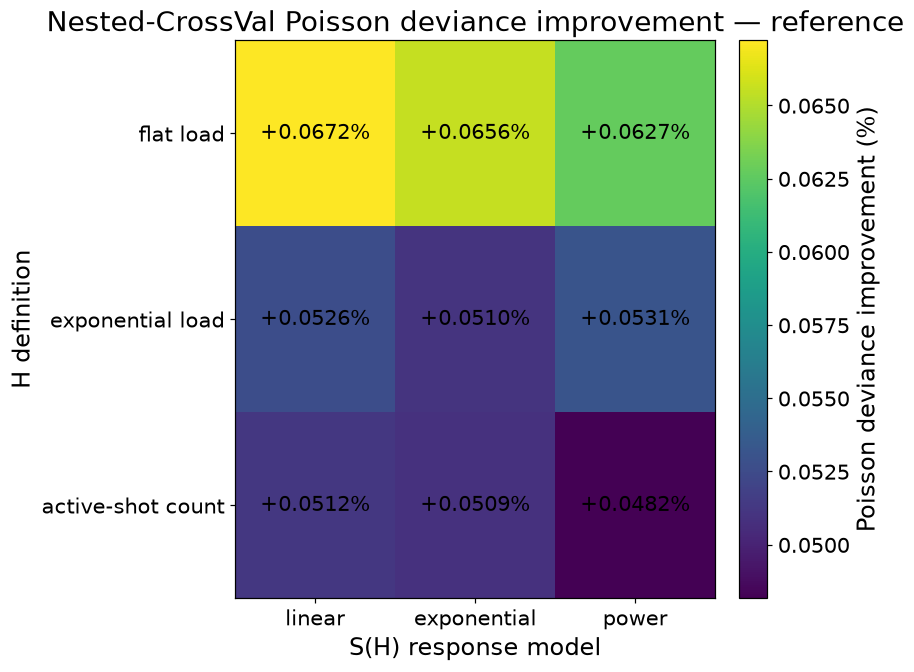

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Use the computed nested-CV table for the selected photon-energy dataset.
# Reconstruct reference matrix for the heatmap
NESTED_S_MODELS = ["linear", "exponential", "power"]
ref_matrix = nested_summary_table.pivot(
    index="H family", columns="S(H)", values="reference improvement (%)"
).reindex(index=["flat", "exponential", "active"], columns=NESTED_S_MODELS)

# Plot left panel
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
im = ax.imshow(ref_matrix.values, aspect="auto")

ax.set_xticks(np.arange(len(NESTED_S_MODELS)), NESTED_S_MODELS)
ax.set_yticks(np.arange(3), ["flat load", "exponential load", "active-shot count"])
ax.set(
    xlabel="S(H) response model",
    ylabel="H definition",
    title="Nested-CrossVal Poisson deviance improvement — reference",
)

for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{ref_matrix.iloc[i, j]:+.4f}%", ha="center", va="center")

fig.colorbar(im, ax=ax, label="Poisson deviance improvement (%)")
plt.show()

In [ ]:
# --- Nested-CV history-timescale scan with fold-to-fold uncertainty ---

H_SCAN_FAMILIES = {
    "flat":[1,2,3,4,5,6,7,8,10],
    "exponential":[1,2,3,4,5,6,7],
    "active":[1,2,3,4,5,6,7,8,10]
}
H_SCAN_MODEL = "linear"

h_scan_rows = []

for outer_block in range(EXPLORE_N_BLOCKS):
    for family,params in H_SCAN_FAMILIES.items():
        for param in params:
            H = make_history(family,param)
            d0_total = d1_total = 0.0

            for inner_block in range(EXPLORE_N_BLOCKS):
                if inner_block == outer_block: continue

                inner_train_rows = daq_valid_rows & (explore_block_id != outer_block) & (explore_block_id != inner_block)
                inner_val_rows = daq_valid_rows & (explore_block_id == inner_block)

                base_train,beta_base = fit_bunch_baseline(
                    gmd[inner_train_rows],
                    data["ref_counts"][inner_train_rows],
                    explore_mask[inner_train_rows]
                )
                base_val = apply_bunch_baseline(gmd[inner_val_rows],beta_base)

                H_train = H[inner_train_rows]
                H_val = H[inner_val_rows]

                train_mask = explore_mask[inner_train_rows] & np.isfinite(H_train) & np.isfinite(base_train) & (base_train > 0)
                val_mask = explore_mask[inner_val_rows] & np.isfinite(H_val) & np.isfinite(base_val) & (base_val > 0)

                y_train = data["ref_counts"][inner_train_rows][train_mask].astype(float)
                mu_train = base_train[train_mask].astype(float)
                h_train = H_train[train_mask].astype(float)

                A0 = y_train.sum()/mu_train.sum()
                A,beta = fit_history_factor_fast(y_train,mu_train,h_train,H_SCAN_MODEL)

                y_val = data["ref_counts"][inner_val_rows][val_mask].astype(float)
                mu0 = base_val[val_mask].astype(float)*A0
                mu1 = base_val[val_mask].astype(float)*A*history_factor(H_val[val_mask],beta,H_SCAN_MODEL)

                d0_total += poisson_deviance(y_val,mu0)
                d1_total += poisson_deviance(y_val,mu1)

            h_scan_rows.append({
                "outer block":outer_block+1,
                "H family":family,
                "parameter":param,
                "improvement (%)":100*(1-d1_total/d0_total)
            })

            del H

h_scan_table = pd.DataFrame(h_scan_rows)



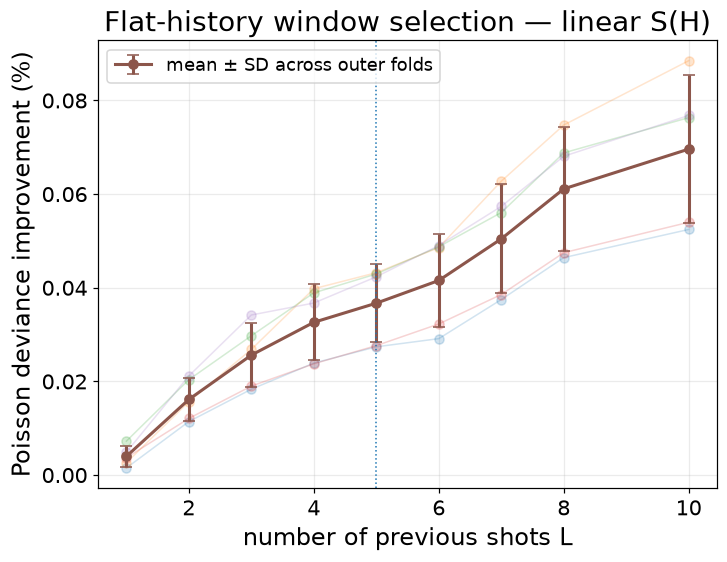

In [ ]:
# --- Condensed meeting figure: flat-history window selection ---

fig, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)

# Flat-history L selection
sub = h_scan_table[h_scan_table["H family"] == "flat"]
params = np.array(sorted(sub["parameter"].unique()), dtype=float)

for outer_block in range(1, EXPLORE_N_BLOCKS + 1):
    fold = sub[sub["outer block"] == outer_block].set_index("parameter").loc[params]
    ax.plot(params, fold["improvement (%)"].to_numpy(), "-o", alpha=0.20, lw=1)

grouped = sub.groupby("parameter")["improvement (%)"]
mean = grouped.mean().reindex(params).to_numpy()
std = grouped.std(ddof=1).reindex(params).to_numpy()

ax.errorbar(params, mean, yerr=std, fmt="o-", capsize=4, lw=2, label="mean ± SD across outer folds")
ax.axvline(5, ls=":", lw=1)
ax.set(
    xlabel="number of previous shots L",
    # ylabel="inner-CV Poisson deviance improvement (%)",
    ylabel="Poisson deviance improvement (%)",
    title="Flat-history window selection — linear S(H)"
)
ax.grid(alpha=0.25)
ax.legend()

plt.show()

## Held-out history models and bunch correction
Use DAQ-valid flat-L=5 shots and train on all acquisition blocks except the held-out block.
Compare linear, exponential and power response corrections with whole-train bootstrap intervals.
Apply the original power-history factor to independent target/GMD bunch profiles to test whether history explains their slope.


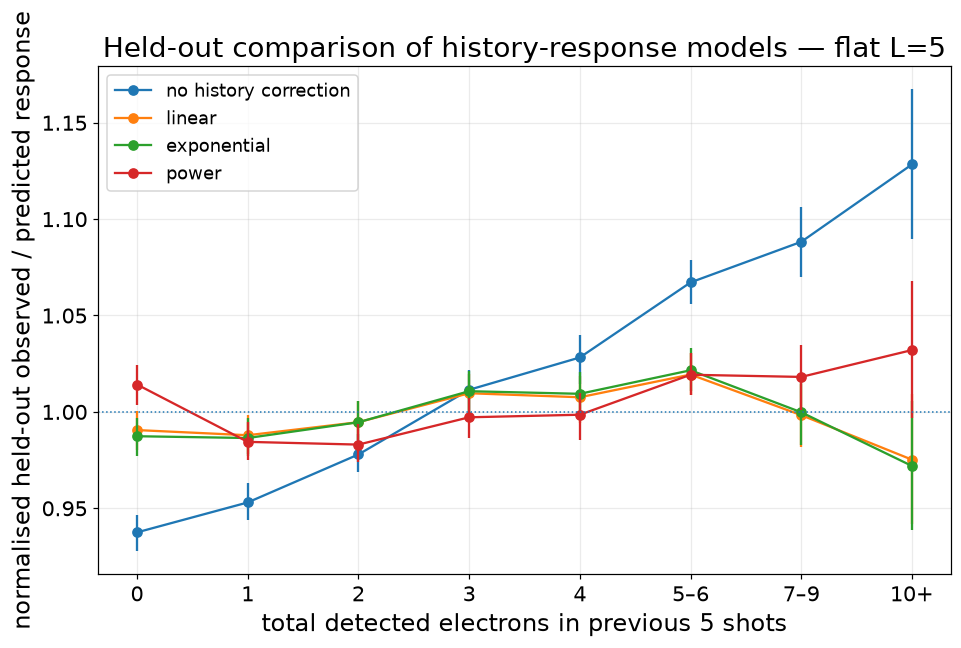

In [ ]:
# --- Held-out model comparison with whole-train bootstrap error bars: flat L=5 ---

COMPARE_H = make_history("flat",5)
COMPARE_MODELS = ["linear","exponential","power"]
COMPARE_BINS = [(0,0,"0"),(1,1,"1"),(2,2,"2"),(3,3,"3"),(4,4,"4"),(5,6,"5–6"),(7,9,"7–9"),(10,np.inf,"10+")]
COMPARE_BOOT_N = 500
COMPARE_BOOT_BATCH = 25
COMPARE_BOOT_SEED = 12345

compare_base = np.full_like(ref_base_explore,np.nan,dtype=float)
compare_pred = {model:np.full_like(ref_base_explore,np.nan,dtype=float) for model in COMPARE_MODELS}

for outer_block in range(EXPLORE_N_BLOCKS):
    train_rows = daq_valid_rows & (explore_block_id != outer_block)
    test_rows = daq_valid_rows & (explore_block_id == outer_block)
    ref_base_train,ref_beta = fit_bunch_baseline(gmd[train_rows],data["ref_counts"][train_rows],explore_mask[train_rows])
    ref_base_test = apply_bunch_baseline(gmd[test_rows],ref_beta)
    H_train = COMPARE_H[train_rows]; H_test = COMPARE_H[test_rows]
    train_mask = explore_mask[train_rows] & np.isfinite(H_train) & np.isfinite(ref_base_train) & (ref_base_train > 0)
    test_mask = explore_mask[test_rows] & np.isfinite(H_test) & np.isfinite(ref_base_test) & (ref_base_test > 0)
    y_train = data["ref_counts"][train_rows][train_mask].astype(float)
    mu_train = ref_base_train[train_mask].astype(float)
    h_train = H_train[train_mask].astype(float)
    A0 = y_train.sum()/mu_train.sum()
    tmp0 = np.full_like(ref_base_test,np.nan,dtype=float)
    tmp0[test_mask] = ref_base_test[test_mask]*A0
    compare_base[test_rows] = tmp0
    for model in COMPARE_MODELS:
        A,beta = fit_history_factor_fast(y_train,mu_train,h_train,model)
        tmp = np.full_like(ref_base_test,np.nan,dtype=float)
        tmp[test_mask] = ref_base_test[test_mask]*A*history_factor(H_test[test_mask],beta,model)
        compare_pred[model][test_rows] = tmp

valid = daq_valid_rows[:,None] & explore_mask & np.isfinite(COMPARE_H) & np.isfinite(compare_base) & (compare_base > 0)
for model in COMPARE_MODELS: valid &= np.isfinite(compare_pred[model]) & (compare_pred[model] > 0)

n_bins = len(COMPARE_BINS)
labels = [x[2] for x in COMPARE_BINS]
obs_tr = np.zeros((n_trains,n_bins),dtype=float)
base_tr = np.zeros((n_trains,n_bins),dtype=float)
hnum_tr = np.zeros((n_trains,n_bins),dtype=float)
model_tr = {model:np.zeros((n_trains,n_bins),dtype=float) for model in COMPARE_MODELS}

for k,(lo,hi,label) in enumerate(COMPARE_BINS):
    use = valid & (COMPARE_H >= lo) & (COMPARE_H <= hi if np.isfinite(hi) else COMPARE_H >= lo)
    obs_tr[:,k] = np.sum(np.where(use,data["ref_counts"],0),axis=1)
    base_tr[:,k] = np.sum(np.where(use,compare_base,0),axis=1)
    hnum_tr[:,k] = np.sum(np.where(use,compare_base*COMPARE_H,0),axis=1)
    for model in COMPARE_MODELS: model_tr[model][:,k] = np.sum(np.where(use,compare_pred[model],0),axis=1)

keep = base_tr.sum(axis=1) > 0
obs_tr = obs_tr[keep]; base_tr = base_tr[keep]; hnum_tr = hnum_tr[keep]
for model in COMPARE_MODELS: model_tr[model] = model_tr[model][keep]

def normalised_response(obs,pred):
    r = np.divide(obs,pred,out=np.full_like(obs,np.nan,dtype=float),where=pred > 0)
    pooled = obs.sum()/pred.sum()
    return r/pooled

obs_sum = obs_tr.sum(axis=0)
base_sum = base_tr.sum(axis=0)
compare_x = np.divide(hnum_tr.sum(axis=0),base_sum,out=np.full(n_bins,np.nan),where=base_sum > 0)
compare_response = {"baseline":normalised_response(obs_sum,base_sum)}
for model in COMPARE_MODELS: compare_response[model] = normalised_response(obs_sum,model_tr[model].sum(axis=0))

rng = np.random.default_rng(COMPARE_BOOT_SEED)
boot_curves = {name:np.empty((COMPARE_BOOT_N,n_bins),dtype=float) for name in ["baseline"]+COMPARE_MODELS}
boot_x = np.empty((COMPARE_BOOT_N,n_bins),dtype=float)
boot_weights = np.empty((COMPARE_BOOT_N,n_bins),dtype=float)

n_keep = obs_tr.shape[0]
prob = np.full(n_keep,1/n_keep)
done = 0

while done < COMPARE_BOOT_N:
    m = min(COMPARE_BOOT_BATCH,COMPARE_BOOT_N-done)
    counts = rng.multinomial(n_keep,prob,size=m)
    obs_b = counts@obs_tr
    base_b = counts@base_tr
    hnum_b = counts@hnum_tr
    boot_x[done:done+m] = np.divide(hnum_b,base_b,out=np.full_like(hnum_b,np.nan),where=base_b > 0)
    boot_weights[done:done+m] = base_b

    pooled = obs_b.sum(axis=1)/base_b.sum(axis=1)
    boot_curves["baseline"][done:done+m] = np.divide(obs_b,base_b,out=np.full_like(obs_b,np.nan),where=base_b > 0)/pooled[:,None]

    for model in COMPARE_MODELS:
        pred_b = counts@model_tr[model]
        pooled = obs_b.sum(axis=1)/pred_b.sum(axis=1)
        boot_curves[model][done:done+m] = np.divide(obs_b,pred_b,out=np.full_like(obs_b,np.nan),where=pred_b > 0)/pooled[:,None]

    done += m

fig,ax = plt.subplots(figsize=(10,6))

for name,label in [("baseline","no history correction"),("linear","linear"),("exponential","exponential"),("power","power")]:
    y = compare_response[name]
    low = np.nanpercentile(boot_curves[name],16,axis=0)
    high = np.nanpercentile(boot_curves[name],84,axis=0)
    line, = ax.plot(np.arange(n_bins),y,"o-",label=label)
    ax.vlines(np.arange(n_bins),low,high,color=line.get_color(),lw=1.5)

ax.axhline(1,ls=":",lw=1)
ax.set_xticks(np.arange(n_bins),labels)
ax.set(xlabel="total detected electrons in previous 5 shots",ylabel="normalised held-out observed / predicted response",title="Held-out comparison of history-response models — flat L=5")
ax.grid(alpha=0.25); ax.legend()
plt.show()

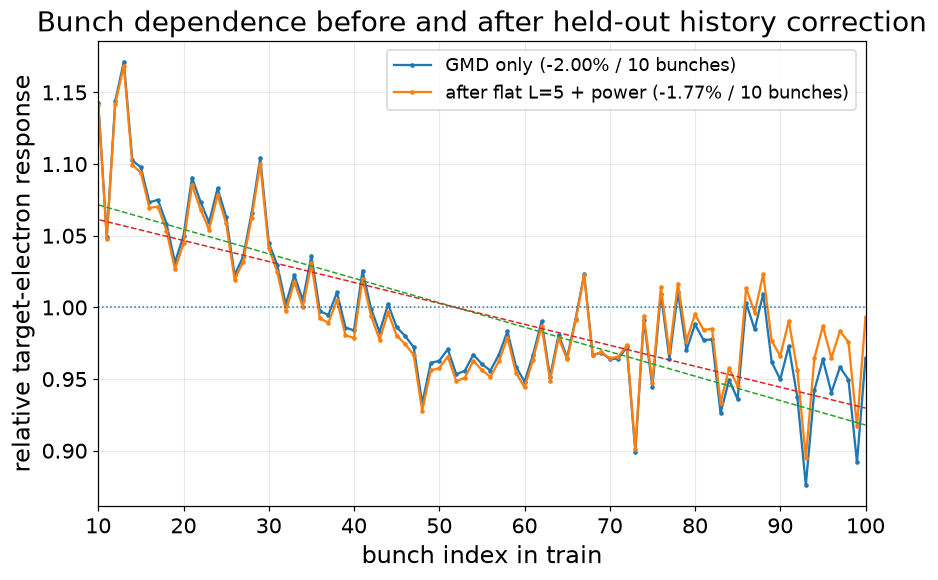

GMD only:                       -2.002% / 10 bunches
After flat L=5 + power      : -1.772% / 10 bunches
Slope change:                   +0.229% / 10 bunches
Reduction in |slope|:           11.46%


In [ ]:
# --- Does the held-out flat-L=5 history correction explain the bunch-position slope? ---

HISTORY_S_MODEL = "power"  # "linear", "exponential", or "power"
HISTORY_H = make_history("flat",5)

history_factor_cv = np.full_like(gmd,np.nan,dtype=float)
history_beta_cv = []

for outer_block in range(EXPLORE_N_BLOCKS):
    train_rows = daq_valid_rows & (explore_block_id != outer_block)
    test_rows = daq_valid_rows & (explore_block_id == outer_block)

    ref_base_train,ref_beta = fit_bunch_baseline(gmd[train_rows],data["ref_counts"][train_rows],explore_mask[train_rows])
    H_train = HISTORY_H[train_rows]
    train_mask = explore_mask[train_rows] & np.isfinite(H_train) & np.isfinite(ref_base_train) & (ref_base_train > 0)

    y_train = data["ref_counts"][train_rows][train_mask].astype(float)
    mu_train = ref_base_train[train_mask].astype(float)
    h_train = H_train[train_mask].astype(float)

    A,beta = fit_history_factor_fast(y_train,mu_train,h_train,HISTORY_S_MODEL)
    history_beta_cv.append(beta)

    H_test = HISTORY_H[test_rows]
    valid_test = explore_mask[test_rows] & np.isfinite(H_test)
    tmp = np.full(H_test.shape,np.nan,dtype=float)
    tmp[valid_test] = A*history_factor(H_test[valid_test],beta,HISTORY_S_MODEL)
    history_factor_cv[test_rows] = tmp

selected = daq_valid_rows[:,None] & explore_mask & np.isfinite(HISTORY_H) & np.isfinite(history_factor_cv) & (history_factor_cv > 0)

obs = band_sums(data["target_counts"].astype(float),gmd,selected)
shots = band_sums(np.ones_like(gmd),gmd,selected)
norm_gmd = band_sums(gmd,gmd,selected)
norm_history = band_sums(gmd*history_factor_cv,gmd,selected)

m_before = bunch_metrics(obs,norm_gmd,shots)
m_after = bunch_metrics(obs,norm_history,shots)

profile_before = combined_relative_profile(m_before,shots)
profile_after = combined_relative_profile(m_after,shots)
profile_weights = shots.sum(axis=0)

line_before = weighted_bunch_line(profile_before,profile_weights,INDEP_BUNCH_START)
line_after = weighted_bunch_line(profile_after,profile_weights,INDEP_BUNCH_START)

b = np.arange(n_bunch)
fig,ax = plt.subplots(figsize=(9,5.5))
ax.plot(b,profile_before,".-",ms=4,lw=1.5,label=f"GMD only ({m_before['slope']:+.2f}% / 10 bunches)")
ax.plot(b,profile_after,".-",ms=4,lw=1.5,label=f"after flat L=5 + {HISTORY_S_MODEL} ({m_after['slope']:+.2f}% / 10 bunches)")
ax.plot(b,line_before[0]*b+line_before[1],"--",lw=1)
ax.plot(b,line_after[0]*b+line_after[1],"--",lw=1)
ax.axhline(1,ls=":",lw=1)
ax.set_xlim(INDEP_BUNCH_START,n_bunch-1)
ax.set(xlabel="bunch index in train",ylabel="relative target-electron response",title="Bunch dependence before and after held-out history correction")
ax.grid(alpha=0.25); ax.legend()
plt.show()

slope_change = m_after["slope"]-m_before["slope"]
slope_reduction = 100*(1-abs(m_after["slope"])/abs(m_before["slope"]))
print(f"GMD only:                       {m_before['slope']:+.3f}% / 10 bunches")
print(f"After flat L=5 + {HISTORY_S_MODEL:11s}: {m_after['slope']:+.3f}% / 10 bunches")
print(f"Slope change:                   {slope_change:+.3f}% / 10 bunches")
print(f"Reduction in |slope|:           {slope_reduction:.2f}%")

## Electron and ion bunch corrections
Load ion hits in train chunks; compare total-electron and total-ion GMD-normalised profiles on DAQ-valid shots.
Learn ion-derived and reference-electron-derived bunch factors on training trains and apply them to held-out target counts.
The plots test shared detector bunch dependence and independent correction transfer.


In [ ]:
# --- Load total detected-ion counts per shot ---

def load_total_ion_counts(path,max_trains=None):
    ion_counts = np.zeros((n_trains,n_bunch),dtype=np.uint16)
    full_slots = 0
    with h5py.File(path,"r") as handle:
        n_load = n_trains if max_trains is None else min(n_trains,int(max_trains))
        n_slots = handle["tofs_i"].shape[-1]
        for start in range(0,n_load,INDEP_CHUNK_TRAINS):
            stop = min(start+INDEP_CHUNK_TRAINS,n_load)
            tof_i = handle["tofs_i"][start:stop]
            ion_counts[start:stop] = np.count_nonzero(tof_i > 0,axis=-1)
            full_slots += np.count_nonzero(ion_counts[start:stop] == n_slots)
    print(f"Ion shots at {n_slots}-hit storage ceiling: {full_slots:,}")
    return ion_counts

ion_counts = load_total_ion_counts(source_h5,MAX_TRAINS)

print(f"Mean ions / shot: {ion_counts.mean():.4f}")
print(f"Zero-ion fraction: {np.mean(ion_counts == 0):.1%}")
print(f"Maximum ions in one shot: {ion_counts.max()}")

Ion shots at 120-hit storage ceiling: 4
Mean ions / shot: 0.8779
Zero-ion fraction: 51.5%
Maximum ions in one shot: 120


In [ ]:
def learn_bunch_correction(counts,train_rows):
    """Relative counts/GMD response versus bunch position, learned on training rows only."""
    c = counts[train_rows].astype(float)
    g = gmd[train_rows]
    valid = current_mask[train_rows]

    num = np.sum(np.where(valid,c,0),axis=0)
    den = np.sum(np.where(valid,g,0),axis=0)
    rate = np.divide(num,den,out=np.full(n_bunch,np.nan),where=den > 0)

    use = (np.arange(n_bunch) >= INDEP_BUNCH_START) & np.isfinite(rate) & (rate > 0)
    scale = np.nanmean(rate[use])

    cb = np.ones(n_bunch,dtype=float)
    cb[use] = rate[use]/scale
    return cb


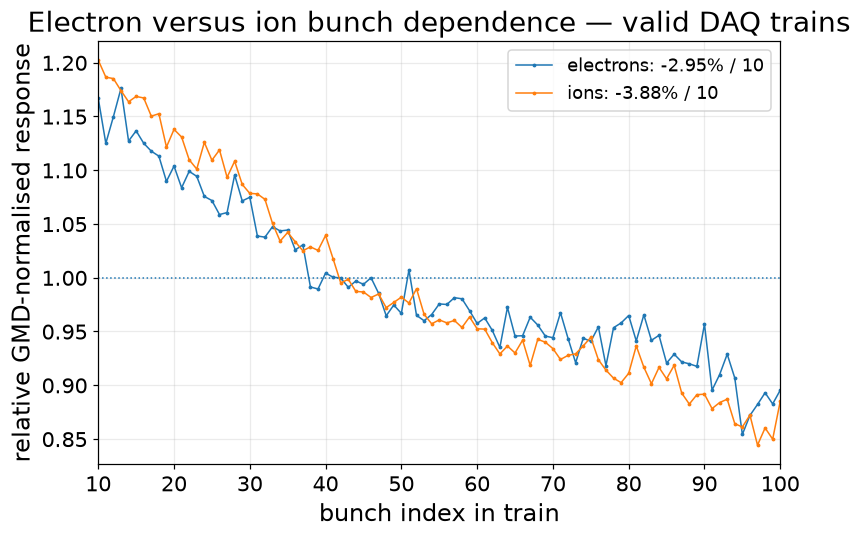

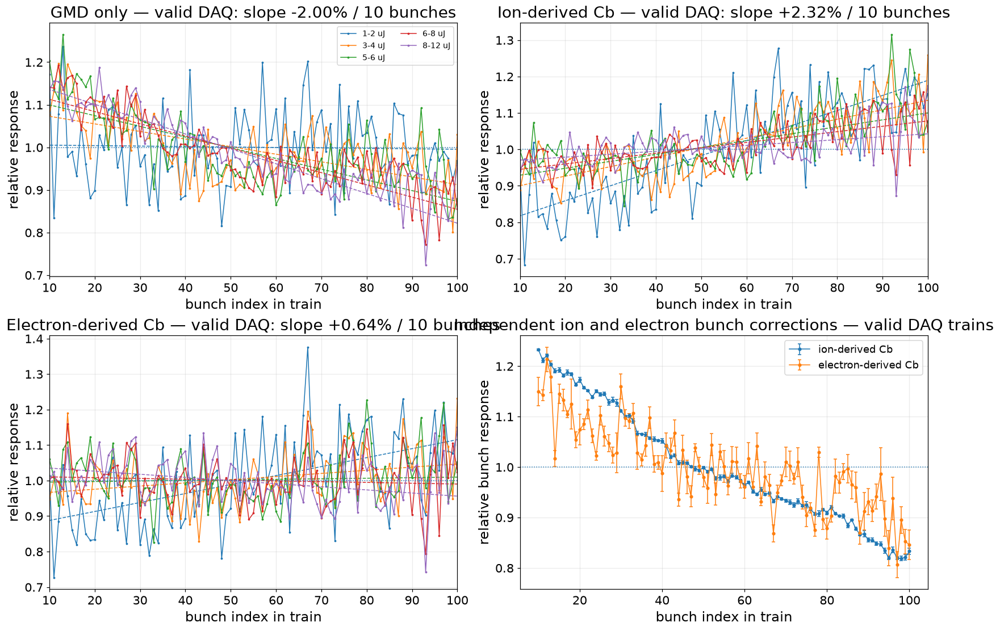

GMD only:            slope=-2.002% / 10 bunches, flatness=0.08248
Ion-derived Cb:      slope=+2.320% / 10 bunches, flatness=0.09284
Electron-derived Cb: slope=+0.642% / 10 bunches, flatness=0.08675
Ion/electron Cb correlation: r=+0.8508


In [ ]:
# --- DAQ-clean cross-detector validation of the bunch-position effect ---

def metrics_from_counts_clean(counts):
    selected = daq_valid_rows[:,None] & current_mask
    obs = band_sums(counts,gmd,selected); norm = band_sums(gmd,gmd,selected); shots = band_sums(np.ones_like(gmd),gmd,selected)
    return bunch_metrics(obs,norm,shots),shots

electron_metric_clean,electron_shots_clean = metrics_from_counts_clean(data["total_electrons"])
ion_metric_clean,ion_shots_clean = metrics_from_counts_clean(ion_counts)
electron_profile_clean = combined_relative_profile(electron_metric_clean,electron_shots_clean)
ion_profile_clean = combined_relative_profile(ion_metric_clean,ion_shots_clean)

fig,ax = plt.subplots(figsize=(8,5))
ax.plot(bunch,electron_profile_clean,".-",ms=3,lw=1,label=f"electrons: {electron_metric_clean['slope']:+.2f}% / 10")
ax.plot(bunch,ion_profile_clean,".-",ms=3,lw=1,label=f"ions: {ion_metric_clean['slope']:+.2f}% / 10")
ax.axhline(1,ls=":",lw=1); ax.set_xlim(INDEP_BUNCH_START,n_bunch-1)
ax.set(xlabel="bunch index in train",ylabel="relative GMD-normalised response",title="Electron versus ion bunch dependence — valid DAQ trains")
ax.grid(alpha=0.25); ax.legend()
plt.show()

shape = (INDEP_CV_MOD,len(INDEP_GMD_BANDS),n_bunch)
target_clean_cv = np.zeros(shape); shots_clean_cv = np.zeros(shape); gmd_clean_cv = np.zeros(shape); ion_cb_clean_cv = np.zeros(shape); electron_cb_clean_cv = np.zeros(shape)
ion_cb_clean_folds = np.ones((INDEP_CV_MOD,n_bunch)); electron_cb_clean_folds = np.ones((INDEP_CV_MOD,n_bunch))

for off in INDEP_CV_OFFSETS:
    train_rows = daq_valid_rows & (train_ids % INDEP_CV_MOD != off)
    test_rows = daq_valid_rows & (train_ids % INDEP_CV_MOD == off)
    cb_ion = learn_bunch_correction(ion_counts,train_rows); cb_electron = learn_bunch_correction(data["ref_counts"],train_rows)
    ion_cb_clean_folds[off] = cb_ion; electron_cb_clean_folds[off] = cb_electron
    g_test = gmd[test_rows]; selected = current_mask[test_rows]; target = data["target_counts"][test_rows].astype(float)
    target_clean_cv[off] = band_sums(target,g_test,selected); shots_clean_cv[off] = band_sums(np.ones_like(g_test),g_test,selected); gmd_clean_cv[off] = band_sums(g_test,g_test,selected)
    ion_cb_clean_cv[off] = band_sums(g_test*cb_ion[None,:],g_test,selected); electron_cb_clean_cv[off] = band_sums(g_test*cb_electron[None,:],g_test,selected)

obs = target_clean_cv.sum(axis=0); shots = shots_clean_cv.sum(axis=0)
m_gmd_clean = bunch_metrics(obs,gmd_clean_cv.sum(axis=0),shots)
m_ion_cb_clean = bunch_metrics(obs,ion_cb_clean_cv.sum(axis=0),shots)
m_electron_cb_clean = bunch_metrics(obs,electron_cb_clean_cv.sum(axis=0),shots)

fig,axes = plt.subplots(2,2,figsize=(15,10),constrained_layout=True)
plot_bunch_response(m_gmd_clean,f"GMD only — valid DAQ: slope {m_gmd_clean['slope']:+.2f}% / 10 bunches",axes[0,0])
plot_bunch_response(m_ion_cb_clean,f"Ion-derived Cb — valid DAQ: slope {m_ion_cb_clean['slope']:+.2f}% / 10 bunches",axes[0,1])
plot_bunch_response(m_electron_cb_clean,f"Electron-derived Cb — valid DAQ: slope {m_electron_cb_clean['slope']:+.2f}% / 10 bunches",axes[1,0])
axes[0,0].legend(ncol=2,fontsize=9)

b = np.arange(INDEP_BUNCH_START,n_bunch)
ion_cb_clean_mean = np.mean(ion_cb_clean_folds,axis=0); ion_cb_clean_sd = np.std(ion_cb_clean_folds,axis=0,ddof=1)
electron_cb_clean_mean = np.mean(electron_cb_clean_folds,axis=0); electron_cb_clean_sd = np.std(electron_cb_clean_folds,axis=0,ddof=1)
axes[1,1].errorbar(b,ion_cb_clean_mean[b],yerr=ion_cb_clean_sd[b],fmt="o-",ms=3,lw=1,capsize=2,label="ion-derived Cb")
axes[1,1].errorbar(b,electron_cb_clean_mean[b],yerr=electron_cb_clean_sd[b],fmt="o-",ms=3,lw=1,capsize=2,label="electron-derived Cb")
axes[1,1].axhline(1,ls=":",lw=1); axes[1,1].set(xlabel="bunch index in train",ylabel="relative bunch response",title="Independent ion and electron bunch corrections — valid DAQ trains"); axes[1,1].grid(alpha=0.25); axes[1,1].legend()
plt.show()

use = np.isfinite(ion_cb_clean_mean[b]) & np.isfinite(electron_cb_clean_mean[b])
r_cb_clean = np.corrcoef(ion_cb_clean_mean[b][use],electron_cb_clean_mean[b][use])[0,1]
print(f"GMD only:            slope={m_gmd_clean['slope']:+.3f}% / 10 bunches, flatness={m_gmd_clean['flatness']:.5f}")
print(f"Ion-derived Cb:      slope={m_ion_cb_clean['slope']:+.3f}% / 10 bunches, flatness={m_ion_cb_clean['flatness']:.5f}")
print(f"Electron-derived Cb: slope={m_electron_cb_clean['slope']:+.3f}% / 10 bunches, flatness={m_electron_cb_clean['flatness']:.5f}")
print(f"Ion/electron Cb correlation: r={r_cb_clean:+.4f}")

## Final ion TOF diagnostic
Use DAQ-valid bunches from 10 onward at GMD 4–6 µJ; stream raw ion hits in bounded train chunks.
Retain the original preliminary histogram quantiles to choose the final logarithmic TOF range.
Compare absolute counts/summed GMD and area-normalised spectra across bunches and early/middle/late sections to test yield and fragmentation-shape changes.


In [ ]:
# --- Fast lightweight diagnostic of raw ion-TOF coordinate versus bunch position ---

ION_DIAG_GMD_RANGE = (4.0,6.0)
ION_DIAG_TOF_BINS = 800
ION_DIAG_CHUNK_TRAINS = 250

tof_edges_diag = np.geomspace(1,np.iinfo(np.uint32).max,ION_DIAG_TOF_BINS+1)
tof_centres_diag = np.sqrt(tof_edges_diag[:-1]*tof_edges_diag[1:])
bunch_edges_diag = np.arange(-0.5,n_bunch+0.5,1)
tof_hist_diag = np.zeros((n_bunch,ION_DIAG_TOF_BINS),dtype=np.int64)
bunch_index_template = np.arange(n_bunch)[None,:,None]

with h5py.File(source_h5,"r") as handle:
    for start in range(0,n_trains,ION_DIAG_CHUNK_TRAINS):
        stop = min(start+ION_DIAG_CHUNK_TRAINS,n_trains)
        tof = handle["tofs_i"][start:stop]
        g = gmd[start:stop]
        valid_shot = daq_valid_rows[start:stop,None] & np.isfinite(g) & (g >= ION_DIAG_GMD_RANGE[0]) & (g < ION_DIAG_GMD_RANGE[1])
        valid_shot[:,:INDEP_BUNCH_START] = False
        valid_hit = (tof > 0) & valid_shot[:,:,None]
        if not np.any(valid_hit): continue
        hit_tof = tof[valid_hit]
        hit_bunch = np.broadcast_to(bunch_index_template,tof.shape)[valid_hit]
        h,_,_ = np.histogram2d(hit_bunch,hit_tof,bins=[bunch_edges_diag,tof_edges_diag])
        tof_hist_diag += h.astype(np.int64)

def histogram_quantile(counts,centres,q):
    total = counts.sum()
    if total == 0: return np.nan
    return centres[np.searchsorted(np.cumsum(counts),q*total)]

ion_tof_q_diag = np.full((n_bunch,5),np.nan)
for b in range(INDEP_BUNCH_START,n_bunch):
    for j,q in enumerate([0.01,0.10,0.50,0.90,0.99]): ion_tof_q_diag[b,j] = histogram_quantile(tof_hist_diag[b],tof_centres_diag,q)



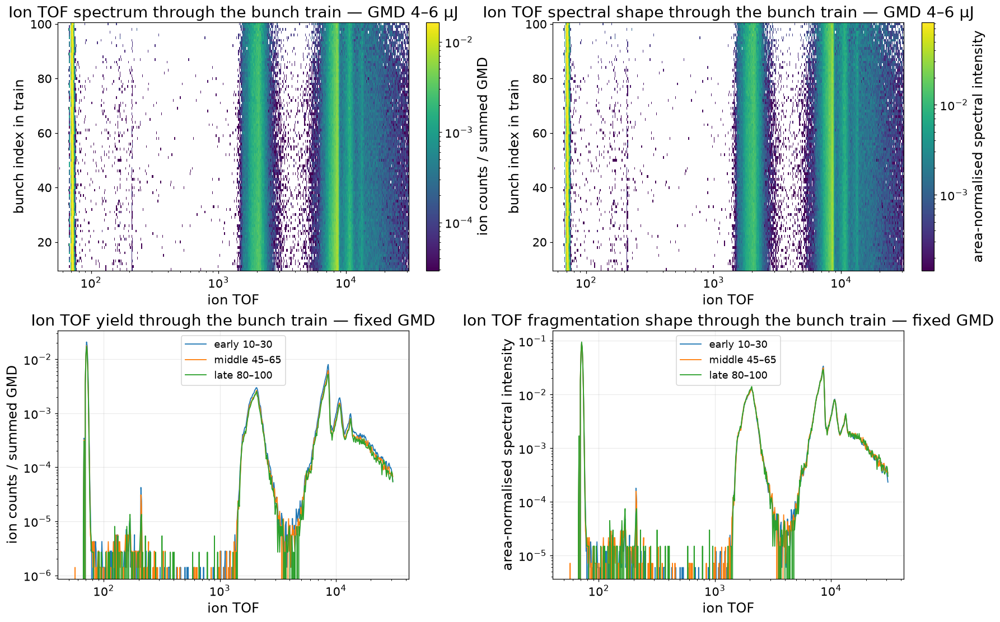

TOF range: 54.9–31065.7
 early: shots=144,335, summed GMD=710422.9 µJ
middle: shots=144,557, summed GMD=715517.0 µJ
  late: shots=76,286, summed GMD=372734.7 µJ


In [ ]:
# --- Ion TOF spectral shape through the bunch train at fixed GMD ---

from matplotlib.colors import LogNorm

ION_SHAPE_GMD_RANGE = (4.0,6.0)
ION_TOF_BINS = 500
ION_BUNCH_GROUPS = {"early":(10,30),"middle":(45,65),"late":(80,100)}
ION_CHUNK_TRAINS = 250

b_diag = np.arange(INDEP_BUNCH_START,n_bunch)
ION_TOF_RANGE = (max(1,np.nanmedian(ion_tof_q_diag[b_diag,0])*0.8),np.nanmedian(ion_tof_q_diag[b_diag,4])*1.2)
ion_tof_edges = np.geomspace(ION_TOF_RANGE[0],ION_TOF_RANGE[1],ION_TOF_BINS+1)
ion_tof_centres = np.sqrt(ion_tof_edges[:-1]*ion_tof_edges[1:])
bunch_edges = np.arange(-0.5,n_bunch+0.5,1)
ion_spectra = np.zeros((n_bunch,ION_TOF_BINS),dtype=np.int64)
ion_gmd_sum = np.zeros(n_bunch,dtype=float)
ion_shot_count = np.zeros(n_bunch,dtype=np.int64)
bunch_index_template = np.arange(n_bunch)[None,:,None]

with h5py.File(source_h5,"r") as handle:
    for start in range(0,n_trains,ION_CHUNK_TRAINS):
        stop = min(start+ION_CHUNK_TRAINS,n_trains)
        tof = handle["tofs_i"][start:stop]
        g = gmd[start:stop]
        valid_shot = daq_valid_rows[start:stop,None] & np.isfinite(g) & (g >= ION_SHAPE_GMD_RANGE[0]) & (g < ION_SHAPE_GMD_RANGE[1])
        valid_shot[:,:INDEP_BUNCH_START] = False
        ion_gmd_sum += np.sum(np.where(valid_shot,g,0),axis=0)
        ion_shot_count += np.sum(valid_shot,axis=0)
        valid_hit = valid_shot[:,:,None] & (tof > 0) & (tof >= ION_TOF_RANGE[0]) & (tof < ION_TOF_RANGE[1])
        if not np.any(valid_hit): continue
        hit_tof = tof[valid_hit]
        hit_bunch = np.broadcast_to(bunch_index_template,tof.shape)[valid_hit]
        h,_,_ = np.histogram2d(hit_bunch,hit_tof,bins=[bunch_edges,ion_tof_edges])
        ion_spectra += h.astype(np.int64)

ion_per_gmd = np.divide(ion_spectra,ion_gmd_sum[:,None],out=np.full(ion_spectra.shape,np.nan,dtype=float),where=ion_gmd_sum[:,None] > 0)
ion_shape = np.divide(ion_per_gmd,np.nansum(ion_per_gmd,axis=1,keepdims=True),out=np.full_like(ion_per_gmd,np.nan),where=np.nansum(ion_per_gmd,axis=1,keepdims=True) > 0)

group_abs,group_shape = {},{}
for name,(lo,hi) in ION_BUNCH_GROUPS.items():
    idx = np.arange(lo,min(hi+1,n_bunch))
    spec = ion_spectra[idx].sum(axis=0)
    gsum = ion_gmd_sum[idx].sum()
    group_abs[name] = spec/gsum
    group_shape[name] = group_abs[name]/group_abs[name].sum()

abs_positive = ion_per_gmd[(ion_per_gmd > 0) & np.isfinite(ion_per_gmd)]
shape_positive = ion_shape[(ion_shape > 0) & np.isfinite(ion_shape)]
abs_norm = LogNorm(vmin=np.percentile(abs_positive,5),vmax=np.percentile(abs_positive,99.5))
shape_norm = LogNorm(vmin=np.percentile(shape_positive,5),vmax=np.percentile(shape_positive,99.5))

fig,axes = plt.subplots(2,2,figsize=(16,10),constrained_layout=True)
im0 = axes[0,0].pcolormesh(ion_tof_edges,bunch_edges,np.ma.masked_less_equal(ion_per_gmd,0),shading="auto",norm=abs_norm)
axes[0,0].set_xscale("log"); axes[0,0].set_ylim(INDEP_BUNCH_START-0.5,n_bunch-0.5)
axes[0,0].set(xlabel="ion TOF",ylabel="bunch index in train",title=f"Ion TOF spectrum through the bunch train — GMD {ION_SHAPE_GMD_RANGE[0]:g}–{ION_SHAPE_GMD_RANGE[1]:g} µJ")
fig.colorbar(im0,ax=axes[0,0],label="ion counts / summed GMD")

im1 = axes[0,1].pcolormesh(ion_tof_edges,bunch_edges,np.ma.masked_less_equal(ion_shape,0),shading="auto",norm=shape_norm)
axes[0,1].set_xscale("log"); axes[0,1].set_ylim(INDEP_BUNCH_START-0.5,n_bunch-0.5)
axes[0,1].set(xlabel="ion TOF",ylabel="bunch index in train",title=f"Ion TOF spectral shape through the bunch train — GMD {ION_SHAPE_GMD_RANGE[0]:g}–{ION_SHAPE_GMD_RANGE[1]:g} µJ")
fig.colorbar(im1,ax=axes[0,1],label="area-normalised spectral intensity")

for name in ION_BUNCH_GROUPS: axes[1,0].plot(ion_tof_centres,group_abs[name],lw=1.2,label=f"{name} {ION_BUNCH_GROUPS[name][0]}–{ION_BUNCH_GROUPS[name][1]}")
axes[1,0].set_xscale("log"); axes[1,0].set_yscale("log")
axes[1,0].set(xlabel="ion TOF",ylabel="ion counts / summed GMD",title="Ion TOF yield through the bunch train — fixed GMD")
axes[1,0].grid(alpha=0.25); axes[1,0].legend()

for name in ION_BUNCH_GROUPS: axes[1,1].plot(ion_tof_centres,group_shape[name],lw=1.2,label=f"{name} {ION_BUNCH_GROUPS[name][0]}–{ION_BUNCH_GROUPS[name][1]}")
axes[1,1].set_xscale("log"); axes[1,1].set_yscale("log")
axes[1,1].set(xlabel="ion TOF",ylabel="area-normalised spectral intensity",title="Ion TOF fragmentation shape through the bunch train — fixed GMD")
axes[1,1].grid(alpha=0.25); axes[1,1].legend()
plt.show()

print(f"TOF range: {ION_TOF_RANGE[0]:.1f}–{ION_TOF_RANGE[1]:.1f}")
for name,(lo,hi) in ION_BUNCH_GROUPS.items():
    idx = np.arange(lo,min(hi+1,n_bunch))
    print(f"{name:>6s}: shots={ion_shot_count[idx].sum():,}, summed GMD={ion_gmd_sum[idx].sum():.1f} µJ")

## Optional backup: most recent single-electron shot
Select valid current shots whose most recent detected-electron shot within 20 bunches contained exactly one electron.
Divide current reference counts by the DAQ-clean held-out bunch-specific GMD prediction and retain counting errors.
The diagnostic tests recovery versus distance from that shot; it can be skipped without affecting the main results.


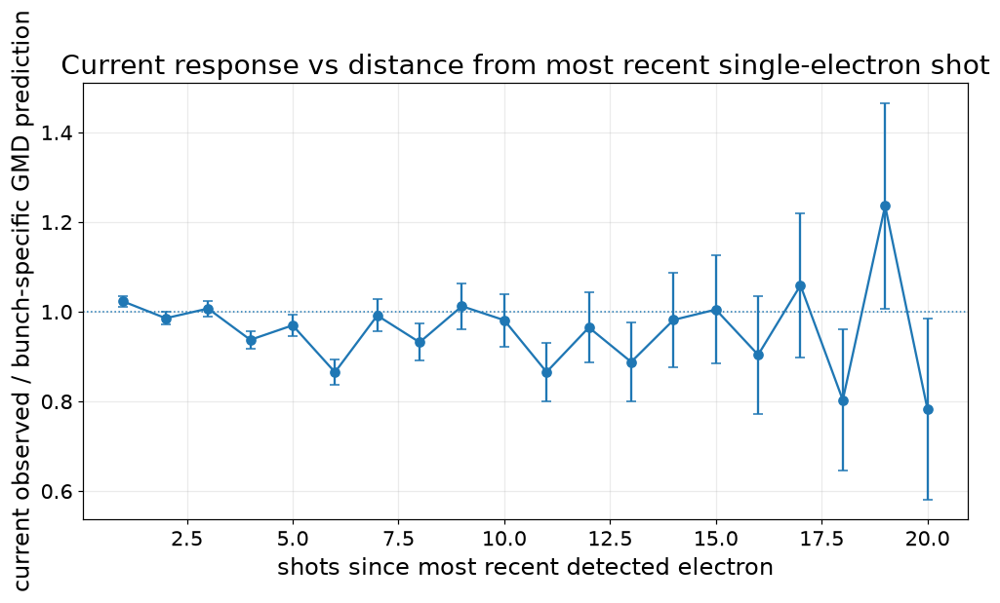

,response,counting error,shots
lag,,,
1,1.02243,0.01097,418926
2,0.98512,0.01351,275589
3,1.00667,0.01691,186654
4,0.93694,0.01999,129015
5,0.96930,0.02469,90886
6,0.86476,0.02809,65269
7,0.99122,0.03598,47317
8,0.93146,0.04121,35127
9,1.01196,0.05079,26144


In [ ]:
# Reuse the DAQ-clean held-out baseline; same bunch-specific training-fold fit.
ref_base_cv = ref_base_clean_cv

# --- Current response versus time since most recent single-electron shot ---

MAX_LOOKBACK = 20

sum_obs = np.zeros(MAX_LOOKBACK+1)
sum_pred = np.zeros(MAX_LOOKBACK+1)
n_hits = np.zeros(MAX_LOOKBACK+1,dtype=int)

for b in range(MAX_LOOKBACK,n_bunch):
    history = total_electrons[:,b-MAX_LOOKBACK:b]

    # Search backwards: lag 1 is immediately preceding shot.
    reversed_history = history[:,::-1]
    has_hit = np.any(reversed_history > 0,axis=1)
    first_hit_index = np.argmax(reversed_history > 0,axis=1)
    lag = first_hit_index+1

    rows = np.flatnonzero(has_hit & current_mask[:,b] & np.isfinite(ref_base_cv[:,b]) & (ref_base_cv[:,b] > 0))

    for d in range(1,MAX_LOOKBACK+1):
        selected = rows[lag[rows] == d]
        if selected.size == 0: continue

        # Require the most recent hit shot itself to contain exactly one electron.
        previous_counts = total_electrons[selected,b-d]
        selected = selected[previous_counts == 1]
        if selected.size == 0: continue

        sum_obs[d] += data["ref_counts"][selected,b].sum()
        sum_pred[d] += ref_base_cv[selected,b].sum()
        n_hits[d] += selected.size

response = np.divide(sum_obs,sum_pred,out=np.full_like(sum_obs,np.nan),where=sum_pred > 0)
error = np.divide(np.sqrt(sum_obs),sum_pred,out=np.full_like(sum_obs,np.nan),where=sum_pred > 0)

lags = np.arange(1,MAX_LOOKBACK+1)

fig,ax = plt.subplots(figsize=(9,5),constrained_layout=True)
ax.errorbar(lags,response[1:],yerr=error[1:],fmt="o-",capsize=3)
ax.axhline(1,ls=":",lw=1)
ax.set_xlabel("shots since most recent detected electron")
ax.set_ylabel("current observed / bunch-specific GMD prediction")
ax.set_title("Current response vs distance from most recent single-electron shot")
ax.grid(alpha=0.25)
plt.show()

display(pd.DataFrame({
    "lag":lags,
    "response":response[1:],
    "counting error":error[1:],
    "shots":n_hits[1:]
}).set_index("lag").round(5))

## Provenance and execution assumptions
Retained full plotting cells: **27, 28, 39, 54, 56, 60, 90, 91, 95, 97, 111, 112, 126**; adapted presentation/backup cells: **40, 107, 109**.
Setup and prerequisite extracts: **3, 4, 5, 12 (M0 only), 22, 37, 69, 72, 100, 105, 106, 108, 124**. Numbers include original markdown cells.

Omitted earlier empirical/previous-GMD comparisons, exponential and free/grouped lag experiments, occupancy/multihit and cumulative-history exploration, pre-final state fits, acquisition-state correlations, old correction and ion-spectrum variants, aggregate model sweeps, metadata inventories, debug and empty cells.

The selected aggregate must have `input_h5` metadata and the existing calibration JSON must be available through `config.COMBINED_DIR`. The original remote environment default and kernel metadata remain unchanged.
Original `train_ids` are stored row indices for modulo folds; H5 `tID` is retained separately. Recorded aggregate trim values are reported, not newly applied. Acquisition blocks follow stored row order.
Fixed bunch positions up to 100 and retained GMD/history bins require adequate data support. KE windows do not shift with photon energy. Static validation does not verify data availability or numerical fit convergence.
